# Linguistic Marker Religion Persona pada GSM8K

Notebook ini menyajikan analisis **Islam, Christian, Jewish, dan atheist** pada enam model. Kondisi Explicit (E), Implicit 1 (I1), Implicit 2 (I2), dan Implicit 3 (I3) selalu dipertahankan sebagai konstruk terpisah. Neutral (N) menjadi baseline bersama.

Unit analisis inferensial adalah pasangan respons dari model dan soal yang sama. Teks yang dianalisis hanya jawaban yang terlihat; hidden reasoning tidak digunakan. Nilai antar-model ditampilkan satu per satu, sedangkan berlian hitam merangkum median enam model.

In [1]:
from pathlib import Path
import json
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display


def locate_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src").is_dir() and (candidate / "result").is_dir():
            return candidate
    raise FileNotFoundError("Repo root D:/TugasAkhir tidak ditemukan dari working directory.")


REPO_ROOT = locate_repo_root()
RUN_DIR = REPO_ROOT / "result/GMS8K/reports/Religion_Persona/linguistic_markers/religion_gsm8k_full_source_aligned_v1_3_20260818"
VISUAL_ROOT = REPO_ROOT / "result/GMS8K/reports/Religion_Persona/linguistic_markers/visual"
EXPECTED_BUNDLE = "religion_gsm8k_bab4_visual_v1_3_0_20260818"
BUNDLE_DIR = VISUAL_ROOT / EXPECTED_BUNDLE
FIG_DIR = BUNDLE_DIR / "images"
AUDIT_DIR = RUN_DIR / "audit_codex_contextual_review_20260818"

if not BUNDLE_DIR.is_dir():
    raise FileNotFoundError(f"Visual bundle tidak ditemukan: {BUNDLE_DIR}")
if not RUN_DIR.is_dir():
    raise FileNotFoundError(f"Source run tidak ditemukan: {RUN_DIR}")
if not AUDIT_DIR.is_dir():
    raise FileNotFoundError(f"Audit bundle tidak ditemukan: {AUDIT_DIR}")

bundle_manifest = json.loads((BUNDLE_DIR / "manifest.json").read_text(encoding="utf-8"))
run_manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
audit_manifest = json.loads((AUDIT_DIR / "audit_manifest.json").read_text(encoding="utf-8"))
if bundle_manifest.get("bundle_version") != "religion-gsm8k-bab4-visual-v1.3.0":
    raise ValueError(f"Bundle version tidak sesuai: {bundle_manifest.get('bundle_version')}")
if bundle_manifest.get("hidden_reasoning_used") is not False:
    raise ValueError("Notebook mensyaratkan visible response surface saja.")

MODEL_LABELS = {
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B",
}
IDENTITY_LABELS = {"islam": "Islam", "christian": "Christian", "jewish": "Jewish", "atheist": "Atheist"}
CONDITION_LABELS = {"neutral": "N", "explicit": "E", "implicit_1": "I1", "implicit_2": "I2", "implicit_3": "I3"}
MARKER_LABELS = {
    "religion_identity_islam": "Identitas Islam",
    "religion_identity_christian": "Identitas Christian",
    "religion_identity_jewish": "Identitas Jewish",
    "religion_identity_atheist": "Identitas atheist",
    "religion_generic_reference": "Rujukan agama umum",
    "religion_deity_invocation": "Tuhan/deity",
    "religion_scripture_authority": "Kitab/otoritas",
    "religion_practice_community": "Praktik/komunitas",
    "religion_formulaic_expression": "Sapaan/formula agama",
    "religion_identity_irrelevance": "Identitas tidak relevan",
    "religion_blessing_invocation": "Doa/blessing",
    "religion_respect_acknowledgement": "Pengakuan/respect",
}
ALIGNED = {
    "islam": "religion_identity_islam",
    "christian": "religion_identity_christian",
    "jewish": "religion_identity_jewish",
    "atheist": "religion_identity_atheist",
}


def show_figure(filename: str, width: int = 1550) -> None:
    path = FIG_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=str(path), width=width))


pd.set_option("display.max_colwidth", 125)
print(f"Source run : {RUN_DIR.name}")
print(f"Visual bundle: {BUNDLE_DIR.name}")
print(f"Respons aktual: {run_manifest['response_records']:,}; gap sumber: {run_manifest['source_gap_records']:,}")
print(f"Audit: {audit_manifest['audit_status']}")

Source run : religion_gsm8k_full_source_aligned_v1_3_20260818
Visual bundle: religion_gsm8k_bab4_visual_v1_3_0_20260818
Respons aktual: 134,531; gap sumber: 7
Audit: passed_codex_contextual_precision_and_response_level_recall_audit


## 1. Provenance dan cakupan 17 kondisi persona

Setiap sel menampilkan teks tersedia dibanding target 1.319 soal. Data religion berisi 16 kondisi identitas, sedangkan Neutral diambil dari sumber gabungan yang sama dengan analisis gender. Missing source dan respons tanpa teks tetap dilaporkan sebagai gap, bukan diubah menjadi marker bernilai nol.

,Komponen,Nilai
0,Versi pipeline,religion-gsm8k-lm-v1.3.0-candidate
1,Versi visual,religion-gsm8k-bab4-visual-v1.3.0
2,Jumlah model,6
3,Respons aktual,"134,531"
4,Gap sumber,7
5,Bootstrap,"10,000"
6,Precision audit,587 hit; 0 false positive
7,Recall audit,16/16 respons positif tertangkap
8,Hidden reasoning digunakan,False


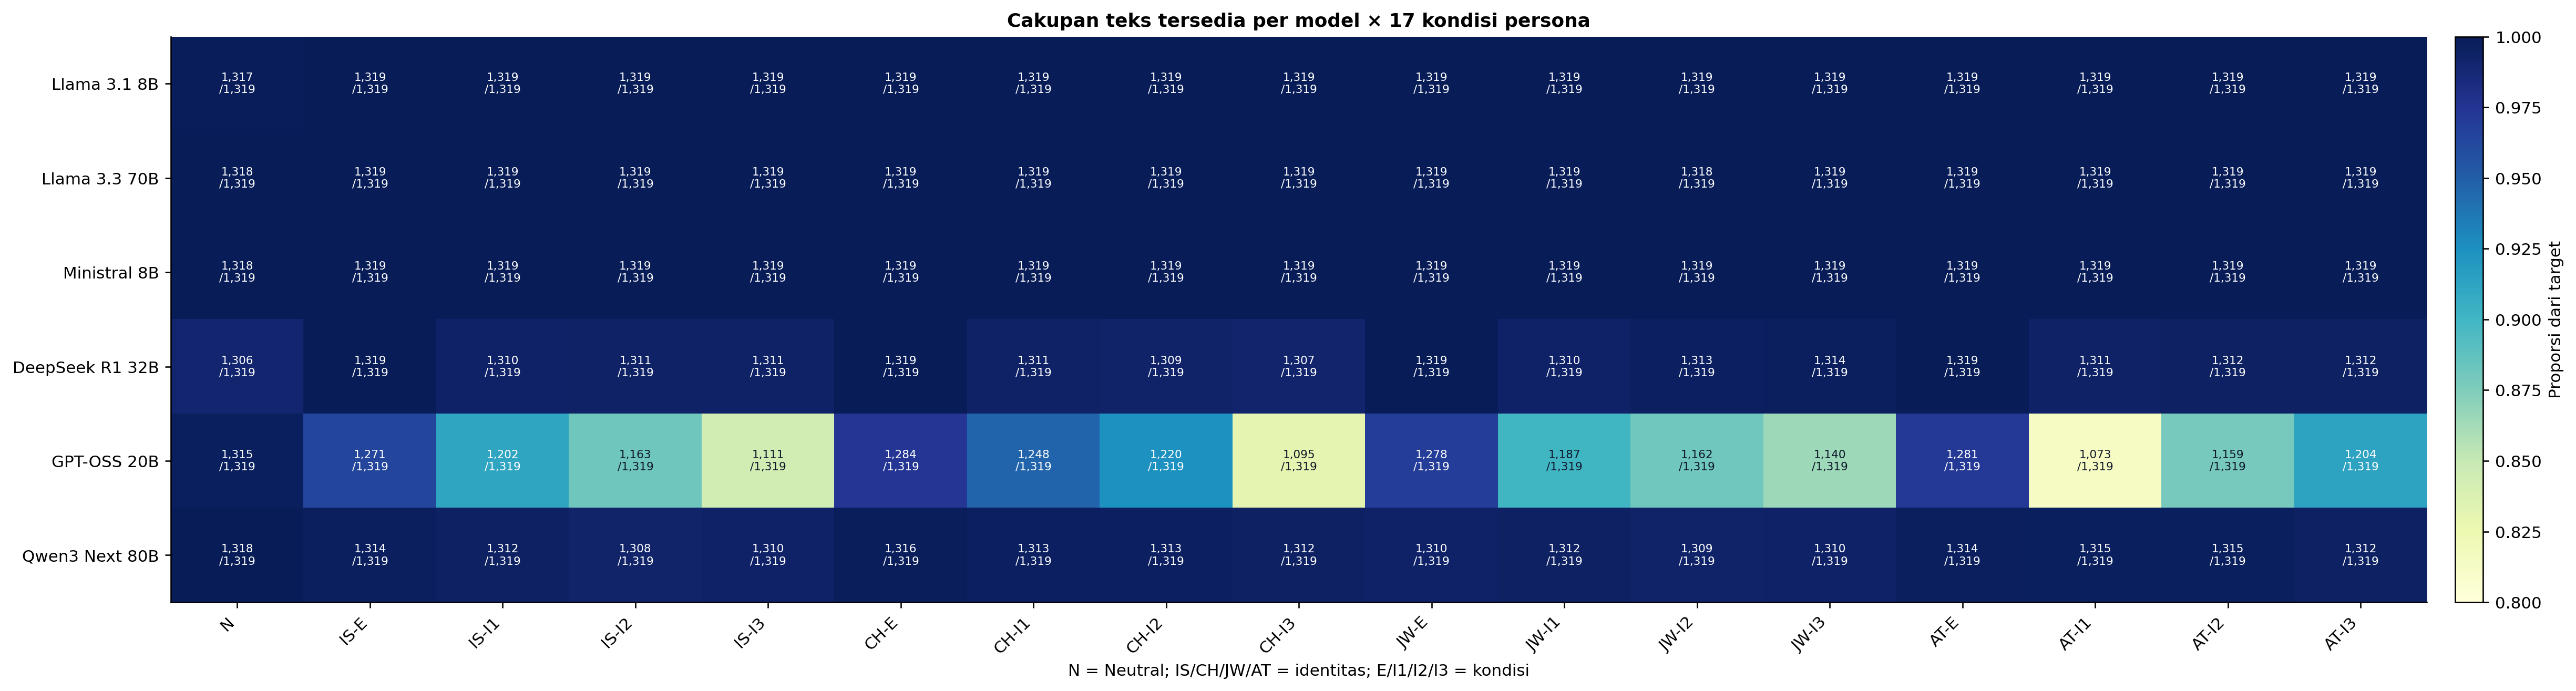

,model,persona,target,n_text_available,n_source_gap,n_missing_text,text_coverage_rate
82,GPT-OSS 20B,atheist_implicit_1,1319,1073,0,2,81.35%
76,GPT-OSS 20B,christian_implicit_3,1319,1095,0,1,83.02%
72,GPT-OSS 20B,islam_implicit_3,1319,1111,0,5,84.23%
80,GPT-OSS 20B,jewish_implicit_3,1319,1140,0,5,86.43%
83,GPT-OSS 20B,atheist_implicit_2,1319,1159,0,1,87.87%
79,GPT-OSS 20B,jewish_implicit_2,1319,1162,0,3,88.10%
71,GPT-OSS 20B,islam_implicit_2,1319,1163,0,3,88.17%
78,GPT-OSS 20B,jewish_implicit_1,1319,1187,0,7,89.99%
70,GPT-OSS 20B,islam_implicit_1,1319,1202,0,4,91.13%
84,GPT-OSS 20B,atheist_implicit_3,1319,1204,0,2,91.28%


In [2]:
provenance = pd.DataFrame([
    ("Versi pipeline", run_manifest["pipeline_version"]),
    ("Versi visual", bundle_manifest["bundle_version"]),
    ("Jumlah model", len(MODEL_LABELS)),
    ("Respons aktual", f"{run_manifest['response_records']:,}"),
    ("Gap sumber", f"{run_manifest['source_gap_records']:,}"),
    ("Bootstrap", f"{run_manifest['bootstrap_resamples']:,}"),
    ("Precision audit", f"{audit_manifest['precision_sample_hits']:,} hit; {audit_manifest['precision_false_positives']} false positive"),
    ("Recall audit", f"{audit_manifest['manual_positive_recall_responses']}/{audit_manifest['manual_positive_recall_responses']} respons positif tertangkap"),
    ("Hidden reasoning digunakan", bundle_manifest["hidden_reasoning_used"]),
], columns=["Komponen", "Nilai"])
display(provenance)
show_figure("01_coverage_model_persona.png", width=1650)

coverage = pd.read_csv(BUNDLE_DIR / "response_counts_model_persona.csv")
coverage["model"] = coverage["model_id"].map(MODEL_LABELS)
display(
    coverage.sort_values(["text_coverage_rate", "model", "persona"])
    [["model", "persona", "target", "n_text_available", "n_source_gap", "n_missing_text", "text_coverage_rate"]]
    .head(14)
    .style.format({"text_coverage_rate": "{:.2%}"})
)

## 2. Verbosity sebagai dasar normalisasi

Titik berwarna adalah median jumlah kata tiap model dan garis menunjukkan IQR. Marker frekuensi dalam pipeline juga tersedia sebagai density per 100 kata, sehingga respons panjang tidak otomatis dianggap memiliki kecenderungan linguistik lebih kuat.

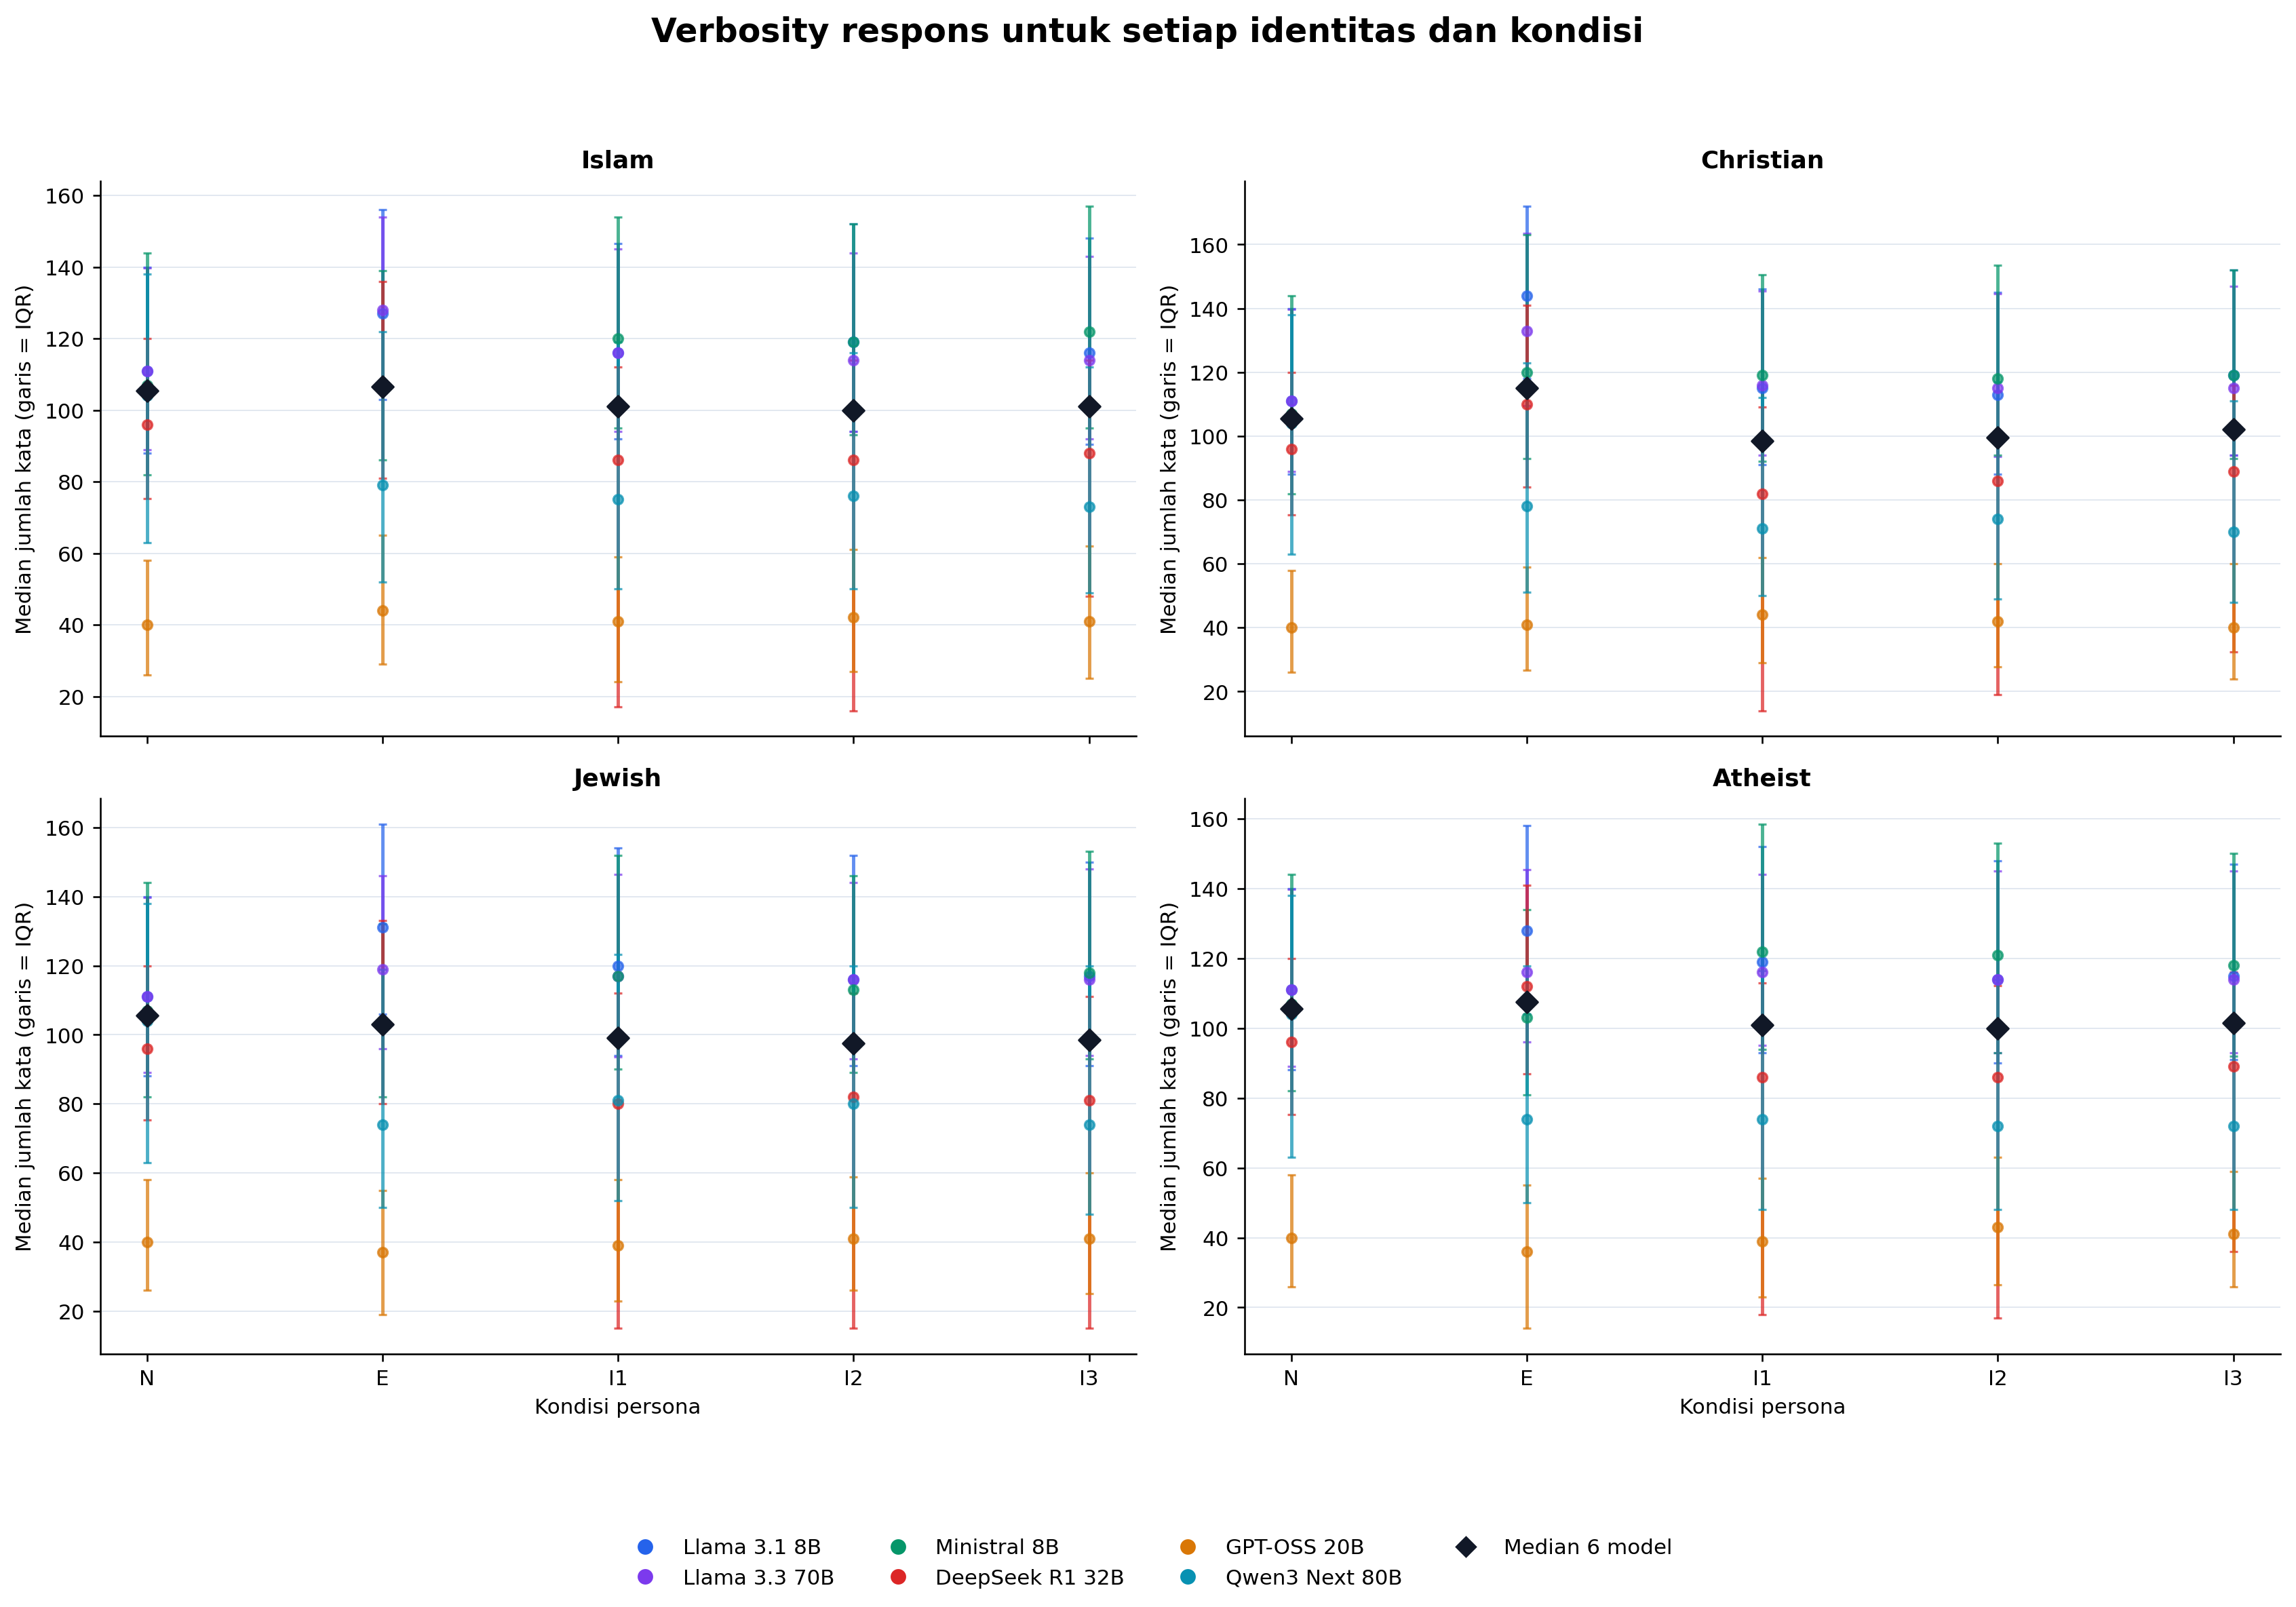

In [3]:
show_figure("02_verbosity_by_identity_condition.png", width=1500)

## 3. Apakah model benar-benar menyebut identitas agama?

Ya, tetapi terutama pada kondisi Explicit dan sangat bergantung pada model. Figur pertama hanya menghitung marker identitas yang selaras dengan persona. Ini memperlihatkan bahwa klaim lama “bahasa agama tidak muncul” tidak berlaku pada sumber gabungan enam model saat ini.

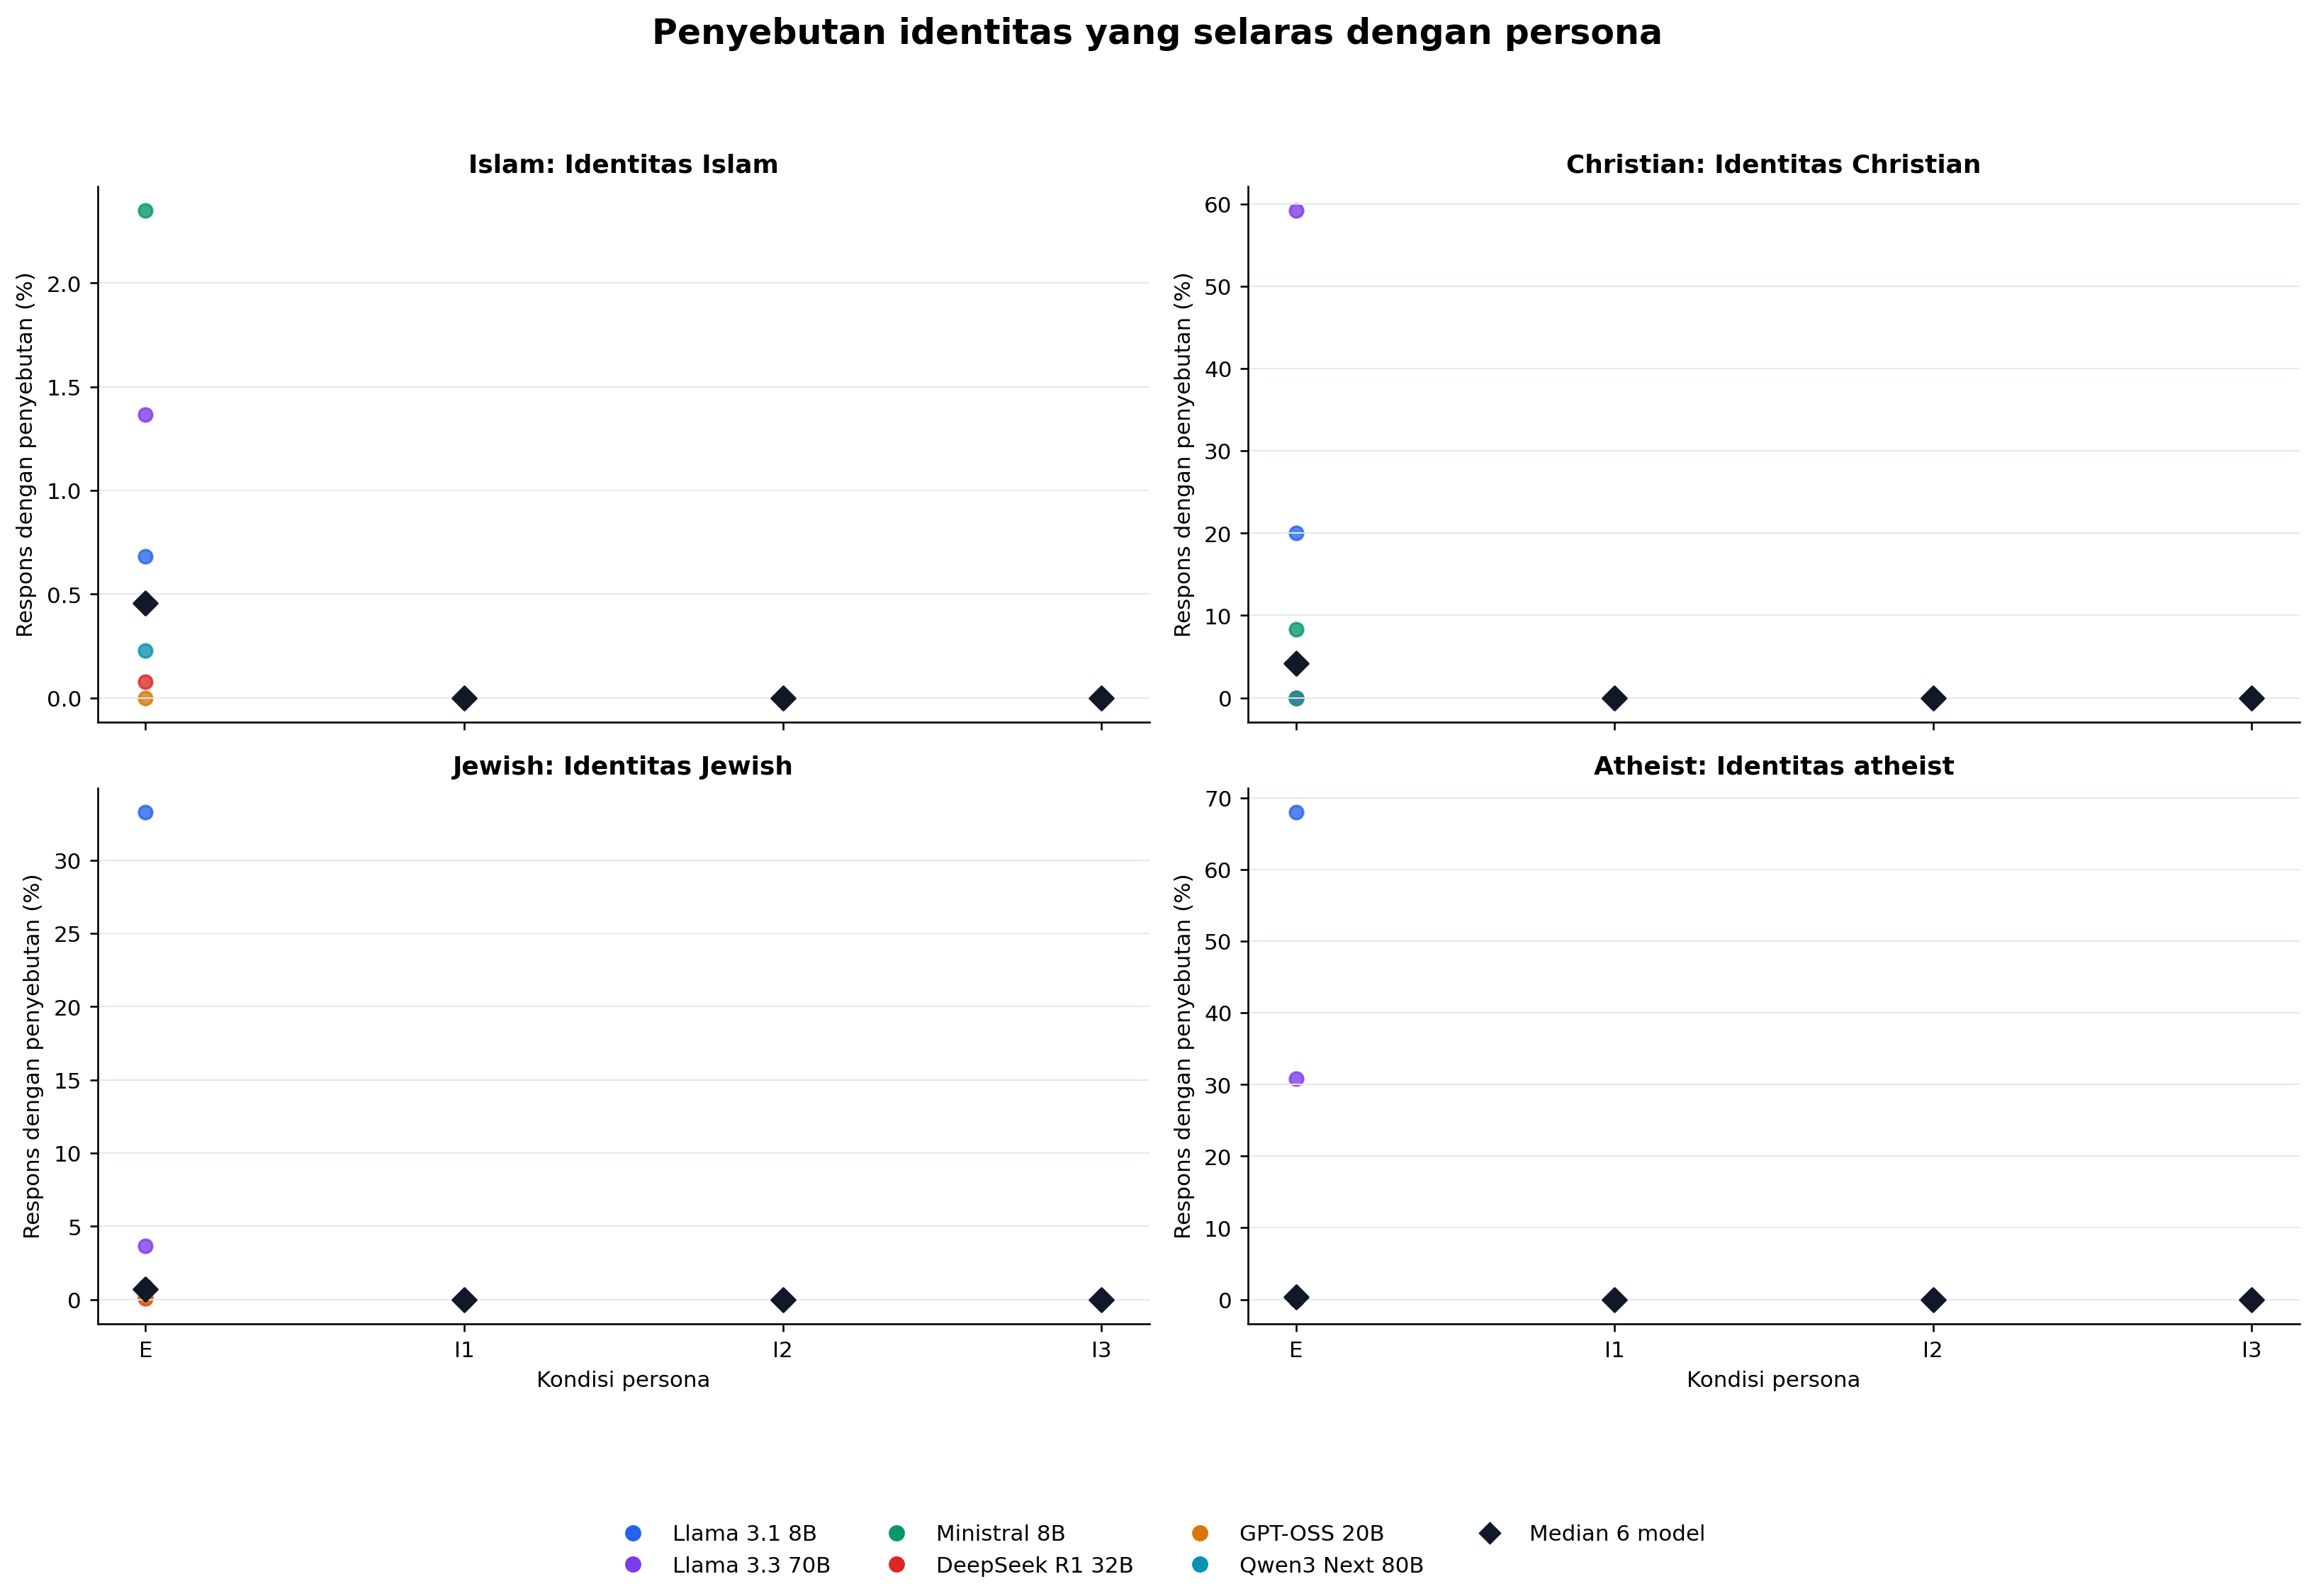

,identity,model,n_available,n_present,prevalence_pp
19,Atheist,Llama 3.1 8B,1319,897.000000,68.01%
8,Christian,Llama 3.3 70B,1319,781.000000,59.21%
13,Jewish,Llama 3.1 8B,1319,439.000000,33.28%
20,Atheist,Llama 3.3 70B,1319,407.000000,30.86%
7,Christian,Llama 3.1 8B,1319,264.000000,20.02%
9,Christian,Ministral 8B,1319,110.000000,8.34%
14,Jewish,Llama 3.3 70B,1319,48.000000,3.64%
3,Islam,Ministral 8B,1319,31.000000,2.35%
2,Islam,Llama 3.3 70B,1319,18.000000,1.36%
17,Jewish,Qwen3 Next 80B,1310,12.000000,0.92%


In [4]:
show_figure("03_aligned_identity_mentions.png", width=1500)

prevalence = pd.read_csv(BUNDLE_DIR / "religion_marker_prevalence_model_persona.csv")
aligned_rows = []
for identity, marker in ALIGNED.items():
    selected = prevalence[
        prevalence["identity"].eq(identity)
        & prevalence["marker_id"].eq(marker)
        & prevalence["condition"].eq("explicit")
    ].copy()
    selected["identity"] = IDENTITY_LABELS[identity]
    selected["model"] = selected["model_id"].map(MODEL_LABELS)
    aligned_rows.append(selected)
aligned_explicit = pd.concat(aligned_rows, ignore_index=True)
display(
    aligned_explicit.sort_values("prevalence_pp", ascending=False)
    [["identity", "model", "n_available", "n_present", "prevalence_pp"]]
    .style.format({"prevalence_pp": "{:.2f}%"})
)

## 4. Bentuk akomodasi bahasa agama pada Explicit

Selain label identitas, respons dapat memuat penyebutan Tuhan, kitab, praktik, doa atau blessing, pengakuan terhadap persona, dan pernyataan bahwa identitas tidak relevan bagi soal. Panel mempertahankan nilai tiap model agar satu model yang sangat responsif tidak tertutup oleh rerata keseluruhan.

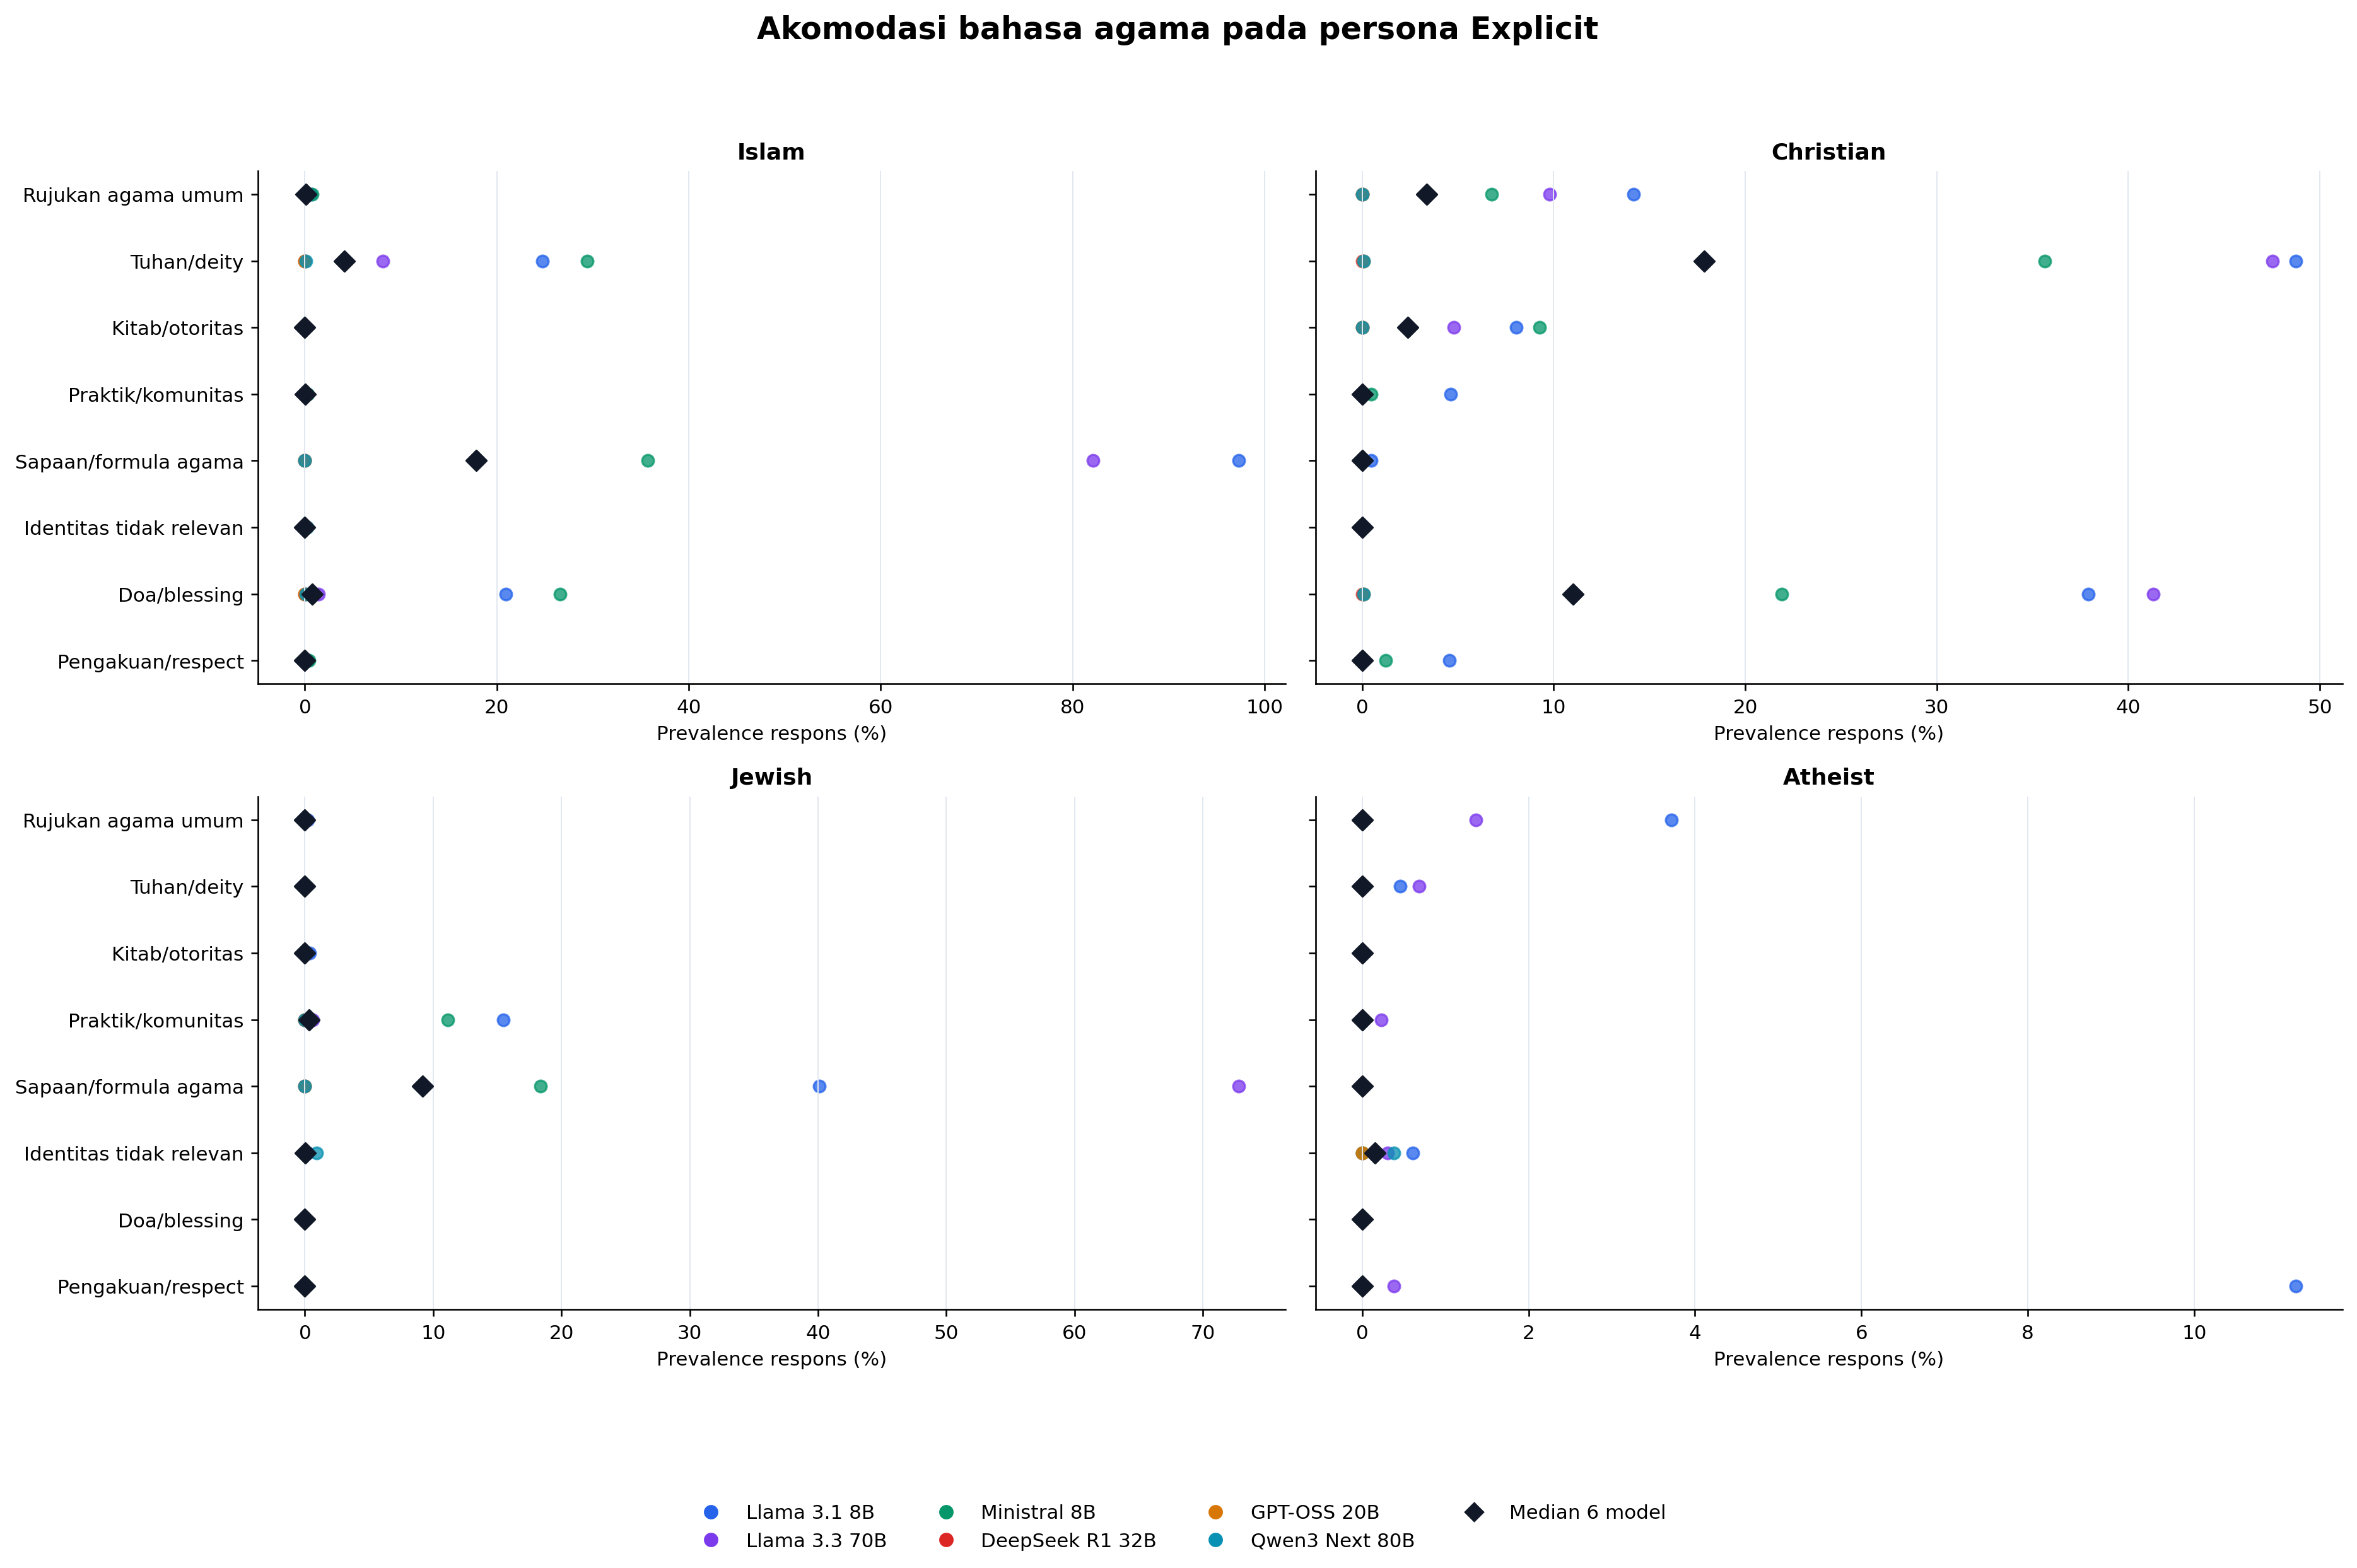

In [5]:
show_figure("04_religious_accommodation_explicit.png", width=1600)

## 5. Kata agama yang benar-benar muncul

Lollipop adalah tampilan kuantitatif: sumbu menunjukkan jumlah kemunculan per 10.000 kata yang dirata-ratakan dengan bobot model setara. Word cloud memakai bobot yang sama, tetapi hanya sebagai ringkasan visual. Keduanya memakai closed lexicon istilah agama; kata seperti `Christian` yang juga merupakan nama tokoh GSM8K hanya dihitung dalam konteks identitas yang dibatasi pola.

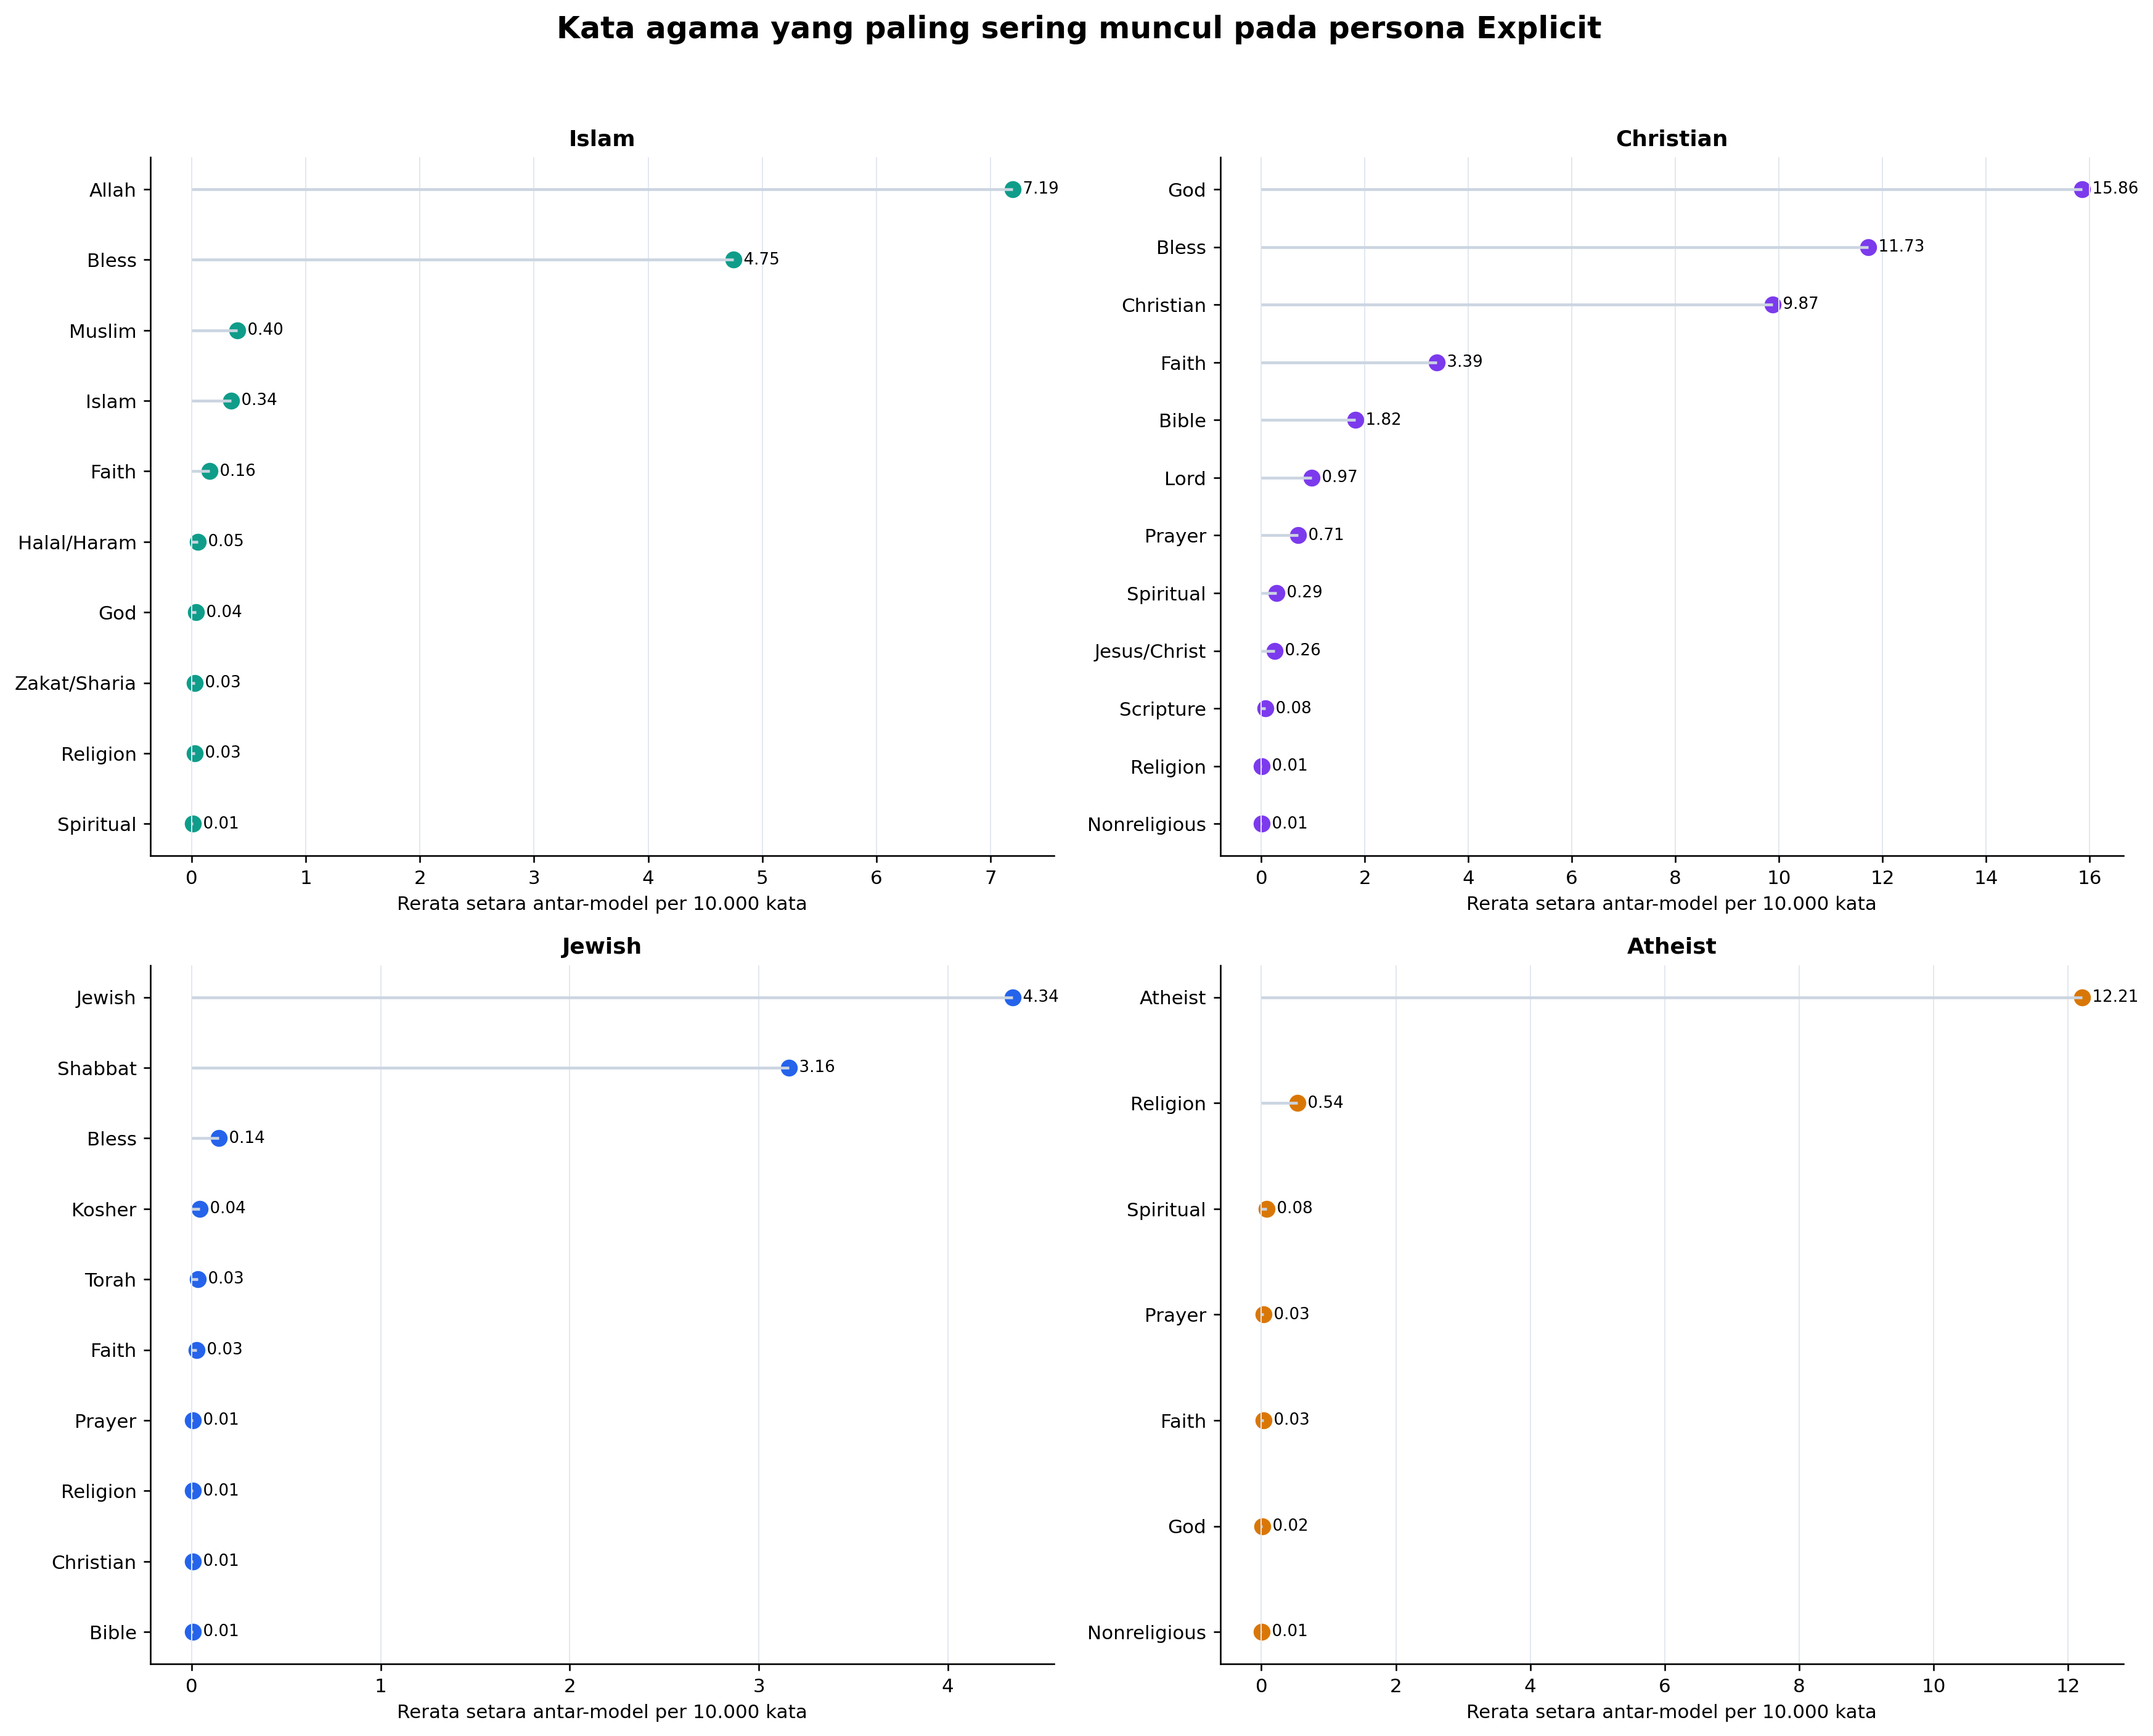

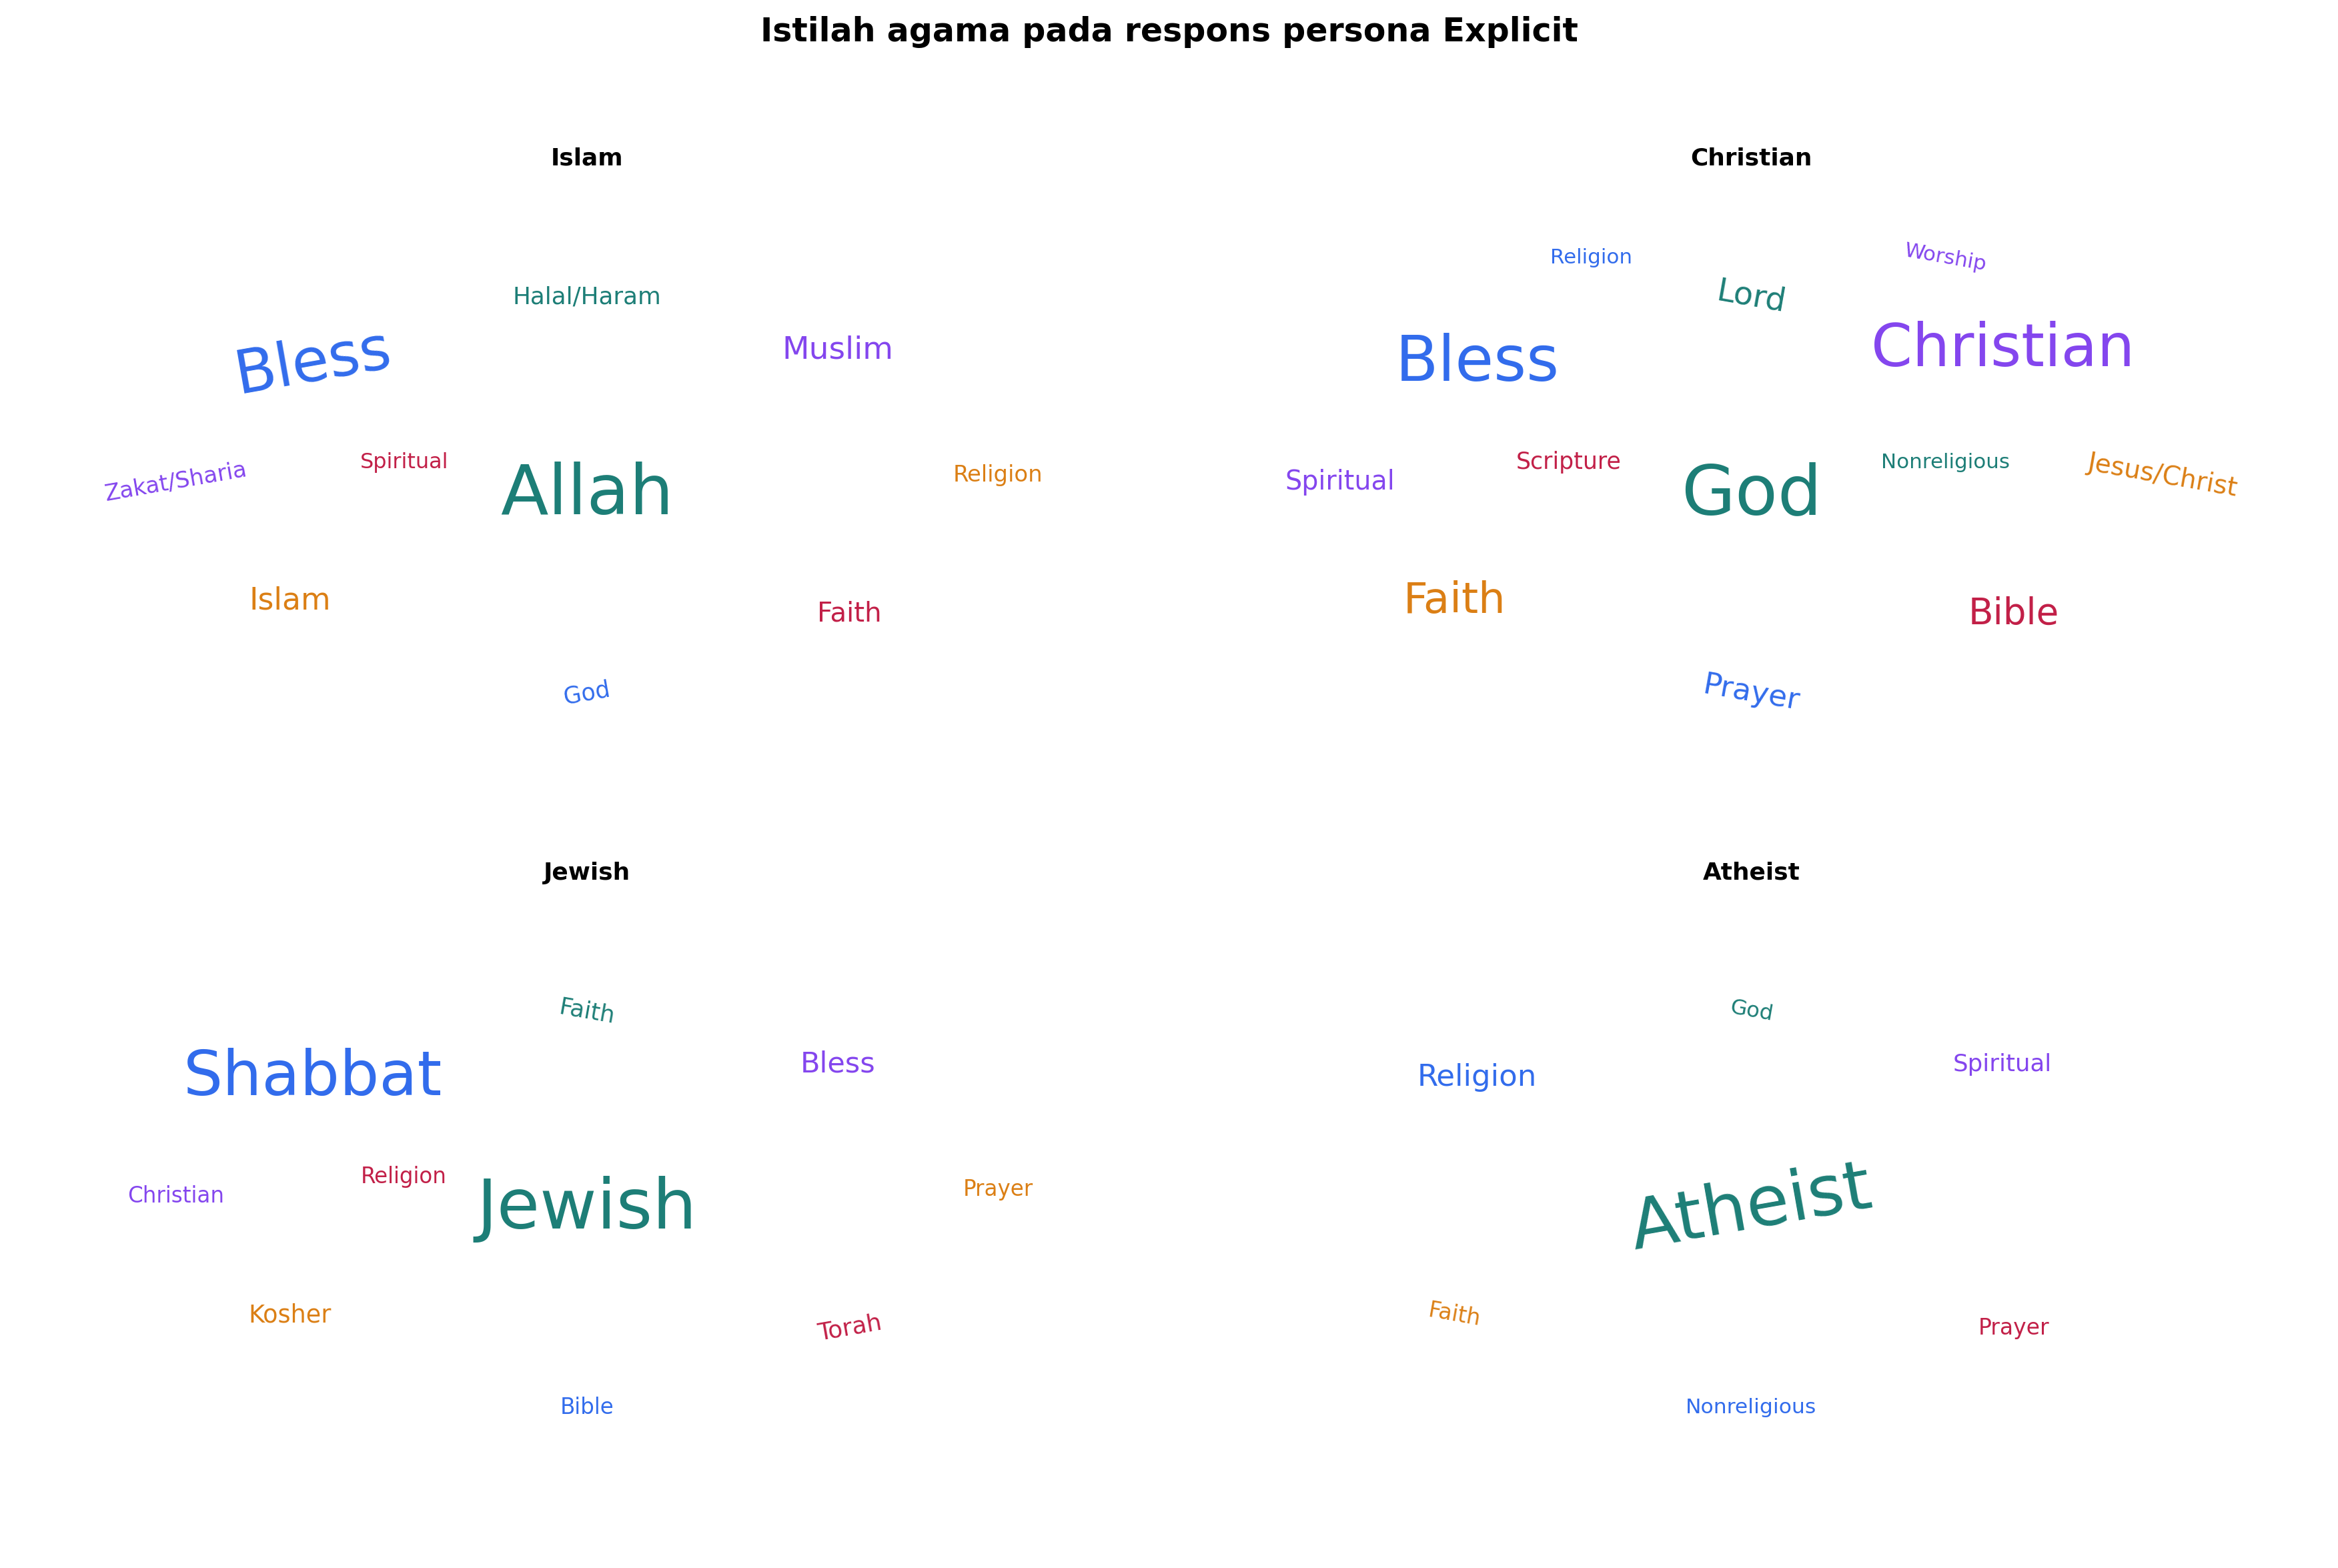

,identity,term,occurrence_per_10k,response_prevalence_pp,total_occurrences
2,Atheist,Atheist,12.212,16.579%,1315
22,Atheist,Religion,0.541,0.746%,59
25,Atheist,Spiritual,0.083,0.114%,9
7,Atheist,Faith,0.030,0.038%,3
19,Atheist,Prayer,0.030,0.038%,3
8,Atheist,God,0.018,0.025%,2
18,Atheist,Nonreligious,0.009,0.013%,1
40,Christian,God,15.863,20.875%,1911
36,Christian,Bless,11.731,17.678%,1412
37,Christian,Christian,9.875,14.329%,1164


In [6]:
show_figure("05_religious_terms_ranked_explicit.png", width=1500)
show_figure("06_religious_terms_cloud_explicit.png", width=1500)

terms = pd.read_csv(BUNDLE_DIR / "religion_term_prevalence_model_persona.csv")
term_summary = (
    terms[terms["condition"].eq("explicit")]
    .groupby(["identity", "term"], as_index=False)
    .agg(
        occurrence_per_10k=("occurrences_per_10k_words", "mean"),
        response_prevalence_pp=("response_prevalence_pp", "mean"),
        total_occurrences=("occurrences", "sum"),
    )
)
term_summary = term_summary[term_summary["occurrence_per_10k"].gt(0)]
term_summary["identity"] = term_summary["identity"].map(IDENTITY_LABELS)
display(
    term_summary.sort_values(["identity", "occurrence_per_10k"], ascending=[True, False])
    .groupby("identity", sort=False).head(8)
    .style.format({"occurrence_per_10k": "{:.3f}", "response_prevalence_pp": "{:.3f}%"})
)

## 6. Efek marker agama terhadap Neutral

Titik adalah perubahan prevalence dalam poin persentase pada pasangan model×soal; garis adalah bootstrap CI 95%. E, I1, I2, dan I3 memakai skala-x bersama di dalam setiap figur sehingga efek Explicit yang besar dan efek implicit yang kecil dapat dibandingkan secara jujur. Transparansi rendah menandai hasil yang tidak lolos Holm.

### Islam

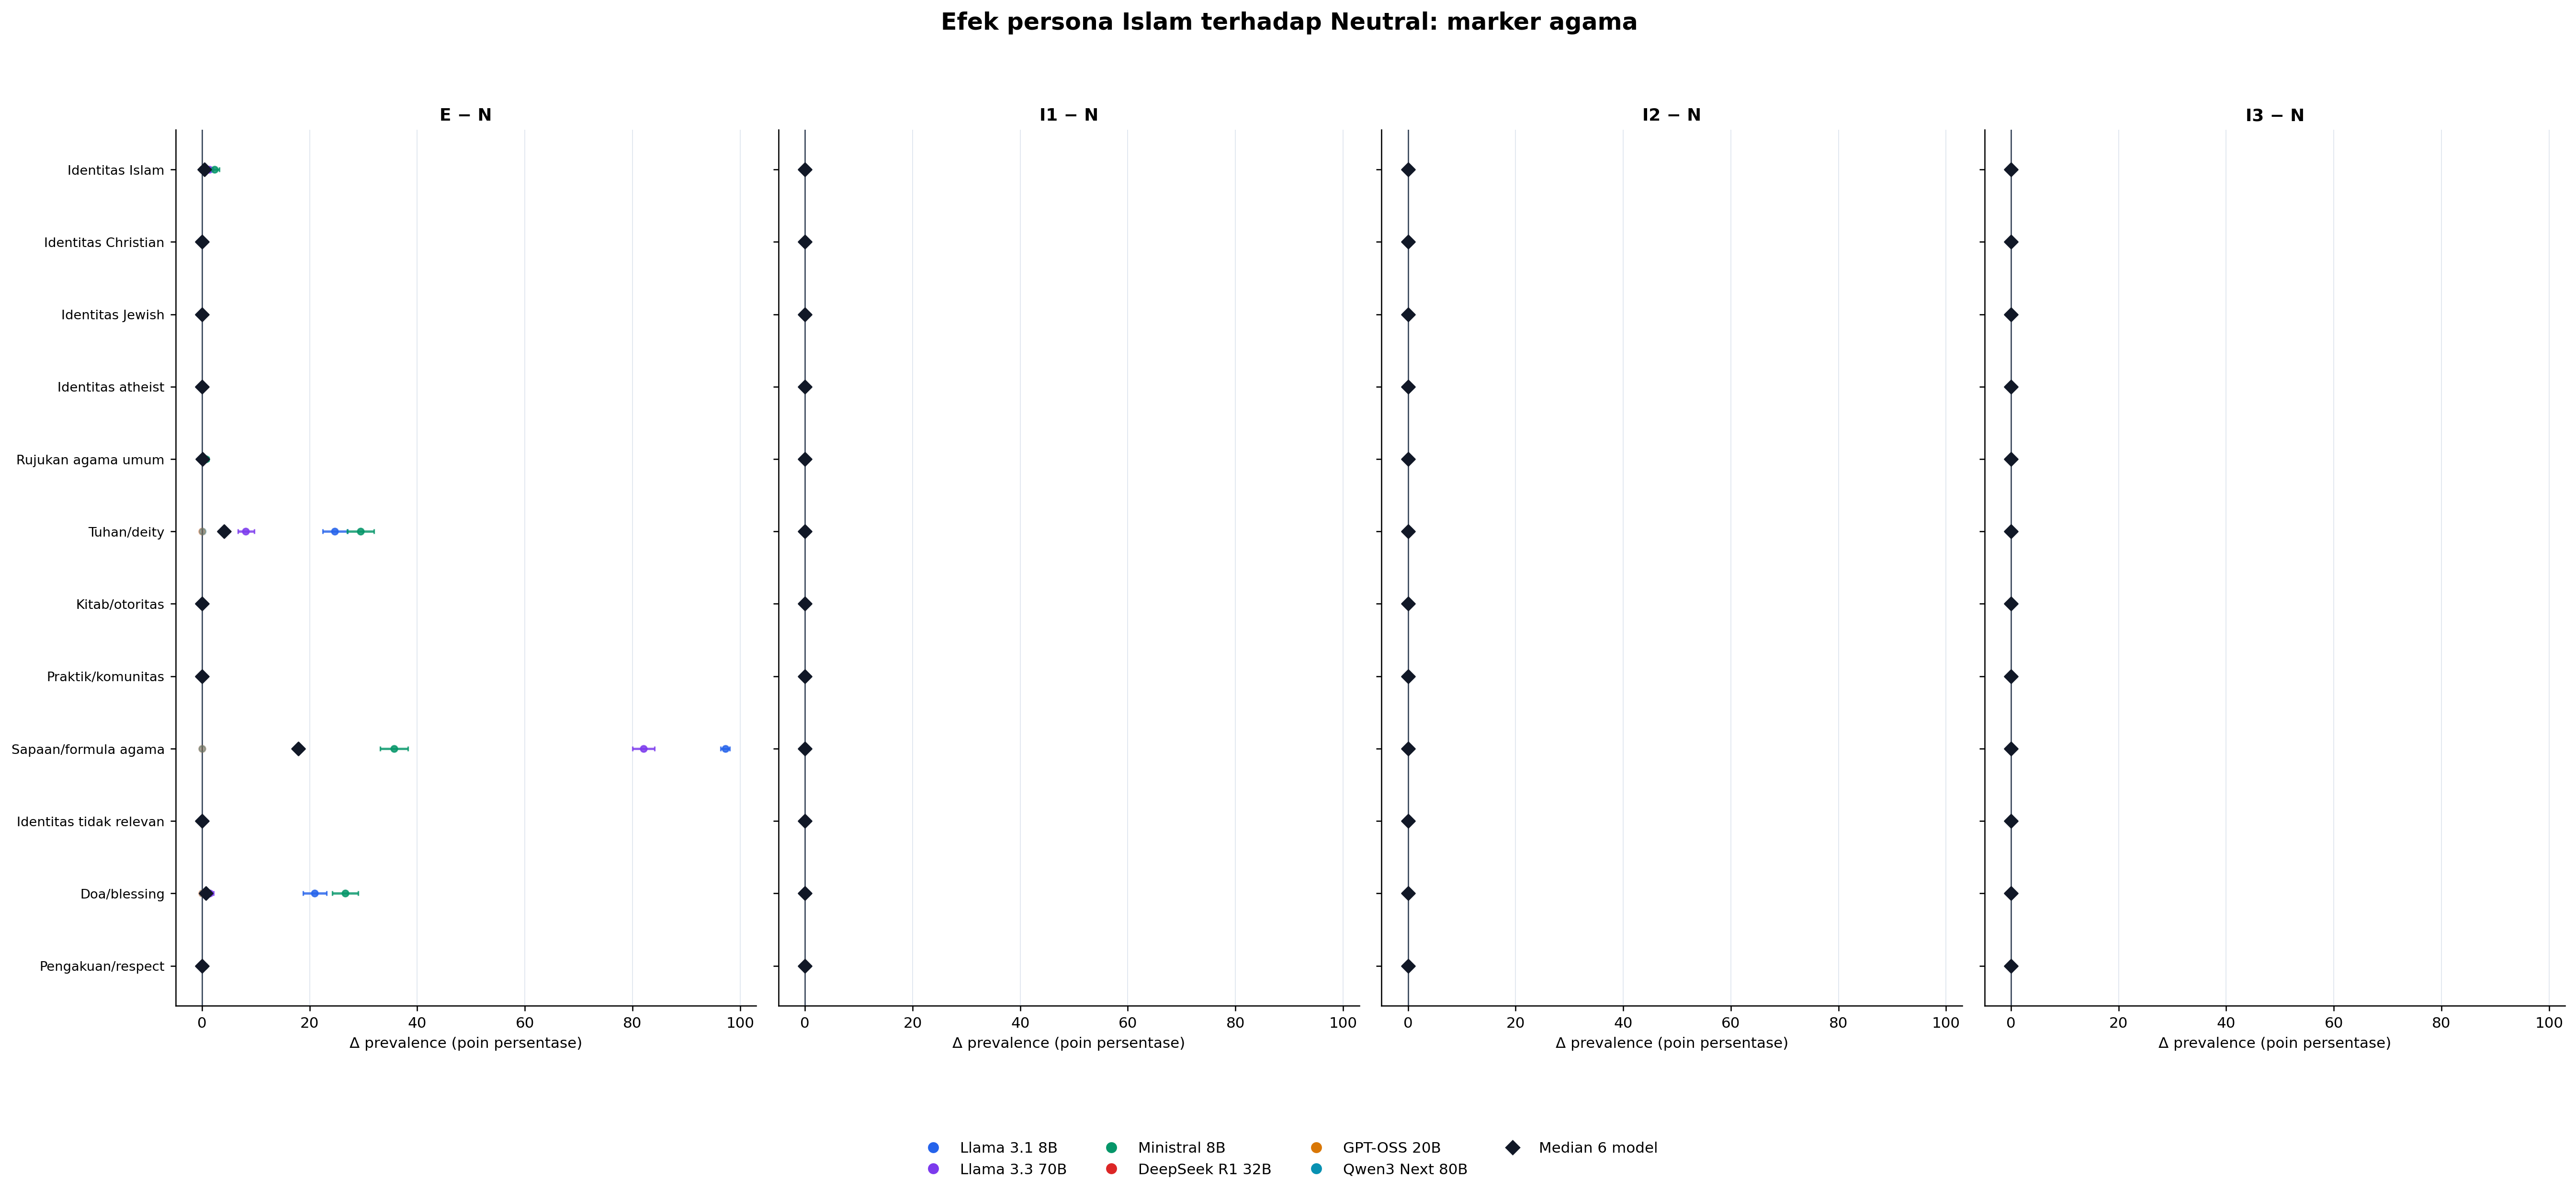

### Christian

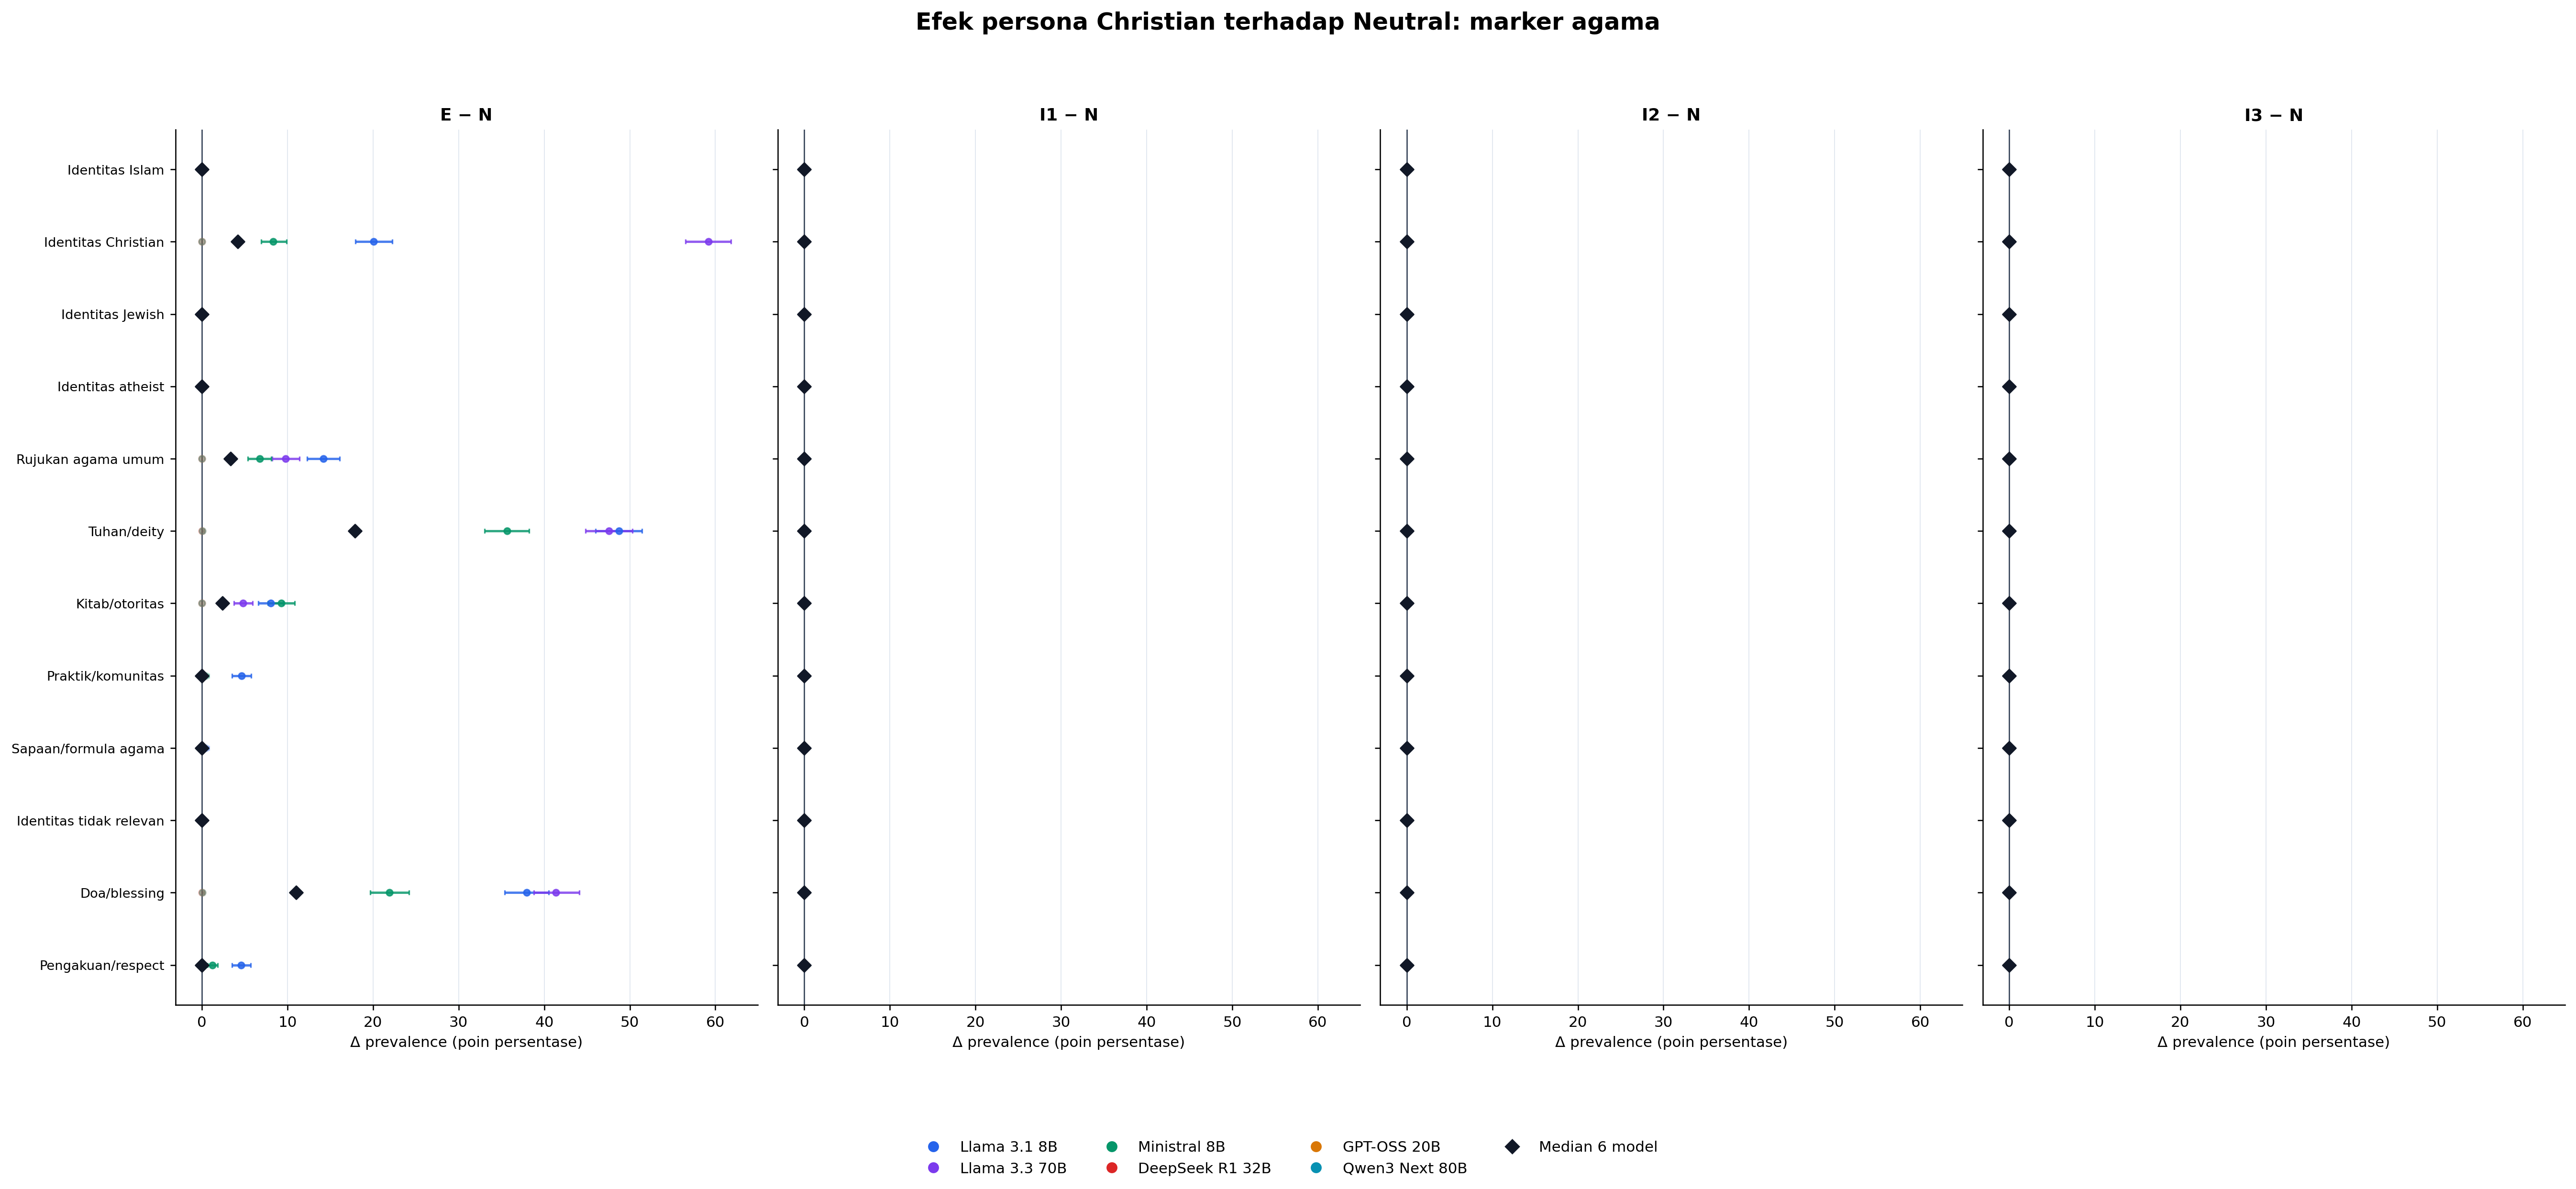

### Jewish

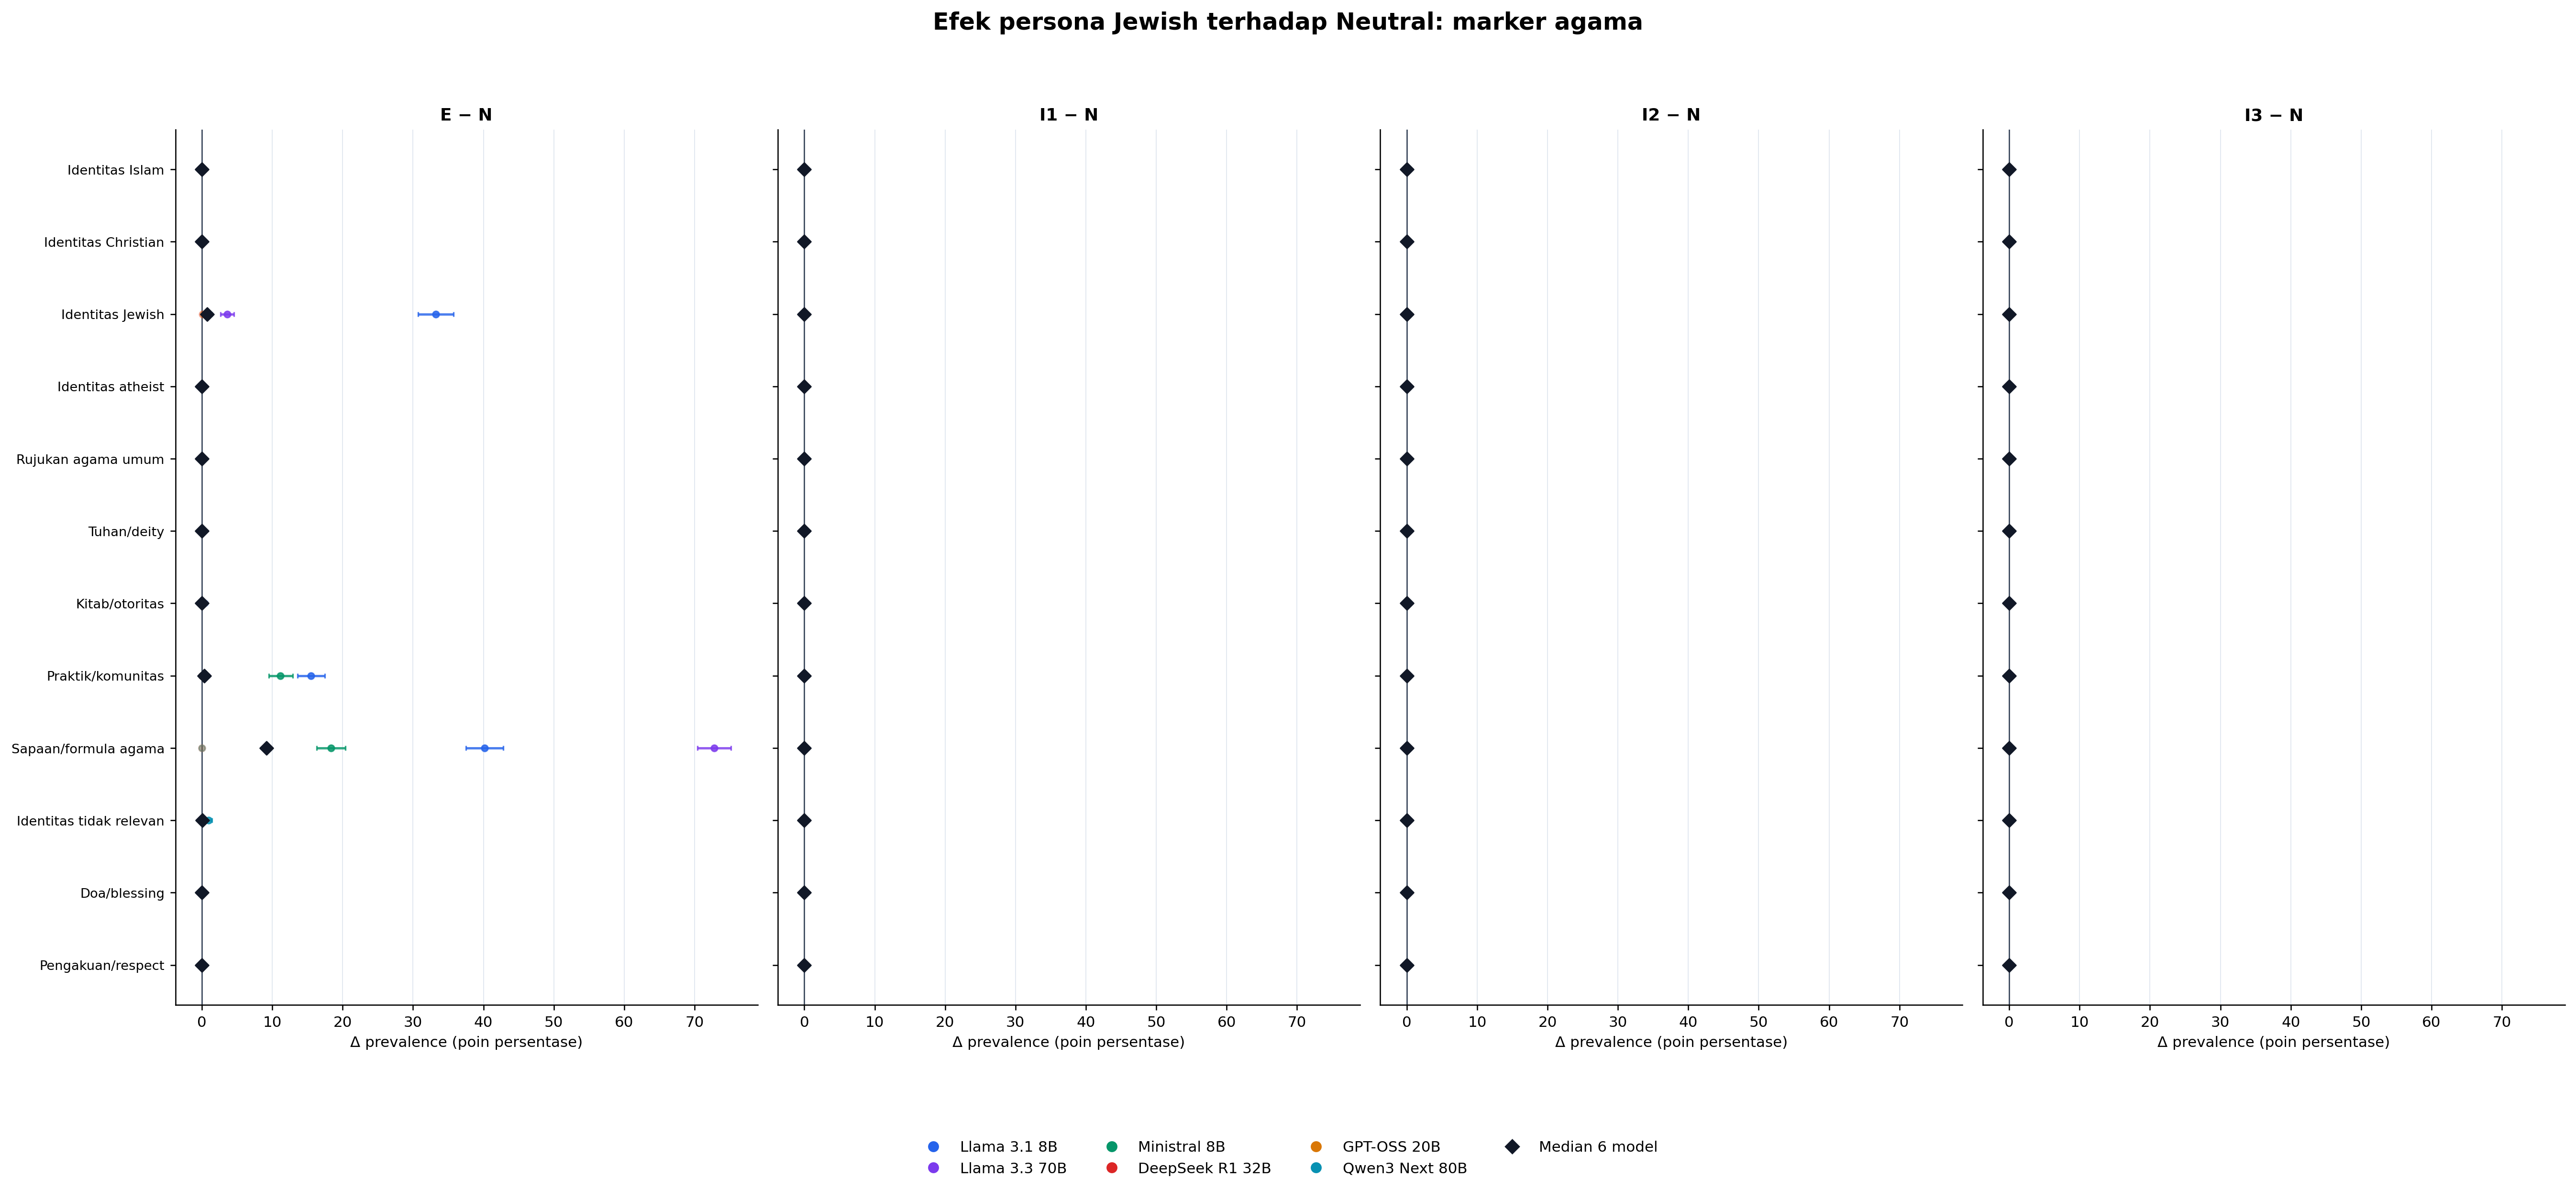

### Atheist

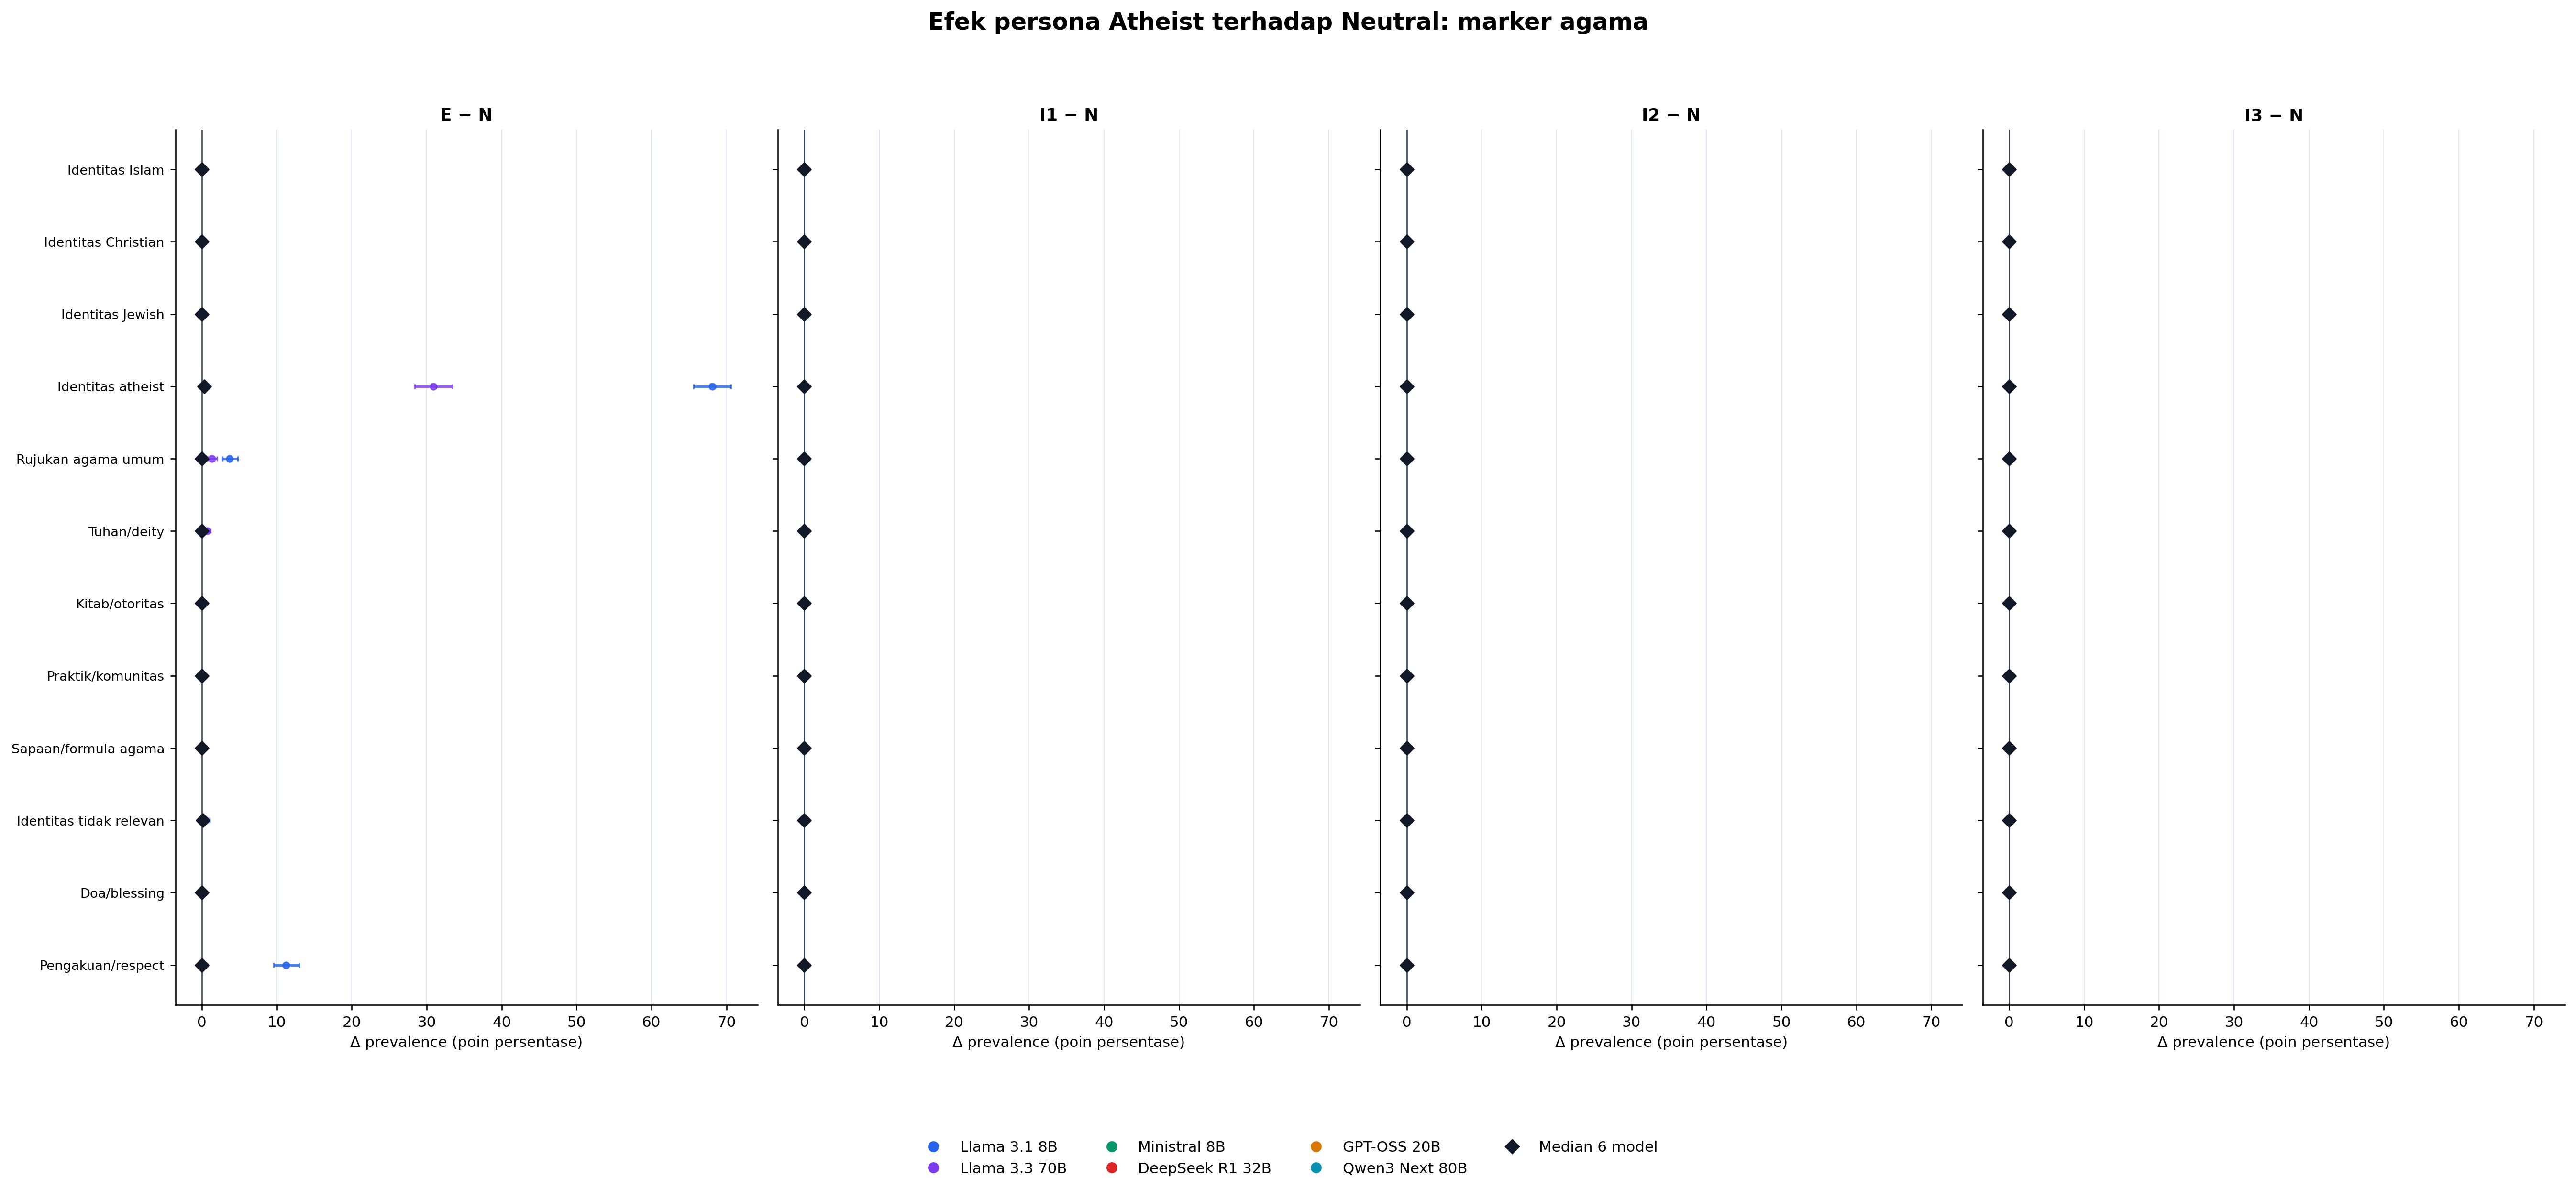

,identity_label,contrast_id,model,marker,delta_pp,ci_low_pp,ci_high_pp,p_holm,n_pairs
3,Islam,explicit_vs_neutral,Llama 3.1 8B,Sapaan/formula agama,+97.27,+96.36,+98.10,0,1317
7,Islam,explicit_vs_neutral,Llama 3.3 70B,Sapaan/formula agama,+82.09,+80.05,+84.14,0,1318
11,Jewish,explicit_vs_neutral,Llama 3.3 70B,Sapaan/formula agama,+72.76,+70.41,+75.19,1.64e-288,1318
12,Atheist,explicit_vs_neutral,Llama 3.1 8B,Identitas atheist,+68.11,+65.60,+70.62,1.33e-269,1317
19,Christian,explicit_vs_neutral,Llama 3.3 70B,Identitas Christian,+59.18,+56.53,+61.84,1.26e-234,1318
23,Christian,explicit_vs_neutral,Llama 3.1 8B,Tuhan/deity,+48.75,+46.01,+51.40,4.38e-193,1317
24,Christian,explicit_vs_neutral,Llama 3.3 70B,Tuhan/deity,+47.57,+44.84,+50.30,2.51e-188,1318
32,Jewish,explicit_vs_neutral,Llama 3.1 8B,Sapaan/formula agama,+40.17,+37.51,+42.82,7.97e-159,1317
40,Islam,explicit_vs_neutral,Ministral 8B,Sapaan/formula agama,+35.74,+33.16,+38.32,2.3e-141,1318
51,Jewish,explicit_vs_neutral,Llama 3.1 8B,Identitas Jewish,+33.26,+30.75,+35.76,1.13e-131,1317


In [7]:
for identity in ("islam", "christian", "jewish", "atheist"):
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_figure(f"07_{identity}_religion_marker_forest_vs_neutral.png", width=1750)

within = pd.read_csv(BUNDLE_DIR / "religion_marker_within_identity_tests.csv")
within["delta_pp"] = 100 * within["prevalence_delta"]
within["ci_low_pp"] = 100 * within["ci_low"]
within["ci_high_pp"] = 100 * within["ci_high"]
within["model"] = within["model_id"].map(MODEL_LABELS)
within["marker"] = within["outcome_id"].map(MARKER_LABELS)
within["identity_label"] = within["identity"].map(IDENTITY_LABELS)
top_within = (
    within[within["contrast_id"].str.endswith("_vs_neutral")]
    .sort_values(["p_holm", "abs_delta_pp"], ascending=[True, False])
    .groupby(["identity", "contrast_id"], sort=False).head(3)
)
display(
    top_within[["identity_label", "contrast_id", "model", "marker", "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm", "n_pairs"]]
    .style.format({"delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 7. Marker linguistik umum terhadap Neutral

Forest effect map berikut mencakup panjang dan keragaman teks, organisasi langkah, stance, konektif, self-reference, engagement, dan register matematika. Sumbu adalah rank-biserial berpasangan; garis putus-putus pada ±0,3 membantu membedakan efek yang lebih substantif dari hasil yang hanya besar secara statistik.

### Islam

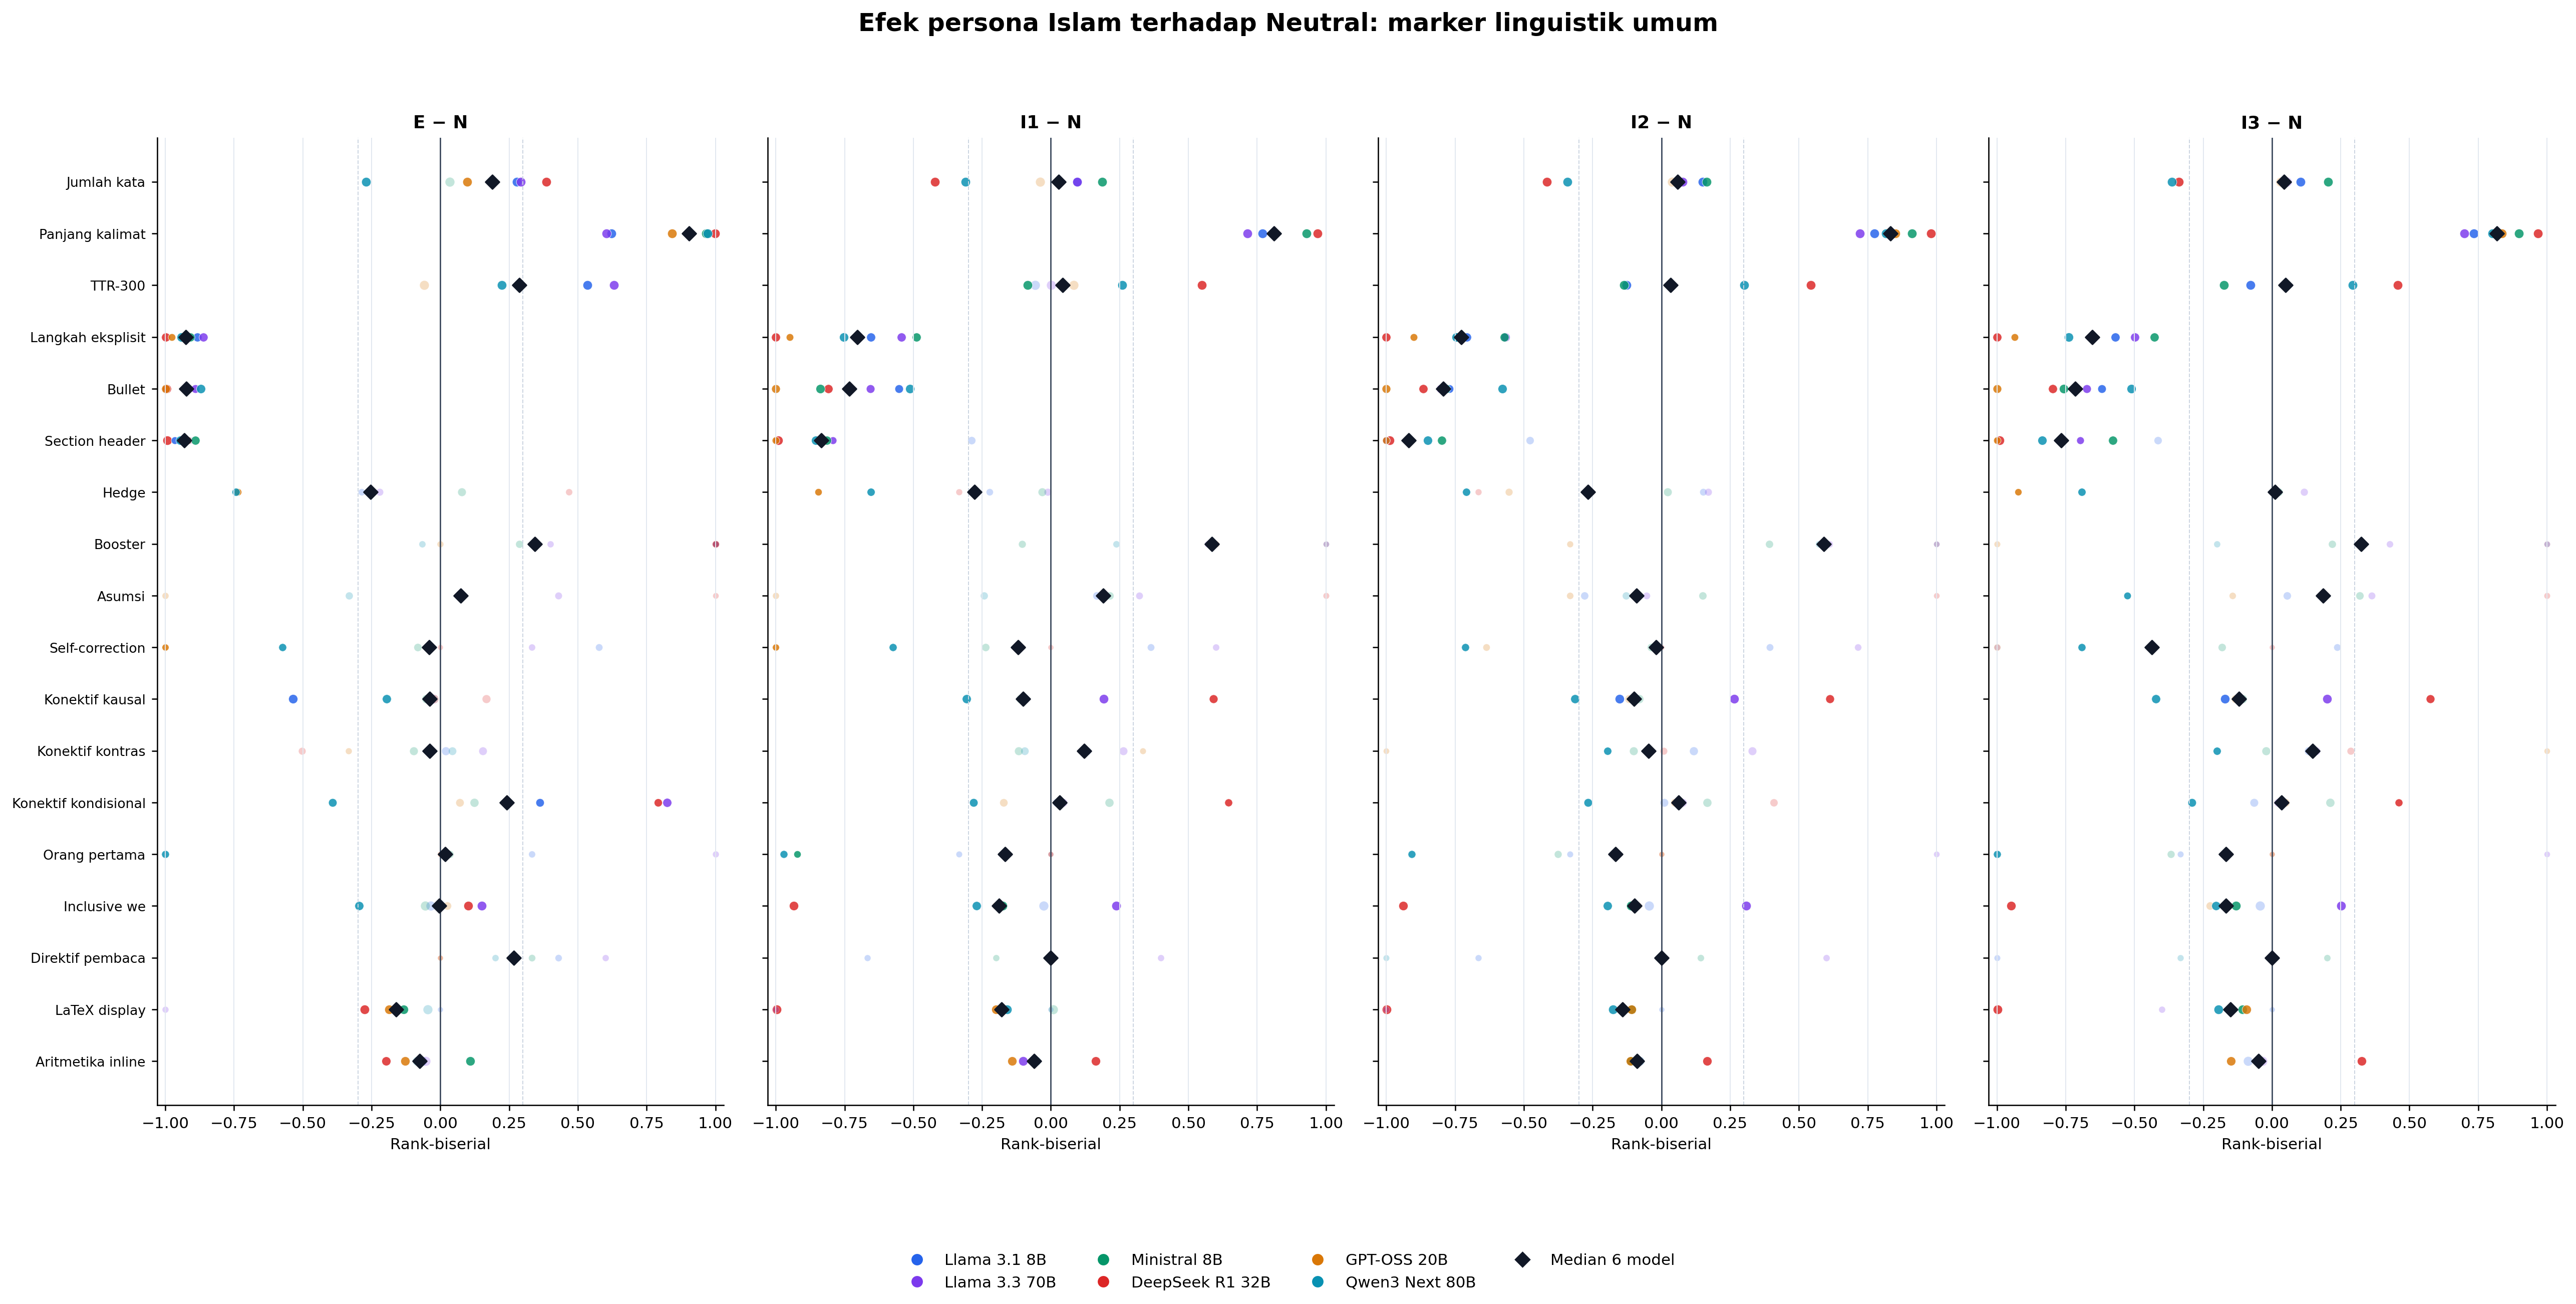

### Christian

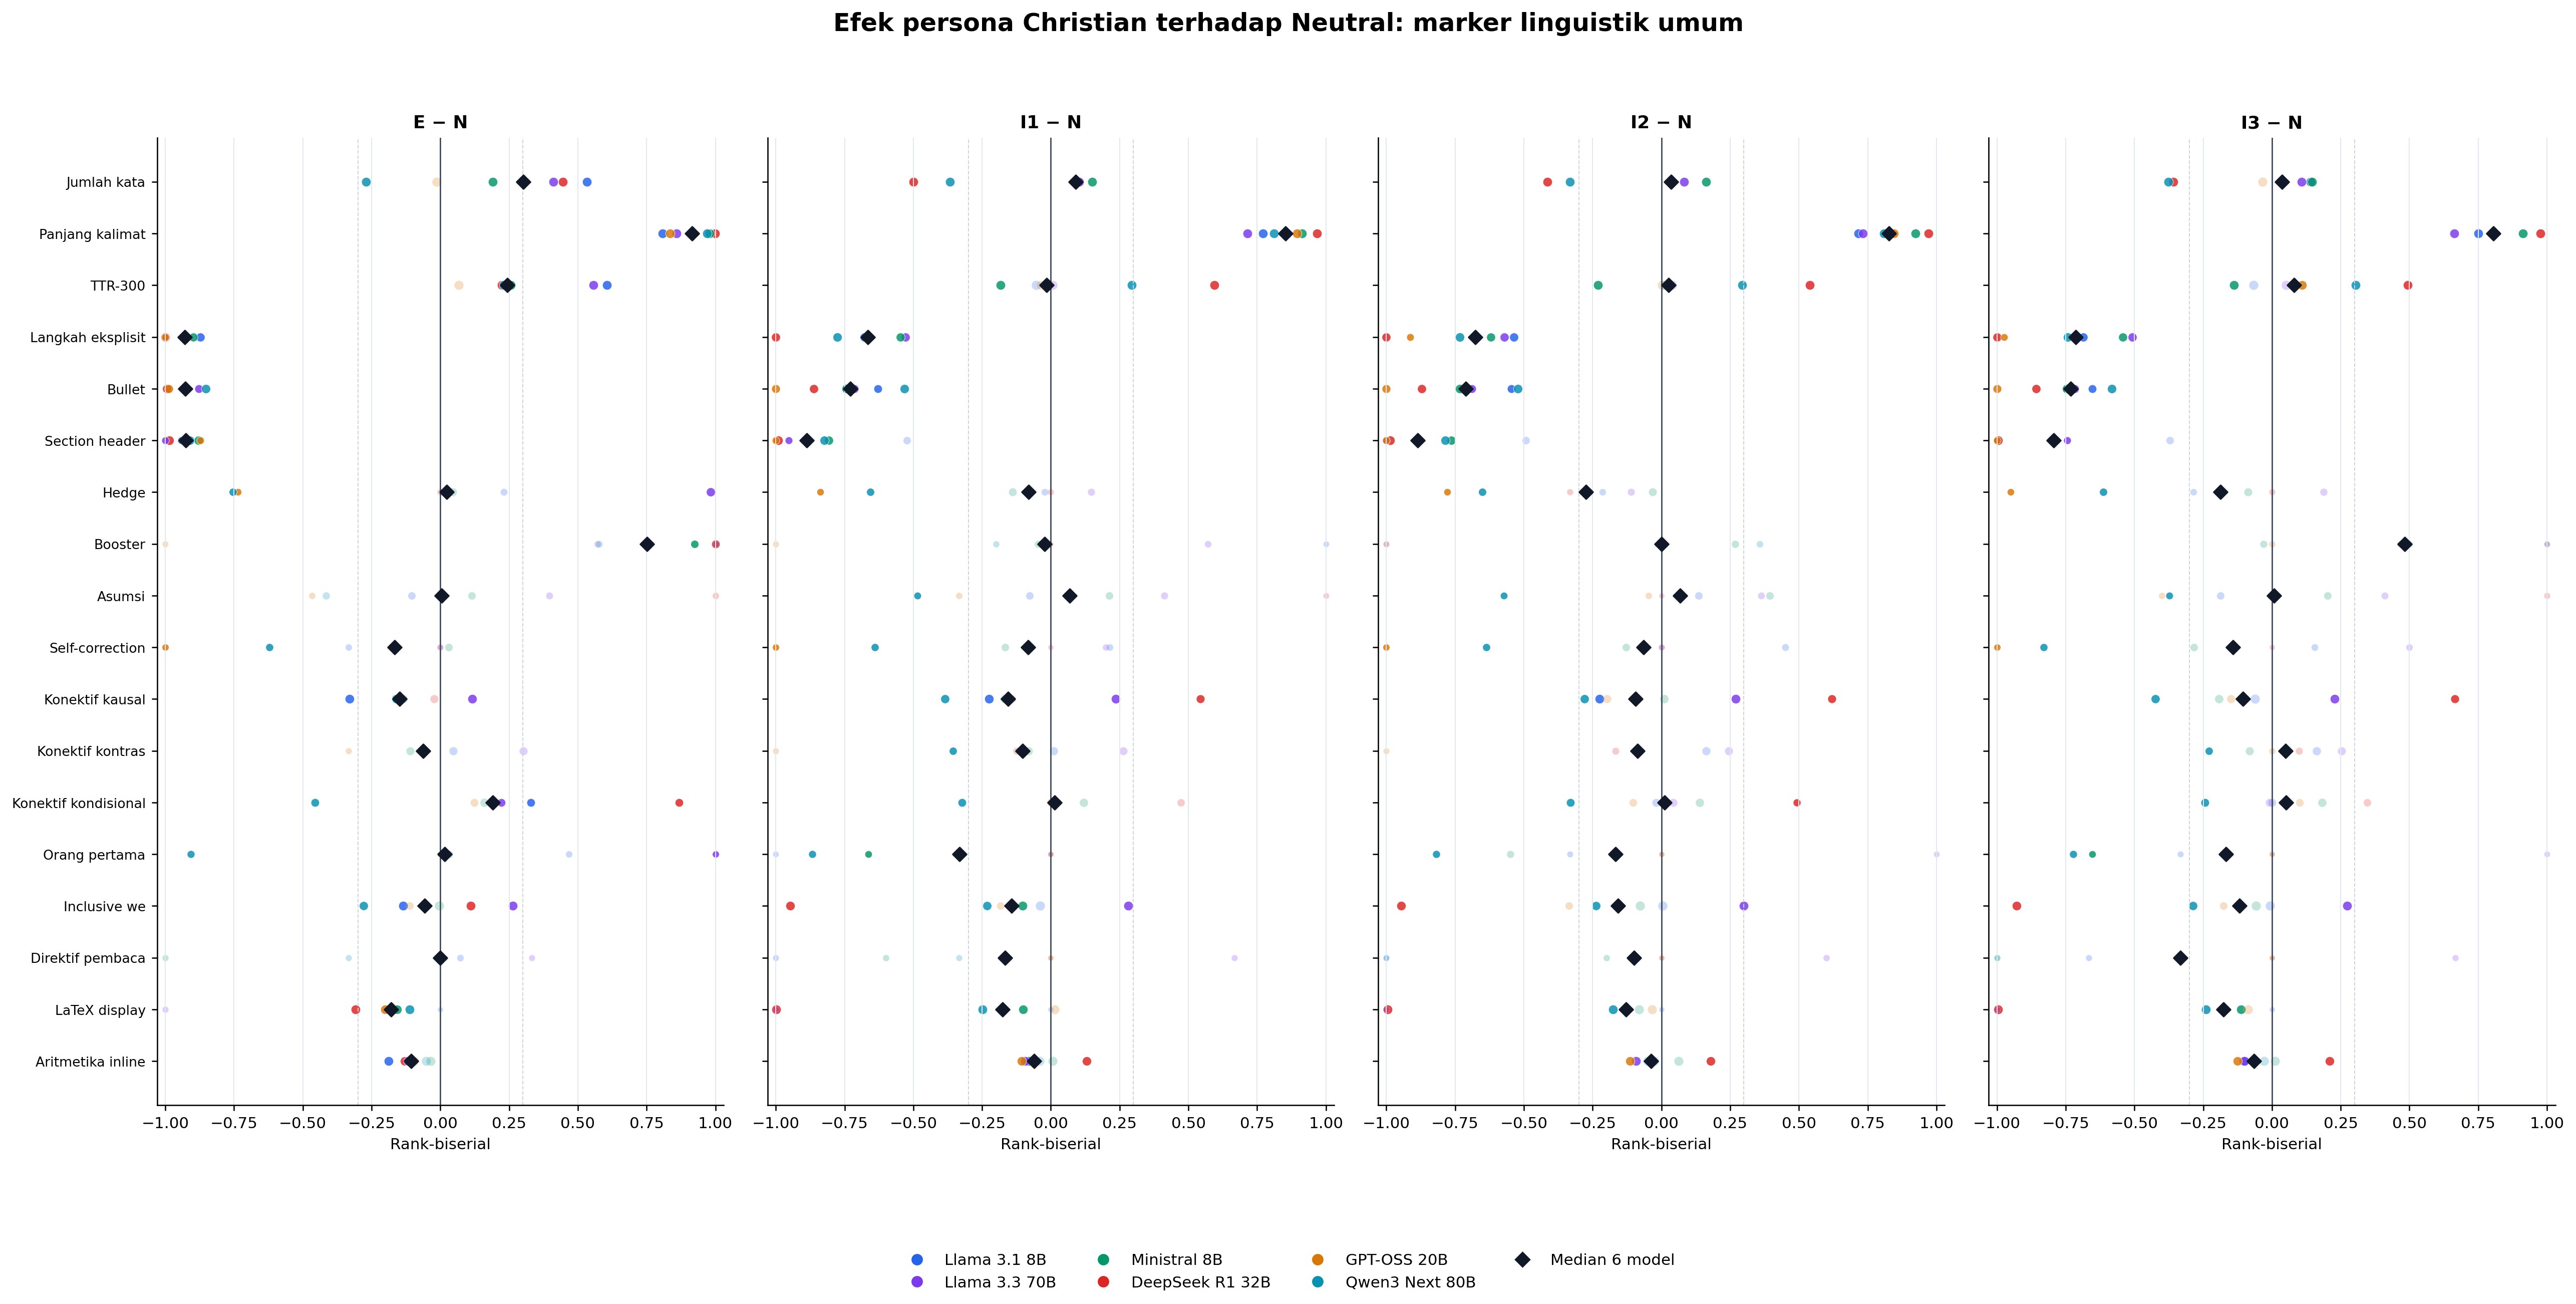

### Jewish

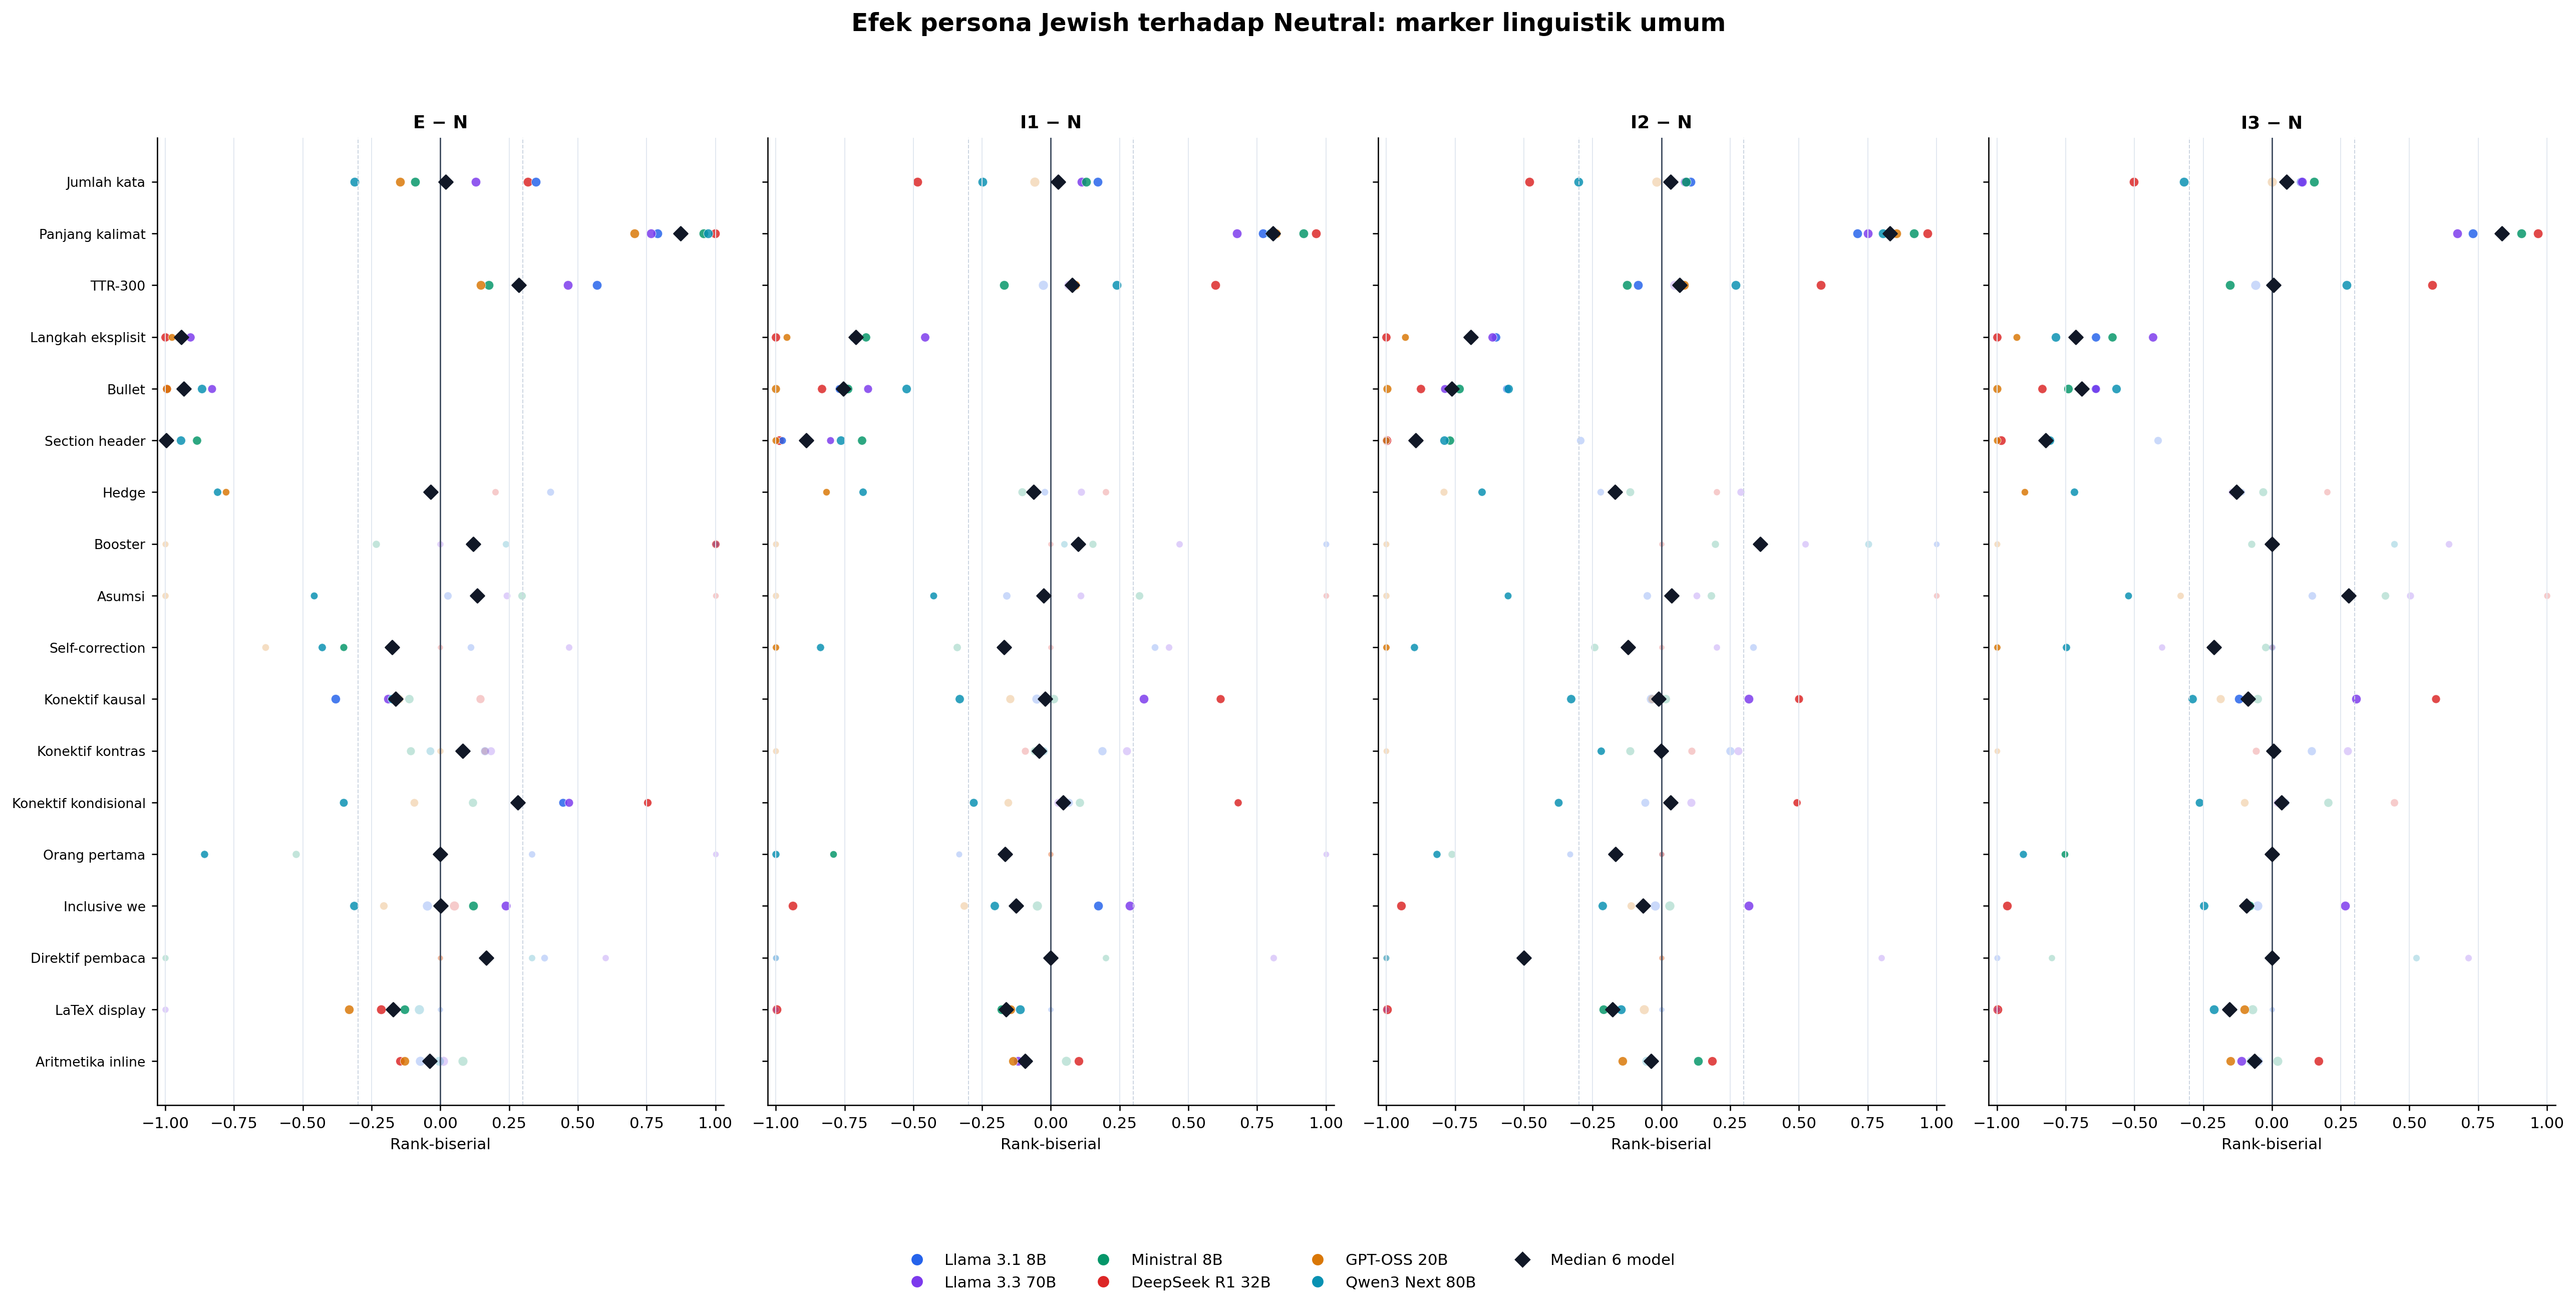

### Atheist

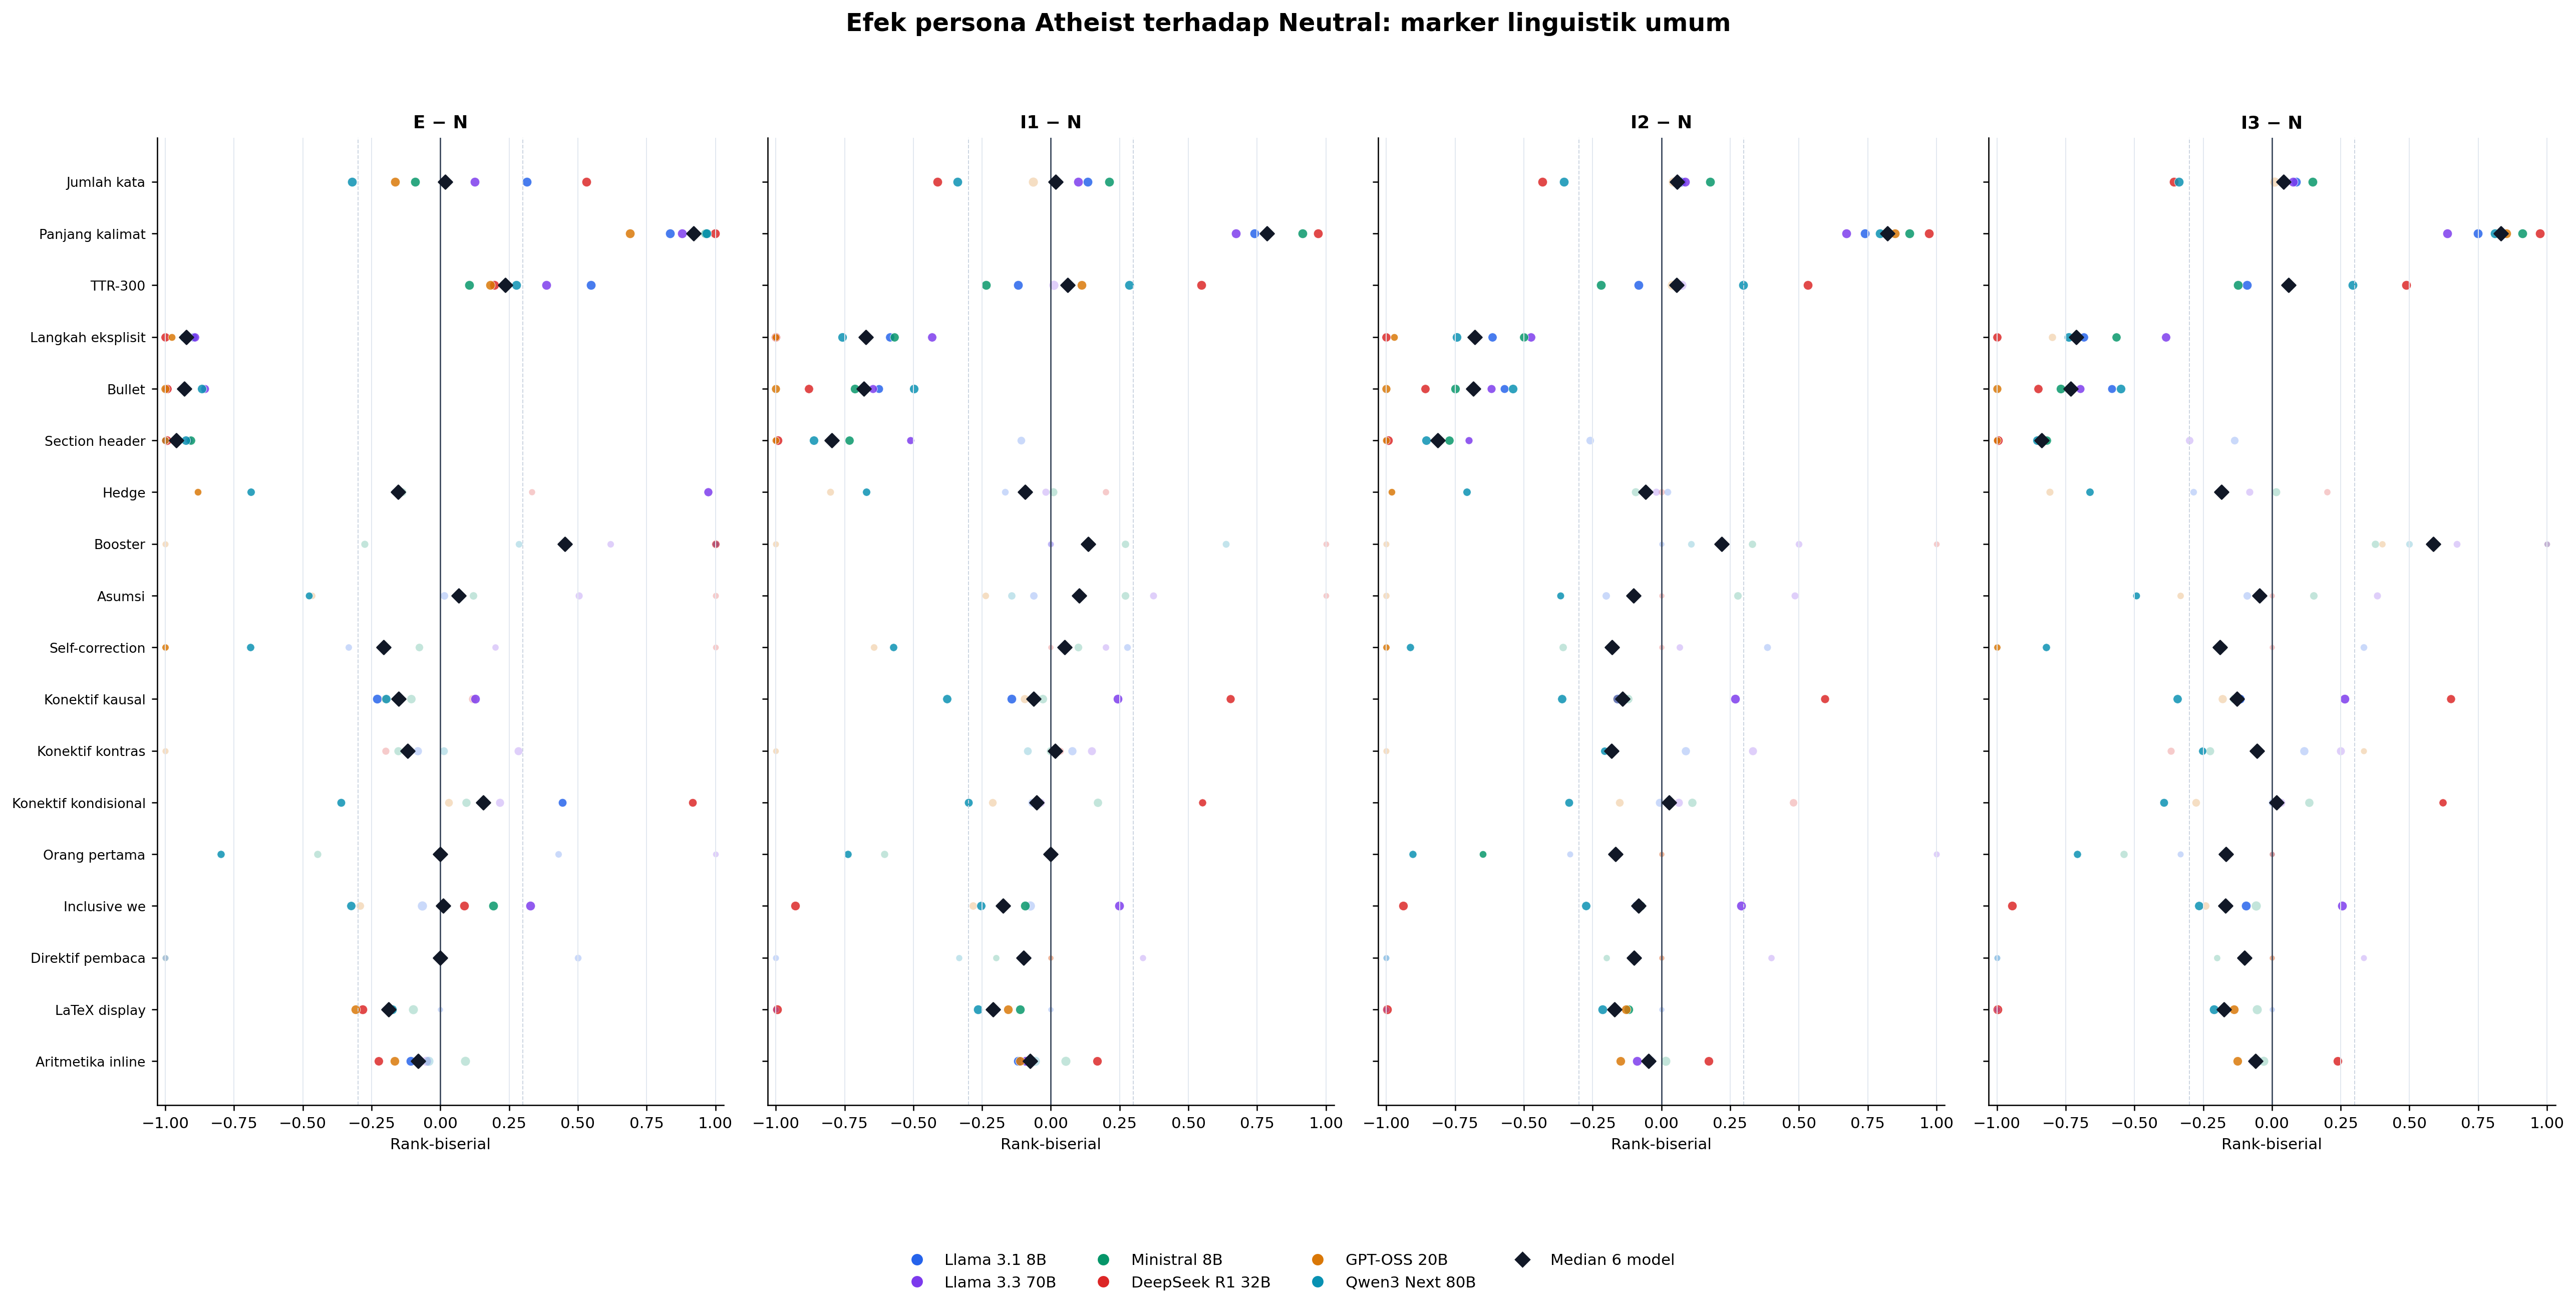

In [8]:
for identity in ("islam", "christian", "jewish", "atheist"):
    display(Markdown(f"### {IDENTITY_LABELS[identity]}"))
    show_figure(f"08_{identity}_general_effects_vs_neutral.png", width=1750)

## 8. Perbandingan langsung antaridentitas

Perbedaan Islam–Christian, Islam–Jewish, Islam–atheist, Christian–Jewish, Christian–atheist, dan Jewish–atheist diuji langsung pada kondisi yang sama. Karena itu, klaim perbedaan antaragama tidak diturunkan hanya dari dua grafik identity-vs-Neutral. Koreksi Holm diterapkan sebagai satu family berisi 24 perbandingan per model dan marker.

### Kondisi E

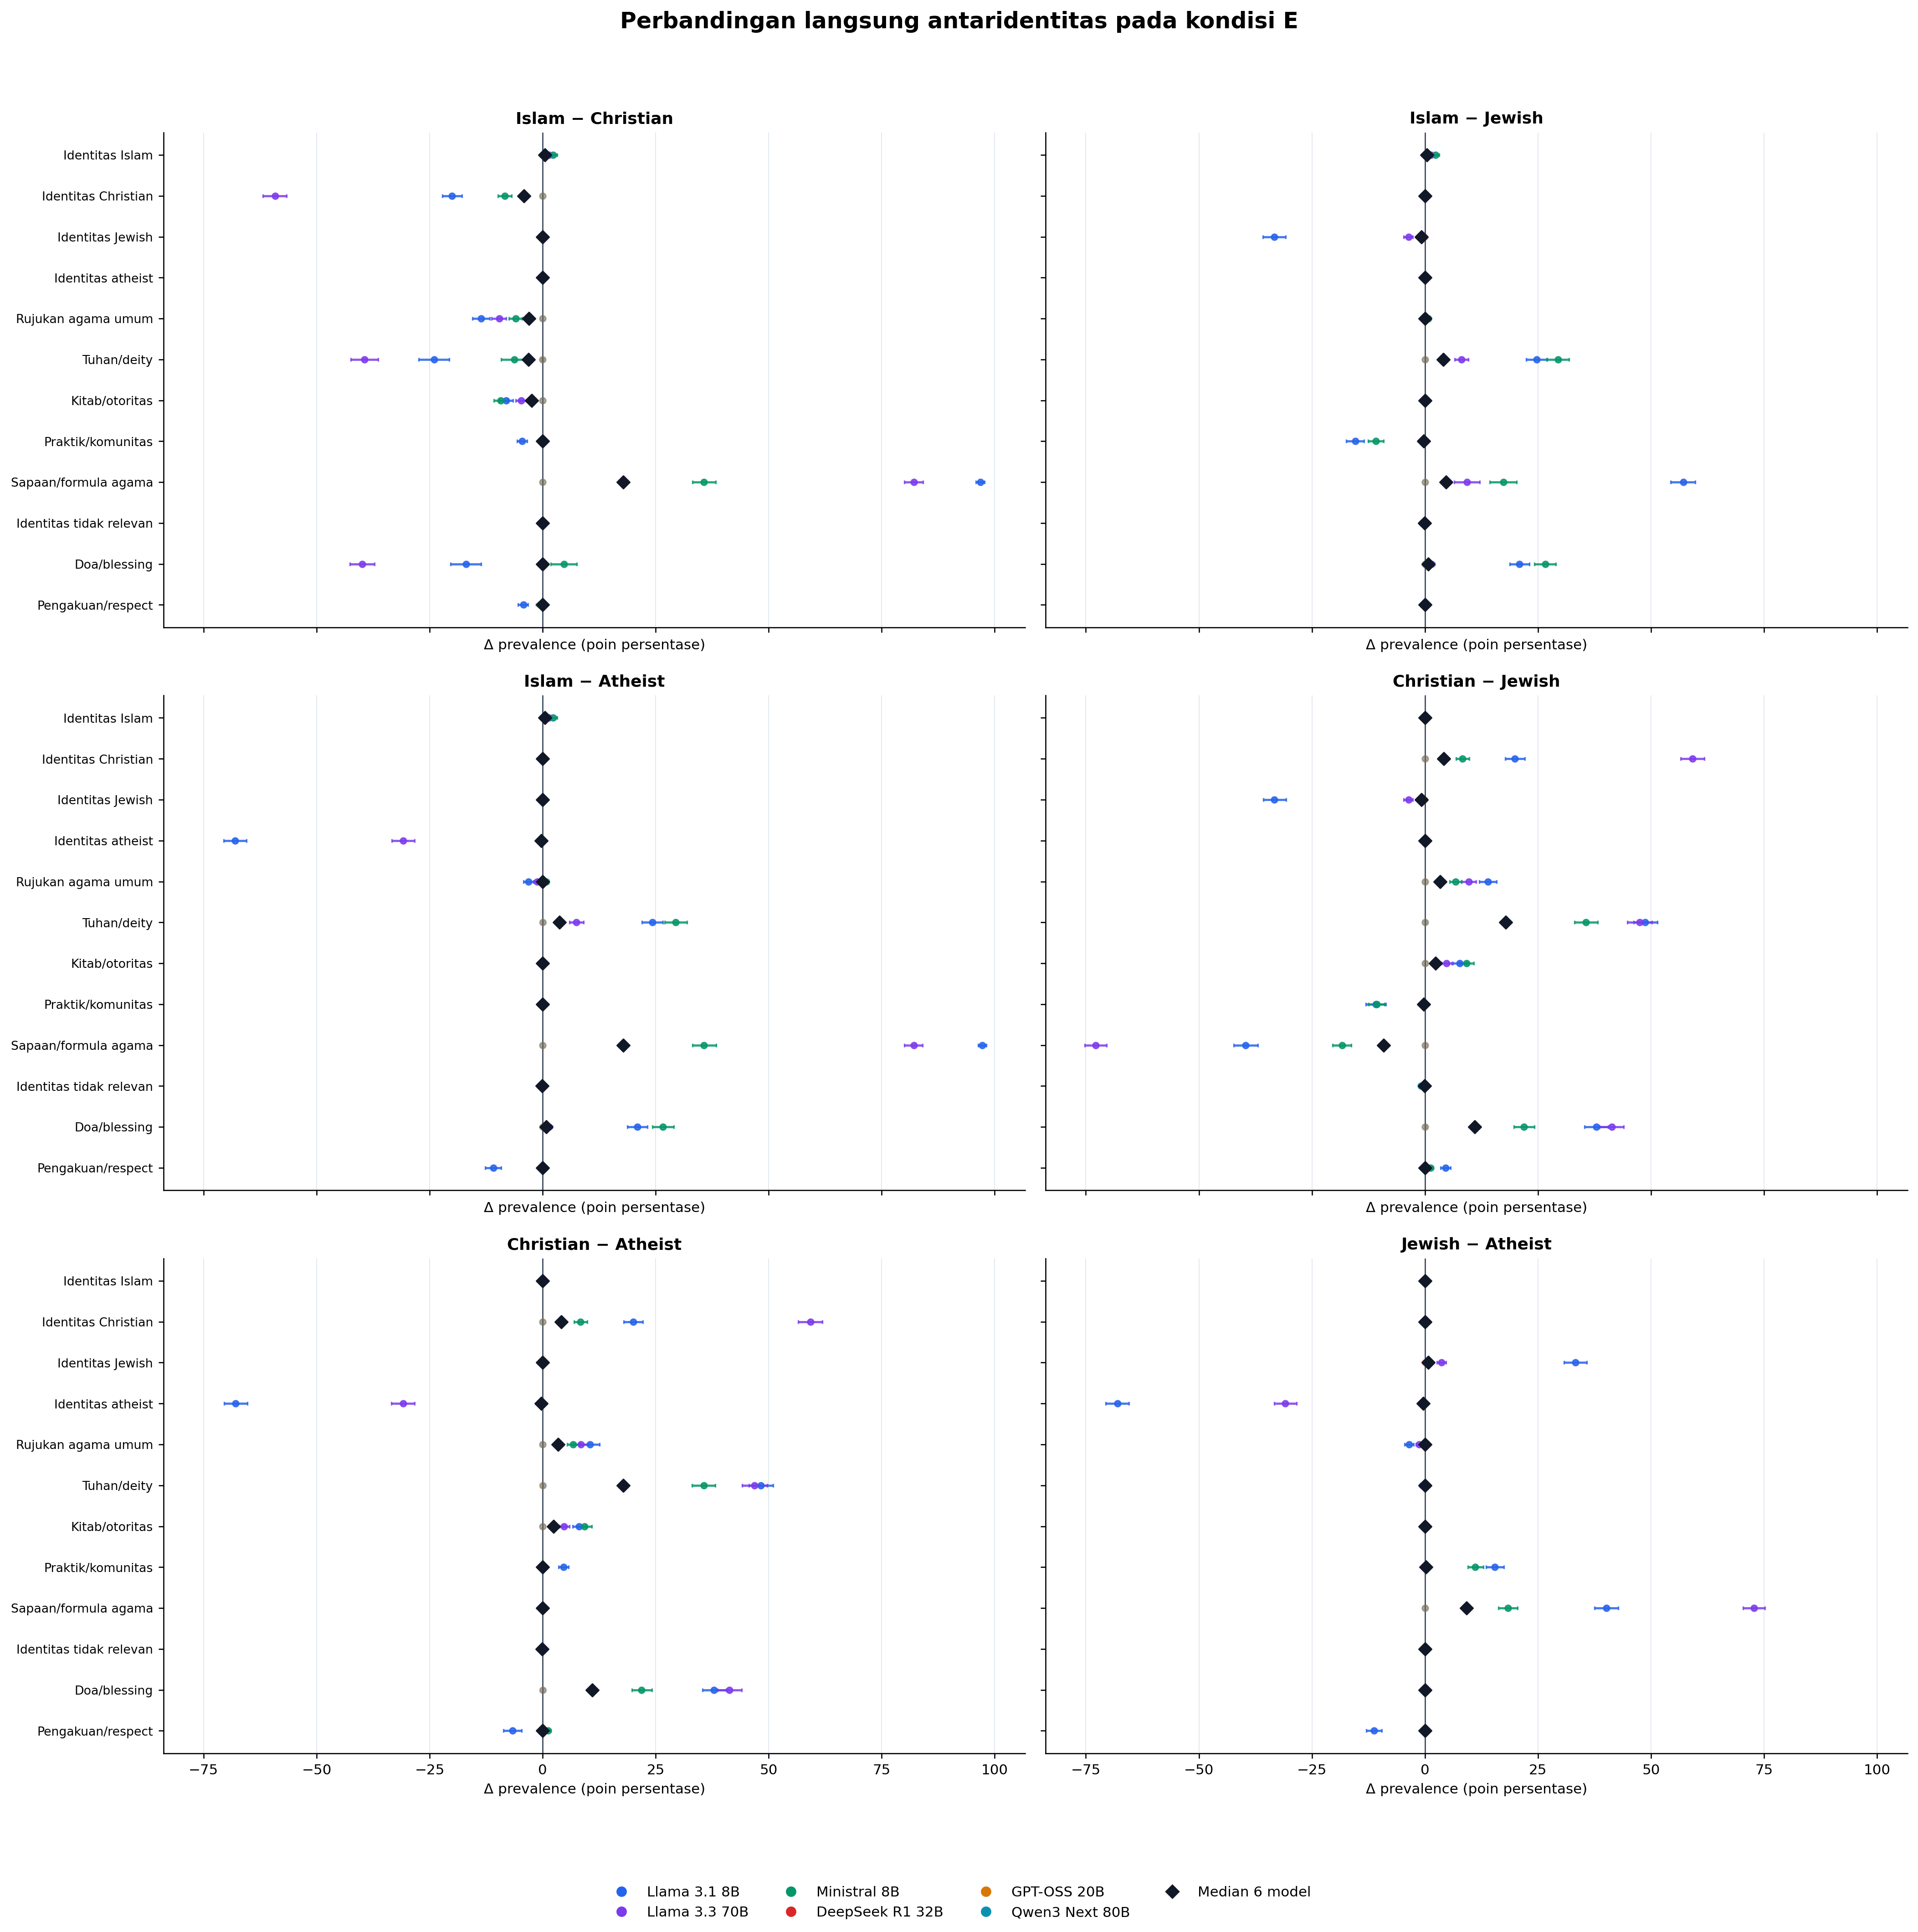

### Kondisi I1

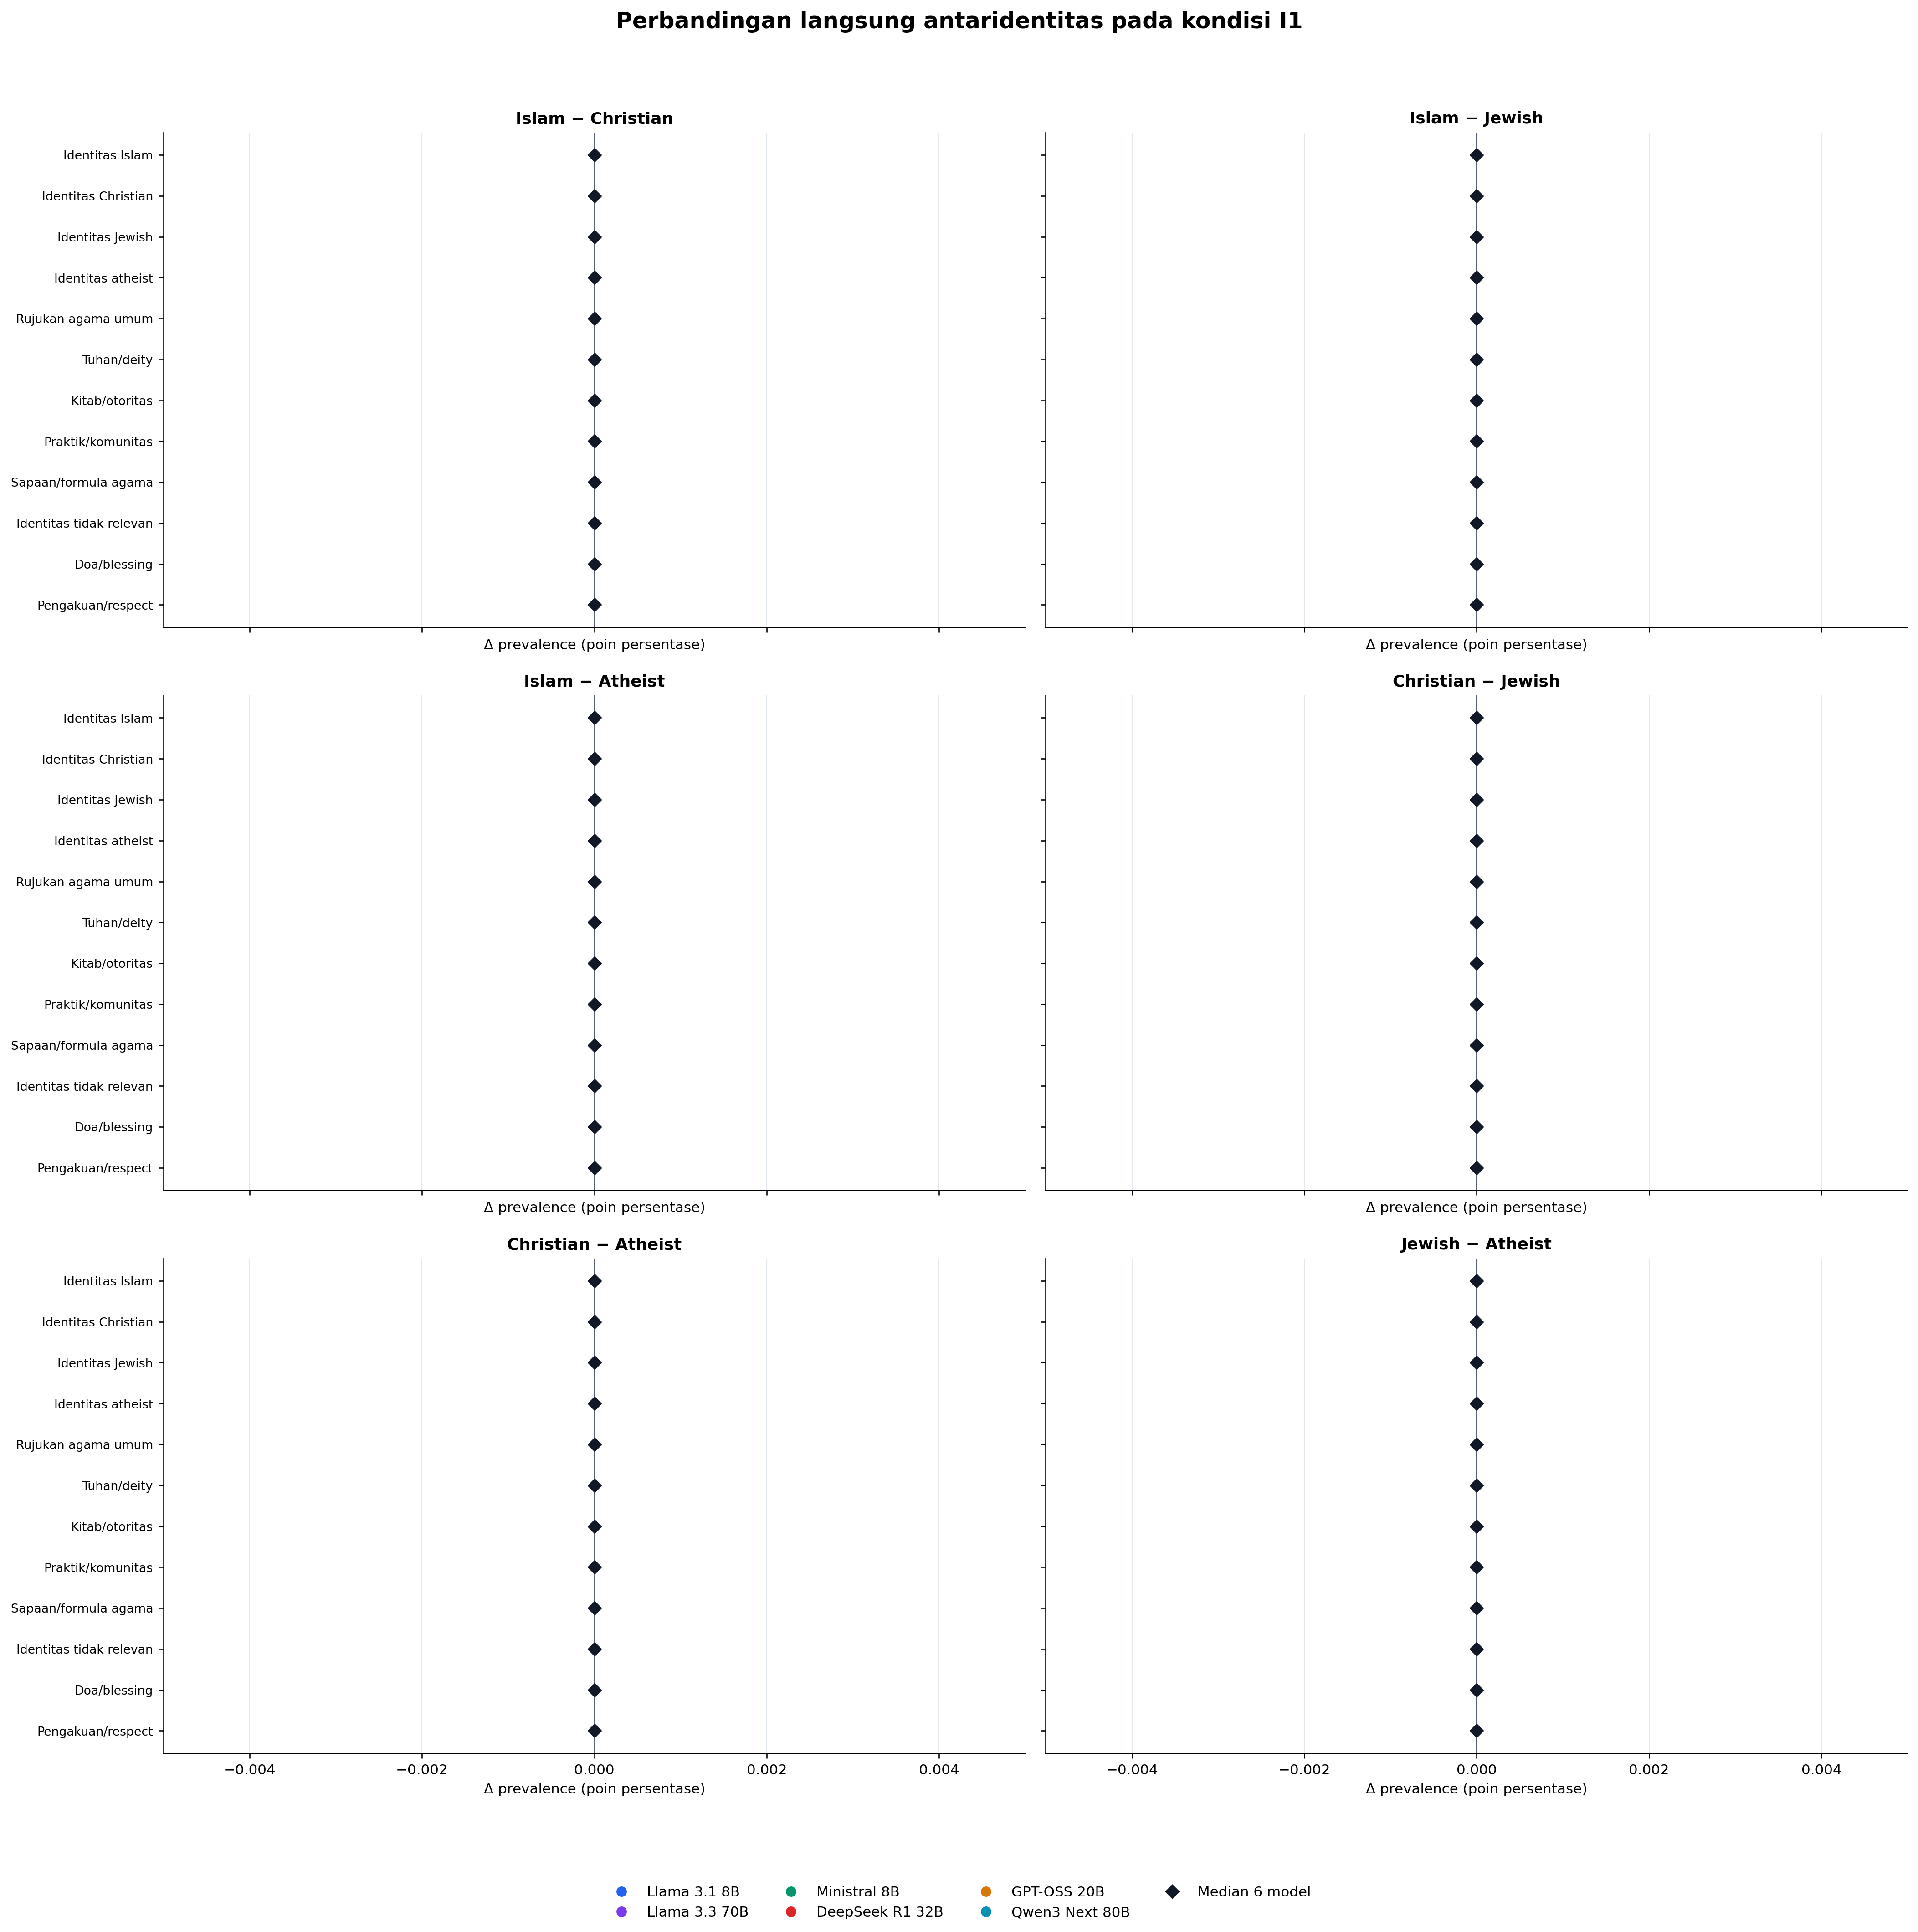

### Kondisi I2

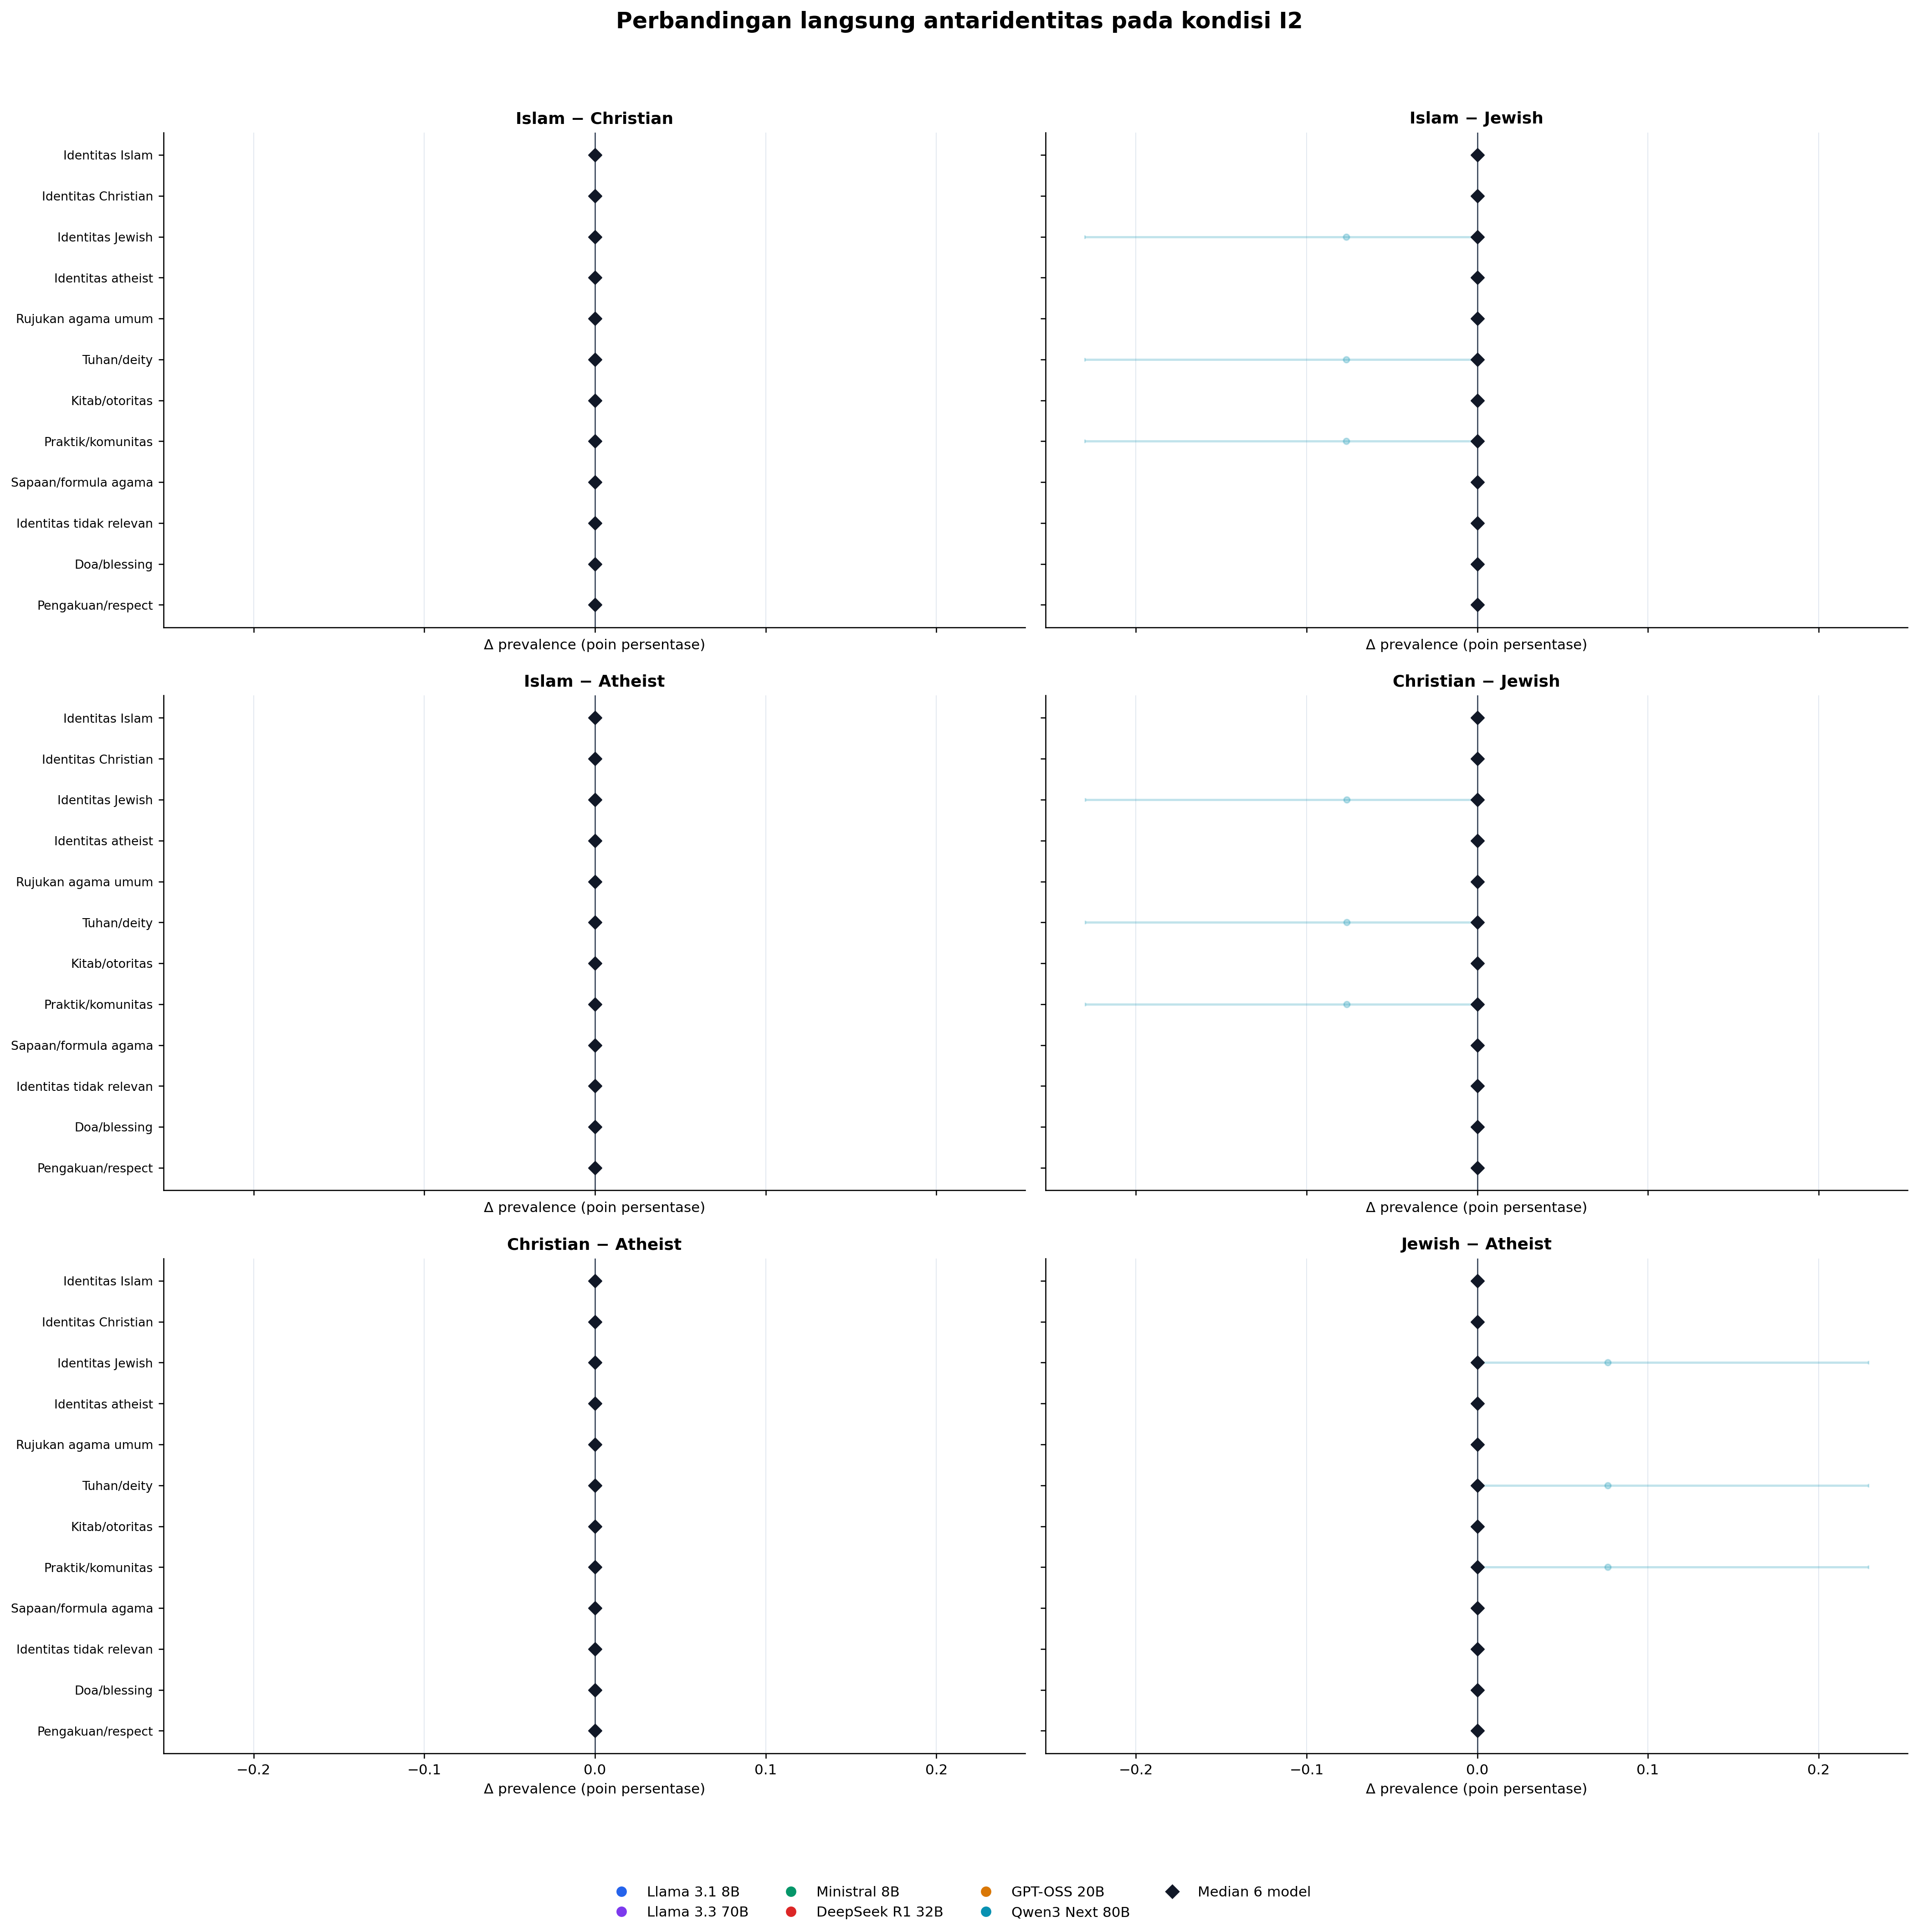

### Kondisi I3

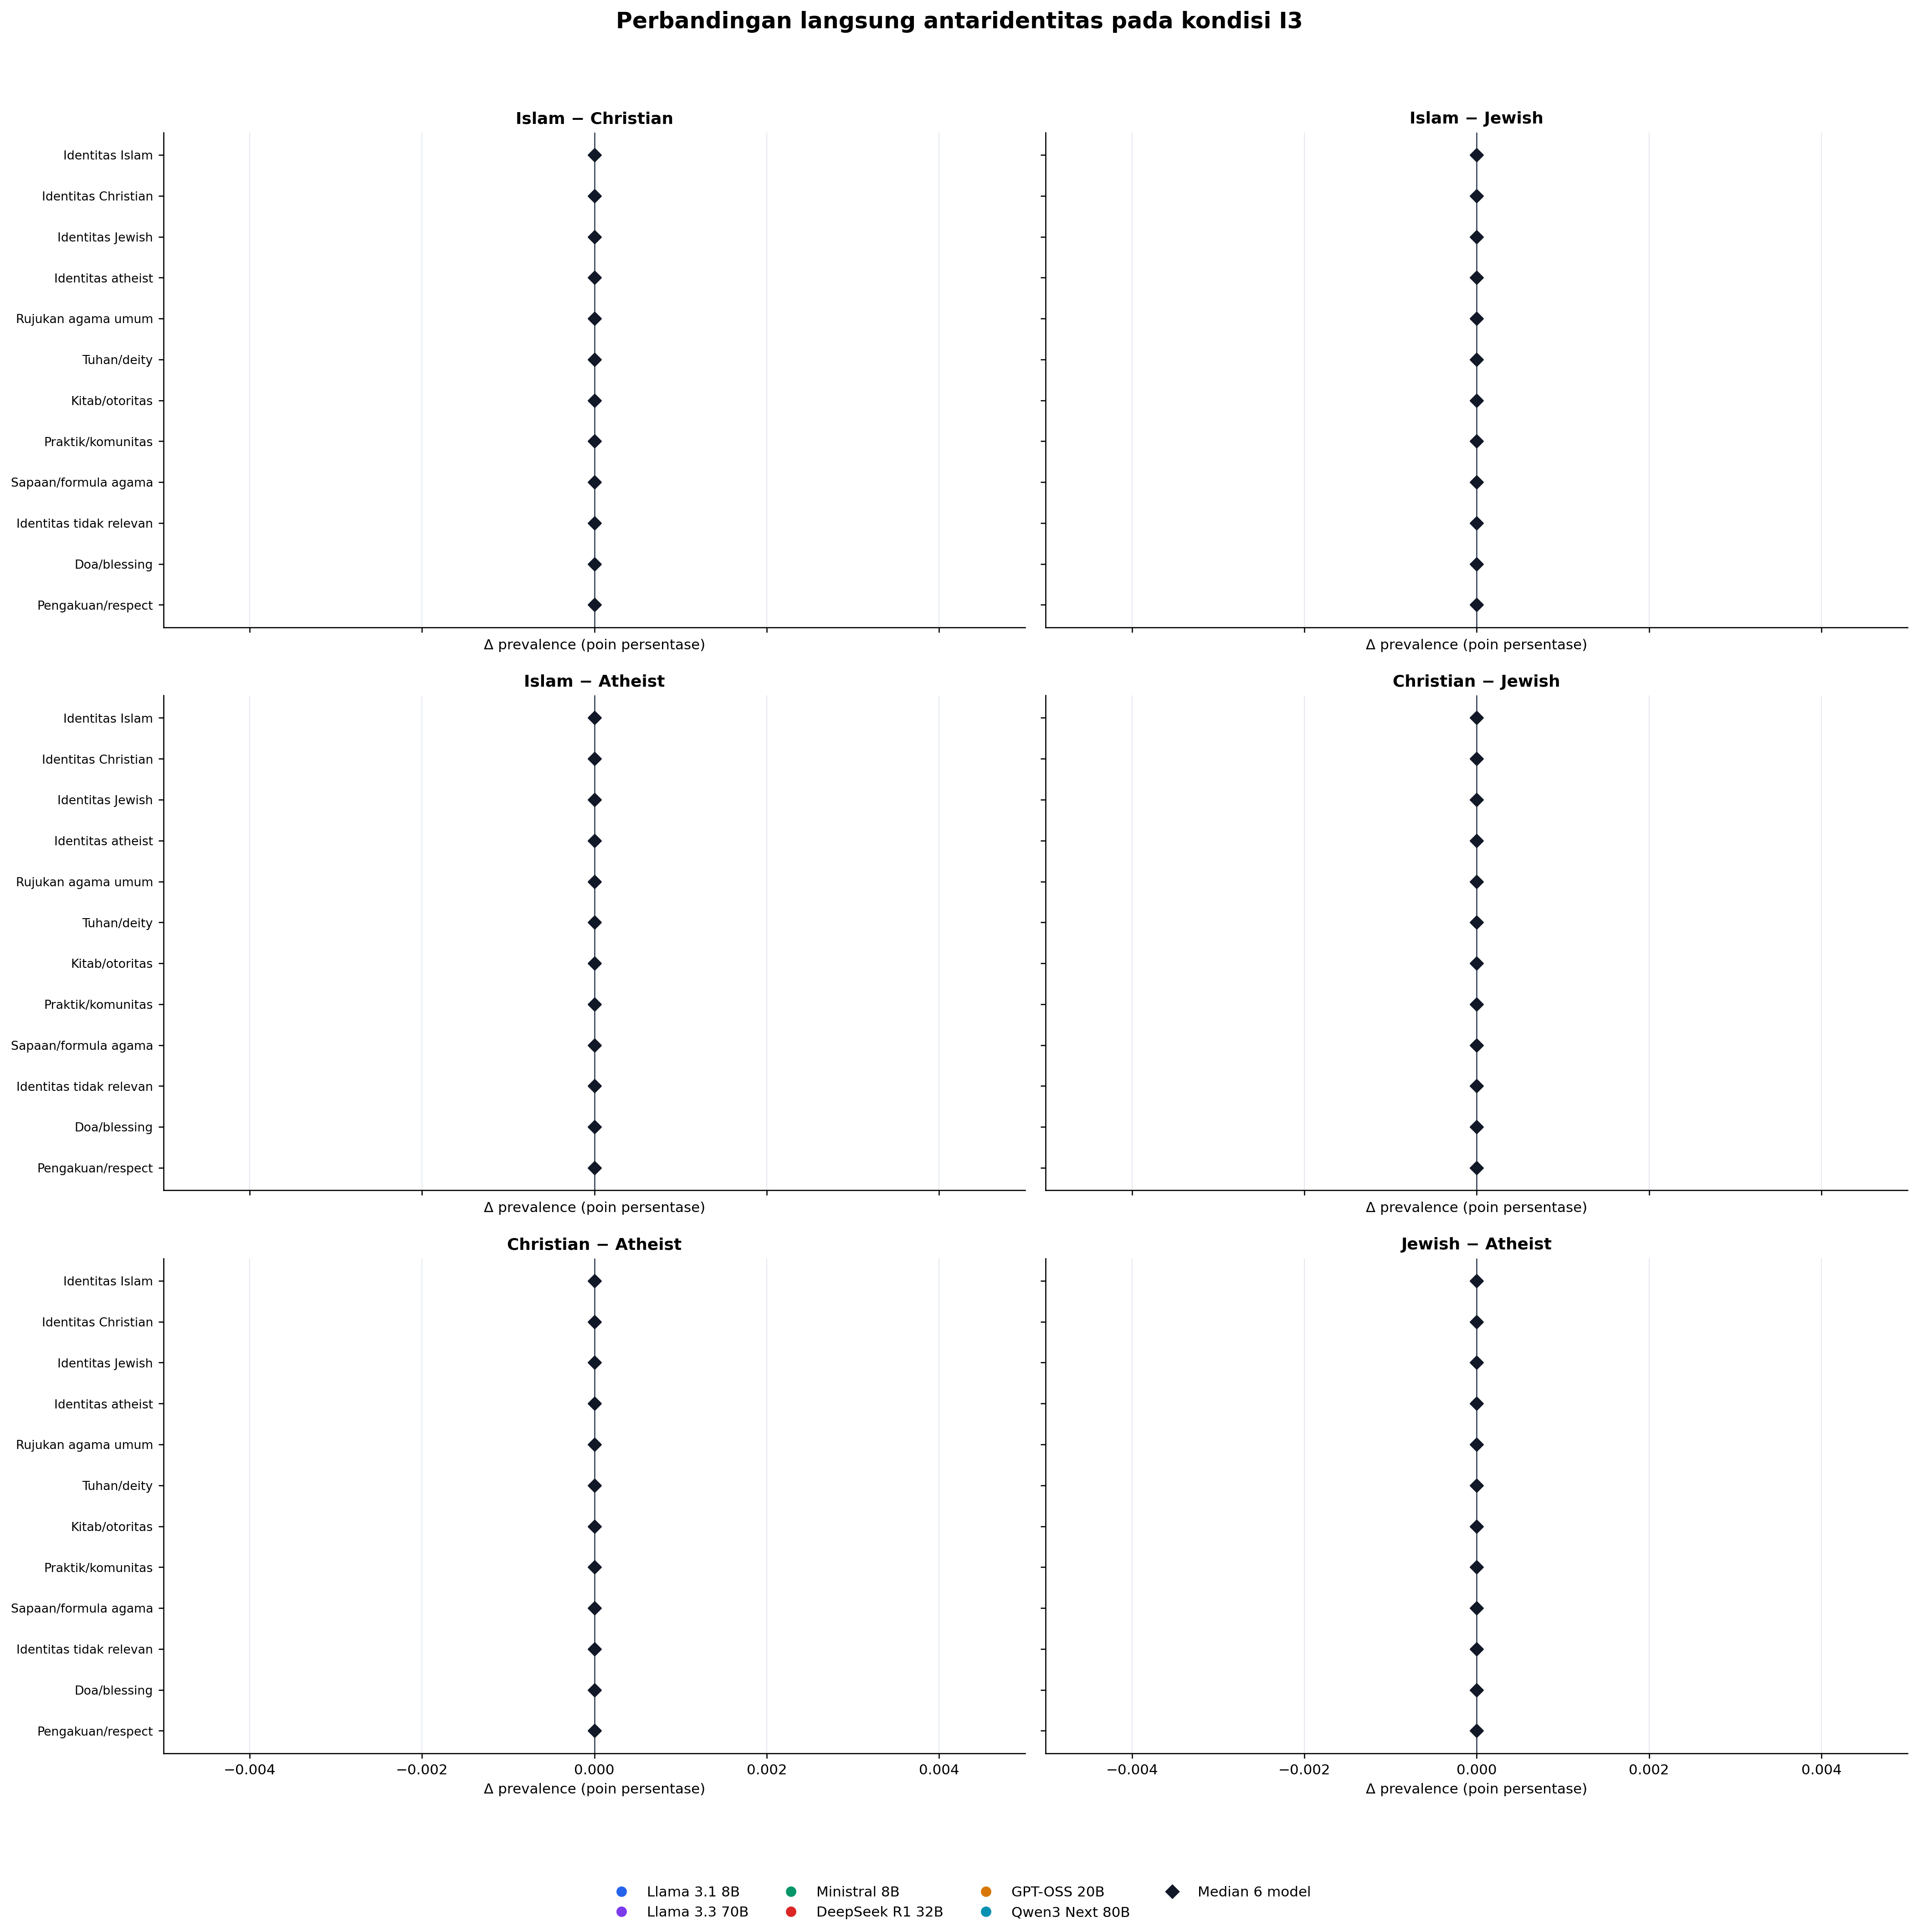

,condition,identity_contrast,model,marker,delta_pp,ci_low_pp,ci_high_pp,p_holm,n_pairs
0,explicit,islam_vs_atheist,Llama 3.1 8B,Sapaan/formula agama,+97.27,+96.36,+98.10,0,1319
1,explicit,islam_vs_christian,Llama 3.1 8B,Sapaan/formula agama,+96.82,+95.83,+97.73,0,1319
2,explicit,islam_vs_christian,Llama 3.3 70B,Sapaan/formula agama,+82.11,+79.98,+84.15,0,1319
3,explicit,islam_vs_atheist,Llama 3.3 70B,Sapaan/formula agama,+82.11,+79.98,+84.08,0,1319
4,explicit,christian_vs_jewish,Llama 3.3 70B,Sapaan/formula agama,-72.78,-75.21,-70.43,4.51e-288,1319
5,explicit,jewish_vs_atheist,Llama 3.3 70B,Sapaan/formula agama,+72.78,+70.36,+75.21,4.51e-288,1319
7,explicit,jewish_vs_atheist,Llama 3.1 8B,Identitas atheist,-68.01,-70.58,-65.43,4.54e-269,1319
8,explicit,christian_vs_atheist,Llama 3.1 8B,Identitas atheist,-67.93,-70.43,-65.35,1.87e-266,1319
10,explicit,christian_vs_jewish,Llama 3.3 70B,Identitas Christian,+59.21,+56.56,+61.87,3.77e-234,1319
11,explicit,christian_vs_atheist,Llama 3.3 70B,Identitas Christian,+59.21,+56.56,+61.87,3.77e-234,1319


In [9]:
for condition in ("explicit", "implicit_1", "implicit_2", "implicit_3"):
    display(Markdown(f"### Kondisi {CONDITION_LABELS[condition]}"))
    show_figure(f"09_direct_identity_religion_forest_{condition}.png", width=1550)

direct = pd.read_csv(BUNDLE_DIR / "religion_marker_direct_identity_tests.csv")
direct["delta_pp"] = 100 * direct["prevalence_delta"]
direct["ci_low_pp"] = 100 * direct["ci_low"]
direct["ci_high_pp"] = 100 * direct["ci_high"]
direct["model"] = direct["model_id"].map(MODEL_LABELS)
direct["marker"] = direct["outcome_id"].map(MARKER_LABELS)
top_direct = (
    direct.sort_values(["p_holm", "abs_delta_pp"], ascending=[True, False])
    .groupby(["condition", "identity_contrast"], sort=False).head(2)
)
display(
    top_direct[["condition", "identity_contrast", "model", "marker", "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm", "n_pairs"]]
    .style.format({"delta_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 9. Sensitivitas terhadap correctness

Subset sensitivitas dibuat setelah pemasangan: hanya pasangan yang kedua responsnya benar yang dipertahankan. Kedekatan titik dengan diagonal menunjukkan seberapa stabil arah dan magnitude effect size ketika respons salah dikeluarkan.

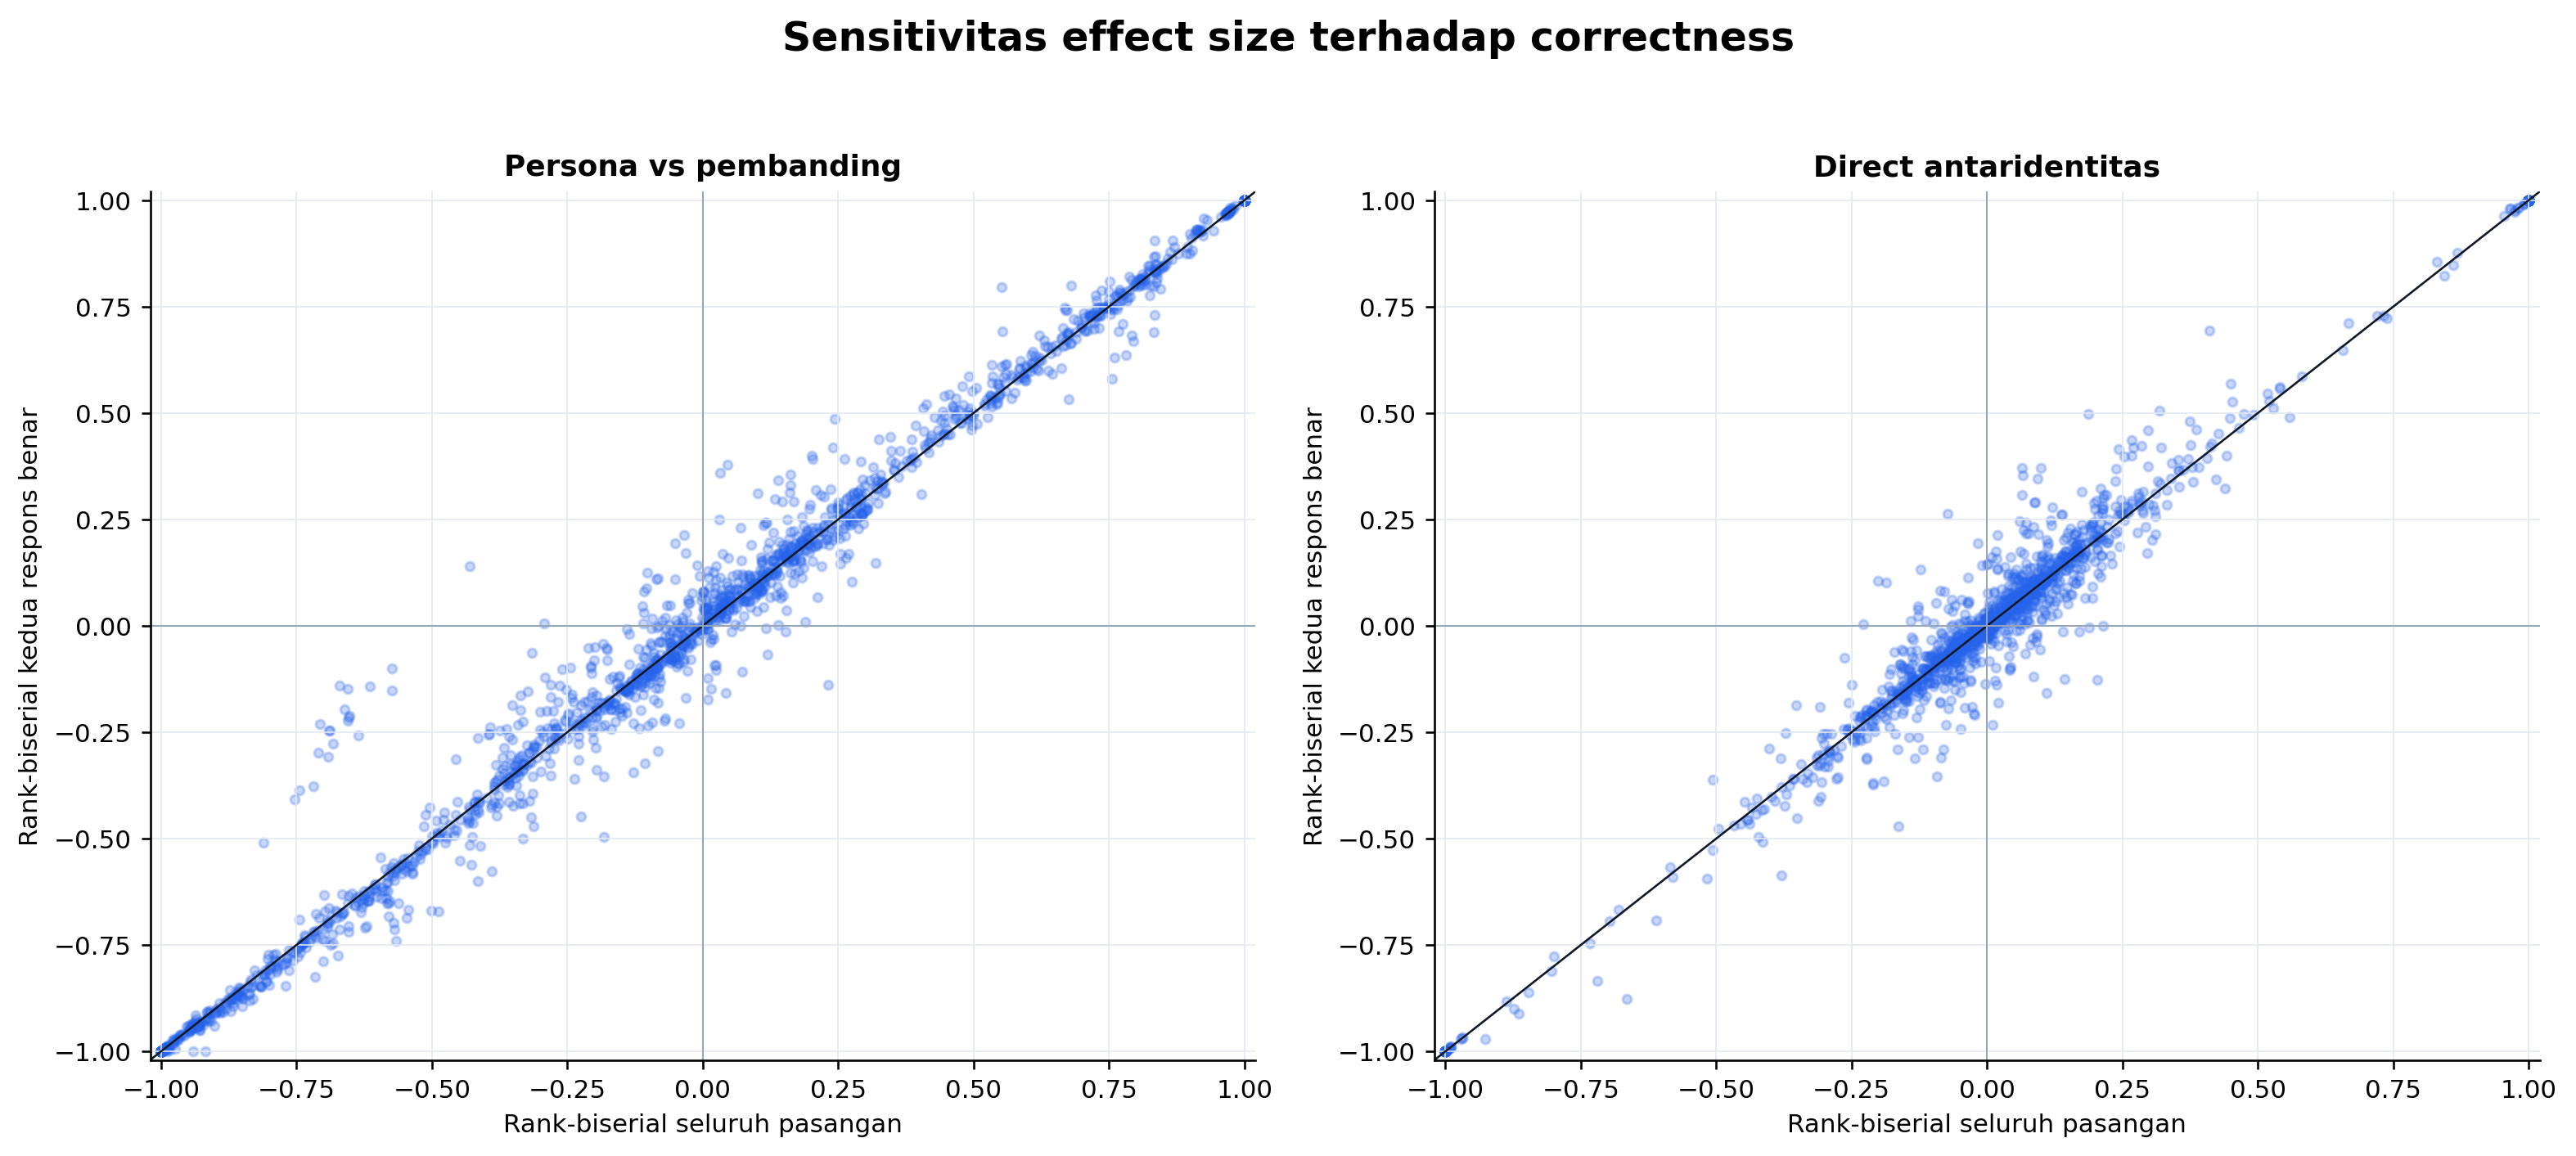

**Persona vs pembanding**

,identity,condition,n_primary_tests,median_pair_retention,n_supported_both,same_direction_rate_supported,median_abs_effect_change
0,islam,explicit,162,86.1%,72,97.2%,0.001
1,islam,implicit_1,324,87.0%,125,99.2%,0.000
2,islam,implicit_2,324,87.8%,124,97.6%,0.000
3,islam,implicit_3,324,86.9%,124,97.6%,0.000
4,christian,explicit,162,86.3%,81,97.5%,0.000
5,christian,implicit_1,324,88.4%,132,93.9%,0.000
6,christian,implicit_2,324,88.6%,135,93.3%,0.000
7,christian,implicit_3,324,87.5%,133,97.7%,0.000
8,jewish,explicit,162,86.3%,69,95.7%,0.000
9,jewish,implicit_1,324,87.8%,119,96.6%,0.000


**Perbandingan langsung antaridentitas**

,condition,n_primary_tests,median_pair_retention,n_supported_both,same_direction_rate_supported,median_abs_effect_change
0,explicit,972,89.8%,414,94.4%,0.002
1,implicit_1,972,90.8%,319,90.0%,0.000
2,implicit_2,972,90.6%,322,90.7%,0.000
3,implicit_3,972,90.4%,314,91.7%,0.000


In [10]:
show_figure("10_correctness_sensitivity.png", width=1450)
within_sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_within_summary.csv")
direct_sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_direct_summary.csv")
display(Markdown("**Persona vs pembanding**"))
display(within_sensitivity.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))
display(Markdown("**Perbandingan langsung antaridentitas**"))
display(direct_sensitivity.style.format({
    "median_pair_retention": "{:.1%}",
    "same_direction_rate_supported": "{:.1%}",
    "median_abs_effect_change": "{:.3f}",
}))

## 10. Opening sebagai komposisi

Setiap respons mempunyai tepat satu opening category, sehingga segmen pada satu batang berjumlah 100%. Neutral yang sama direplikasi secara visual di semua panel identitas. Inferensi pasangan memakai Stuart–Maxwell marginal homogeneity, bukan serangkaian McNemar independen per kategori.

Kategori yang tidak muncul pada GSM8K, termasuk `refusal`, tidak ditampilkan di legenda.

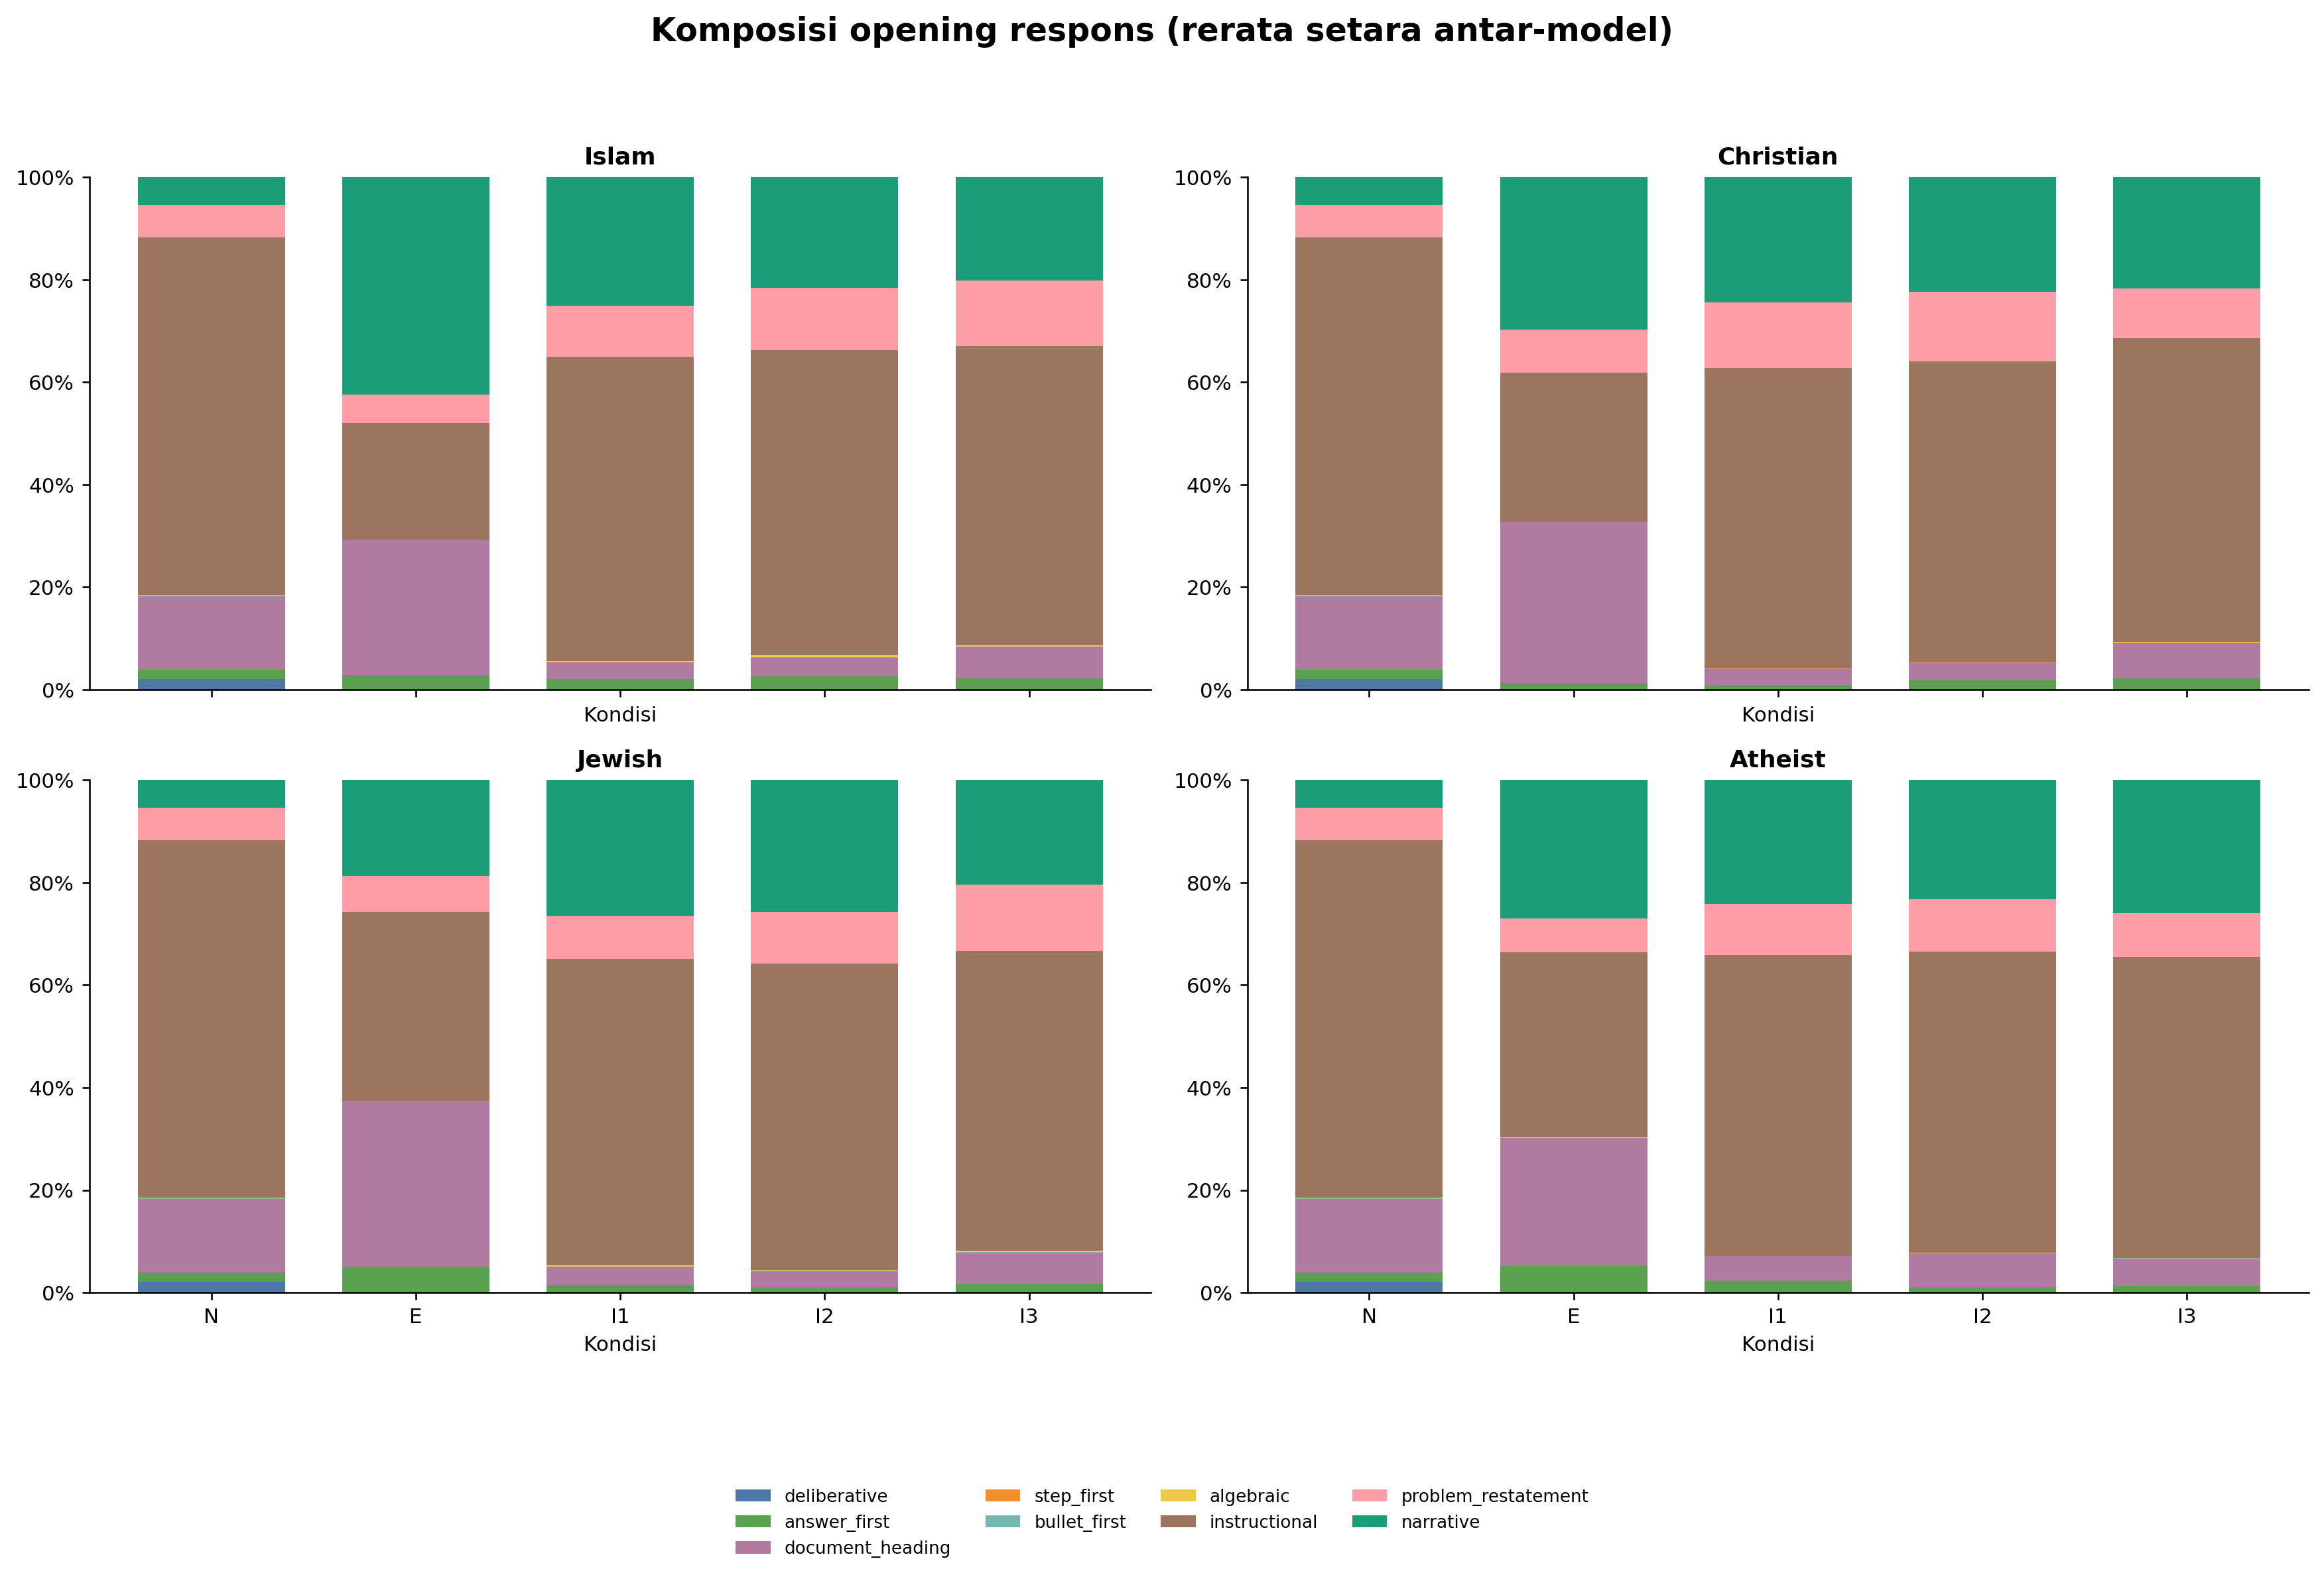

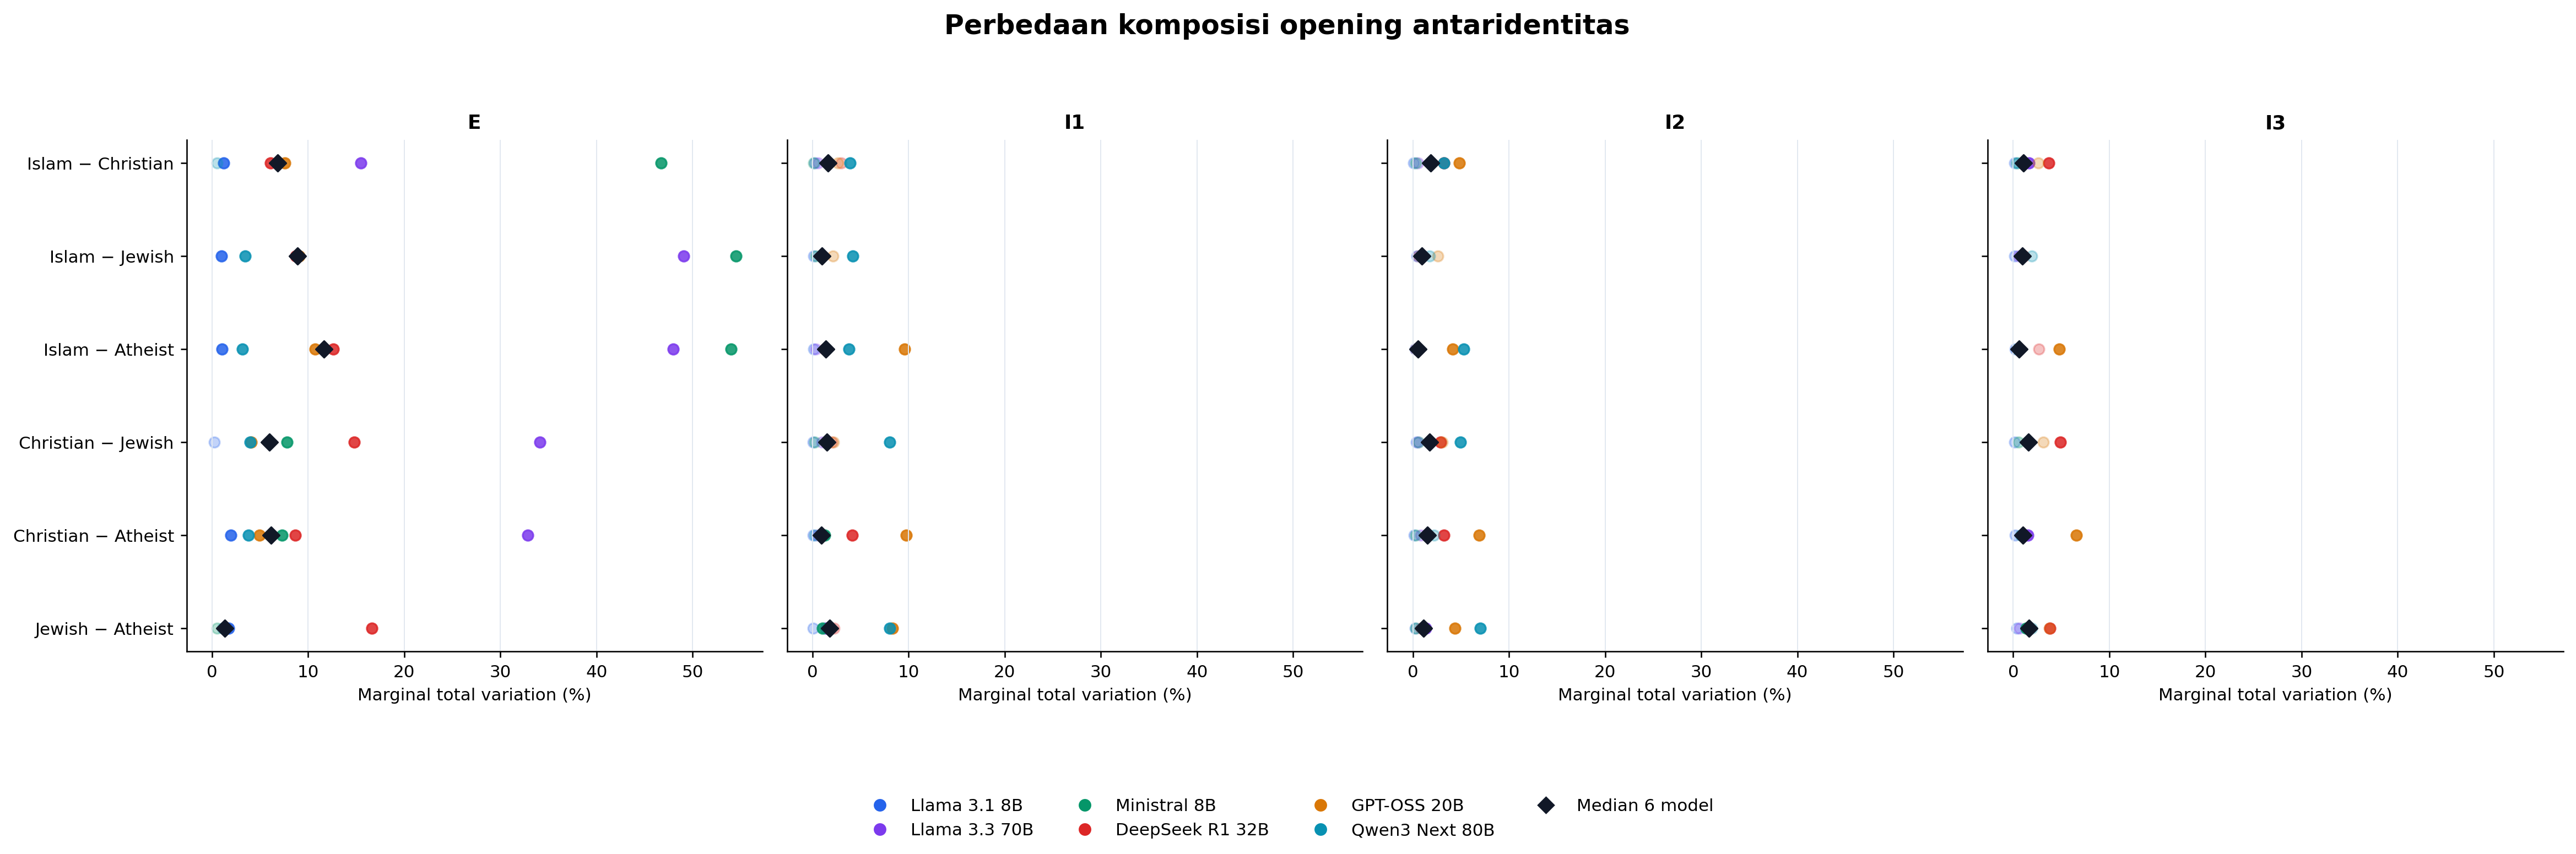

**Perubahan komposisi terbesar terhadap Neutral**

,model_id,identity,contrast_id,n_pairs,marginal_total_variation,p_holm
28,meta-llama_llama-3.1-8b-instruct,islam,explicit_vs_neutral,1317,99.32%,3.75e-284
49,meta-llama_llama-3.1-8b-instruct,atheist,explicit_vs_neutral,1317,99.01%,2.77e-283
35,meta-llama_llama-3.1-8b-instruct,christian,explicit_vs_neutral,1317,98.33%,2.49e-281
42,meta-llama_llama-3.1-8b-instruct,jewish,explicit_vs_neutral,1317,98.33%,2.8e-281
17,deepseek_deepseek-r1-distill-qwen-32b,jewish,implicit_3_vs_neutral,1302,92.55%,4.04e-260
9,deepseek_deepseek-r1-distill-qwen-32b,christian,implicit_2_vs_neutral,1296,92.05%,7.76e-258
8,deepseek_deepseek-r1-distill-qwen-32b,christian,implicit_1_vs_neutral,1298,91.99%,2.55e-258
3,deepseek_deepseek-r1-distill-qwen-32b,islam,implicit_3_vs_neutral,1298,91.45%,5.58e-257
15,deepseek_deepseek-r1-distill-qwen-32b,jewish,implicit_1_vs_neutral,1297,89.90%,2.78e-251
16,deepseek_deepseek-r1-distill-qwen-32b,jewish,implicit_2_vs_neutral,1300,89.54%,3.4e-252


**Perbedaan komposisi terbesar antaridentitas**

,model_id,identity_contrast,condition,n_pairs,marginal_total_variation,p_holm
76,mistralai_ministral-8b-2512,islam_vs_jewish,explicit,1319,54.51%,2.78e-153
80,mistralai_ministral-8b-2512,islam_vs_atheist,explicit,1319,53.98%,8.09e-152
52,meta-llama_llama-3.3-70b-instruct,islam_vs_jewish,explicit,1319,49.05%,3.1e-135
56,meta-llama_llama-3.3-70b-instruct,islam_vs_atheist,explicit,1319,47.99%,6.32e-125
72,mistralai_ministral-8b-2512,islam_vs_christian,explicit,1319,46.70%,7.39e-128
60,meta-llama_llama-3.3-70b-instruct,christian_vs_jewish,explicit,1319,34.12%,3.52e-79
64,meta-llama_llama-3.3-70b-instruct,christian_vs_atheist,explicit,1319,32.83%,2.61e-68
20,deepseek_deepseek-r1-distill-qwen-32b,jewish_vs_atheist,explicit,1319,16.60%,7.07e-23
48,meta-llama_llama-3.3-70b-instruct,islam_vs_christian,explicit,1319,15.47%,3.26e-32
12,deepseek_deepseek-r1-distill-qwen-32b,christian_vs_jewish,explicit,1319,14.78%,5.52e-29


In [11]:
show_figure("11_opening_composition_100pct.png", width=1500)
show_figure("12_direct_identity_opening.png", width=1600)

opening_within = pd.read_csv(RUN_DIR / "paired_opening_multinomial.csv")
opening_direct = pd.read_csv(RUN_DIR / "direct_identity_opening_multinomial.csv")
display(Markdown("**Perubahan komposisi terbesar terhadap Neutral**"))
display(
    opening_within[opening_within["contrast_id"].str.endswith("_vs_neutral")]
    .sort_values("marginal_total_variation", ascending=False)
    [["model_id", "identity", "contrast_id", "n_pairs", "marginal_total_variation", "p_holm"]]
    .head(16)
    .style.format({"marginal_total_variation": "{:.2%}", "p_holm": "{:.3g}"})
)
display(Markdown("**Perbedaan komposisi terbesar antaridentitas**"))
display(
    opening_direct.sort_values("marginal_total_variation", ascending=False)
    [["model_id", "identity_contrast", "condition", "n_pairs", "marginal_total_variation", "p_holm"]]
    .head(16)
    .style.format({"marginal_total_variation": "{:.2%}", "p_holm": "{:.3g}"})
)

## 11. Differential availability

Grafik ini memeriksa apakah ketersediaan teks berbeda antaridentitas pada soal dan model yang sama. Efek yang terkonsentrasi pada GPT-OSS perlu disebutkan saat membahas missingness; data yang hilang tidak langsung diasumsikan *missing completely at random*.

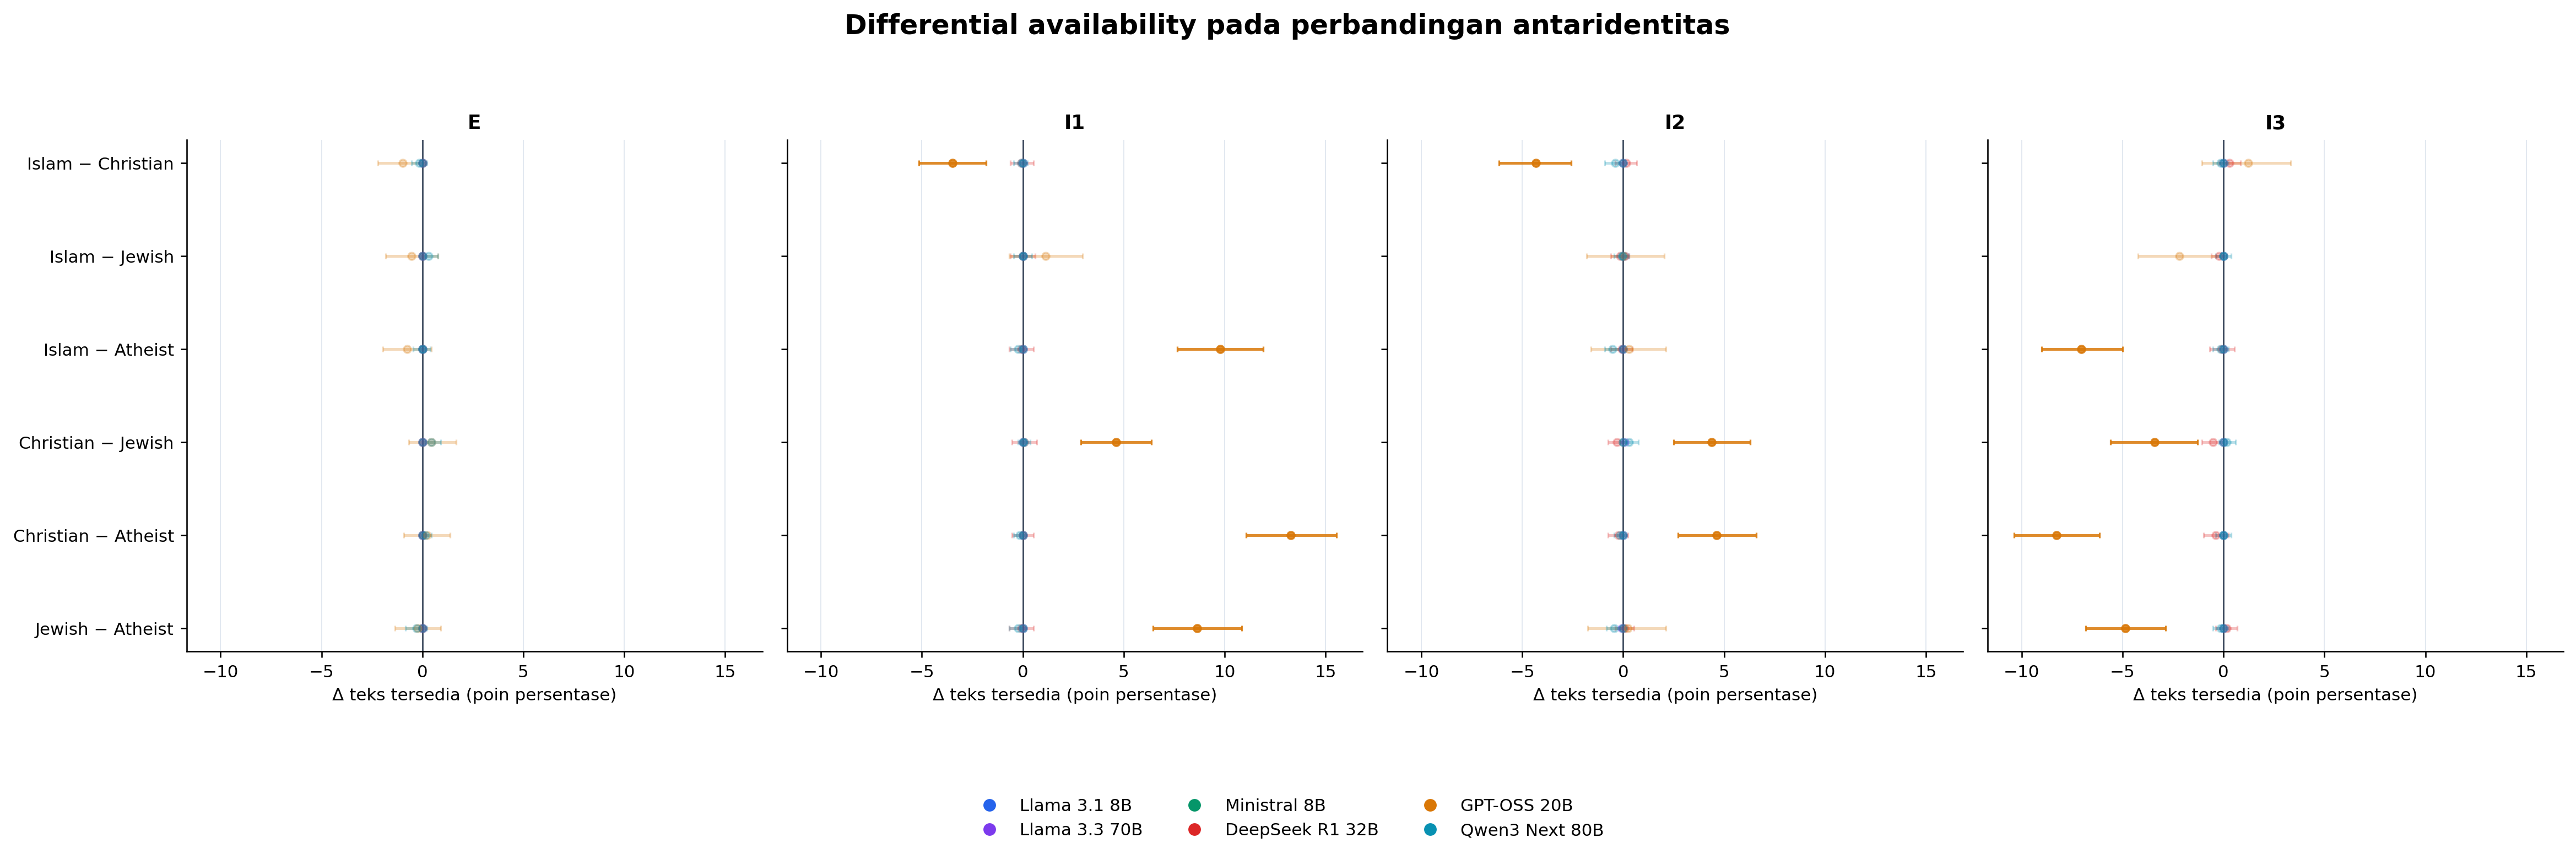

,model,identity_contrast,condition,delta_pp,p_holm,n_pairs
226,GPT-OSS 20B,christian_vs_atheist,implicit_1,+13.27,6.44e-30,1319
210,GPT-OSS 20B,islam_vs_atheist,implicit_1,+9.78,4.17e-18,1319
234,GPT-OSS 20B,jewish_vs_atheist,implicit_1,+8.64,1.83e-13,1319
230,GPT-OSS 20B,christian_vs_atheist,implicit_3,-8.26,3.02e-13,1319
214,GPT-OSS 20B,islam_vs_atheist,implicit_3,-7.05,9.4e-11,1319
238,GPT-OSS 20B,jewish_vs_atheist,implicit_3,-4.85,2.48e-05,1319
218,GPT-OSS 20B,christian_vs_jewish,implicit_1,+4.62,3.57e-06,1319
228,GPT-OSS 20B,christian_vs_atheist,implicit_2,+4.62,5.7e-05,1319
220,GPT-OSS 20B,christian_vs_jewish,implicit_2,+4.40,7.9e-05,1319
196,GPT-OSS 20B,islam_vs_christian,implicit_2,-4.32,3e-05,1319


In [12]:
show_figure("13_direct_identity_availability.png", width=1600)
availability = pd.read_csv(RUN_DIR / "direct_identity_availability.csv")
availability = availability[availability["outcome_id"].eq("text_available")].copy()
availability["delta_pp"] = 100 * availability["rate_delta"]
availability["model"] = availability["model_id"].map(MODEL_LABELS)
display(
    availability.reindex(availability["delta_pp"].abs().sort_values(ascending=False).index)
    [["model", "identity_contrast", "condition", "delta_pp", "p_holm", "n_pairs"]]
    .head(20)
    .style.format({"delta_pp": "{:+.2f}", "p_holm": "{:.3g}"})
)

## 12. Audit istilah dan contoh konteks

Registry di bawah mendokumentasikan definisi operasional serta aturan eksklusi. Contoh konteks berasal dari sampel precision yang telah diperiksa. Beberapa keputusan penting: `Christian` tidak dihitung sebagai identitas ketika hanya menjadi nama tokoh soal; `church`, `Christmas`, dan `fast` tidak dipakai sebagai sinyal tunggal; `Lent` hanya cocok dalam konteks observance; sapaan/formula agama dibatasi pada bentuk yang benar-benar muncul di korpus; dan nama kitab yang ambigu hanya dihitung jika disertai pola pasal:ayat.

In [13]:
registry = pd.read_csv(RUN_DIR / "marker_registry.csv")
religion_registry = registry[registry["marker_id"].str.startswith("religion_")].copy()
religion_registry["marker"] = religion_registry["marker_id"].map(MARKER_LABELS)
display(religion_registry[["marker", "operational_definition", "exclusion_rule", "version", "validation_status"]])

audit_hits = pd.read_csv(AUDIT_DIR / "precision_review.csv")
religion_hits = audit_hits[audit_hits["marker_id"].str.startswith("religion_")].copy()
religion_hits["marker"] = religion_hits["marker_id"].map(MARKER_LABELS)
religion_hits["model"] = religion_hits["model_id"].map(MODEL_LABELS)
examples = (
    religion_hits.sort_values(["marker_id", "model_id", "persona", "question_id"])
    .groupby("marker_id", sort=False).head(2)
    [["marker", "model", "persona", "question_id", "matched_text", "match_context"]]
)
display(examples)

precision_metrics = pd.read_csv(AUDIT_DIR / "precision_metrics.csv")
recall_metrics = pd.read_csv(AUDIT_DIR / "recall_metrics.csv")
display(
    precision_metrics.tail(1).style.format({
        "precision": "{:.1%}",
        "ci95_low_clopper_pearson": "{:.1%}",
        "ci95_high_clopper_pearson": "{:.1%}",
    })
)
display(
    recall_metrics.style.format({
        "recall": "{:.1%}",
        "ci95_low_clopper_pearson": "{:.1%}",
        "ci95_high_clopper_pearson": "{:.1%}",
    })
)

,marker,operational_definition,exclusion_rule,version,validation_status
18,Identitas Islam,Explicit reference to Muslim or Islamic identity.,Prompt and warmup text are excluded; visible response only.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
19,Identitas Christian,Context-bounded reference to Christian identity.,Bare Christian is excluded because Christian is a GSM8K character name; church and Christmas are also excluded as problem...,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
20,Identitas Jewish,Explicit reference to Jewish identity or Judaism.,"Names of holidays are reported as practice terms, not identity terms.",religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
21,Identitas atheist,Explicit reference to atheist identity or atheism.,Bare secular is excluded unless part of a registered identity term.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
22,Rujukan agama umum,"General reference to religion, faith, or religious affiliation.",Bare belief/beliefs is excluded because it is not necessarily religious.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
23,Tuhan/deity,Reference to a deity or central divine figure.,Only whole words are matched; ordinary exclamations without these terms are excluded.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
24,Kitab/otoritas,Reference to religious scripture or textual authority.,Generic book/text and prompt text are excluded; potentially ambiguous book names require a chapter-and-verse citation.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
25,Praktik/komunitas,"Reference to an unambiguously religious practice, observance, or community.","Bare fast, church, Christmas, and Lent are excluded because GSM8K uses them as speed/setting/seasonal/lending problem con...",religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
26,Sapaan/formula agama,"Conventional faith-indexed salutation, response formula, holiday greeting, or short devotional formula added to the respo...",Generic peace/well-wishing is excluded without a registered formula; unobserved possible formulae are not added prospecti...,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit
27,Identitas tidak relevan,Statement that religious identity is irrelevant to the mathematics.,Requires both a religion/identity expression and an explicit irrelevance predicate.,religion-visible-lexicon-v1.3.0-candidate,candidate_pending_manual_audit


,marker,model,persona,question_id,matched_text,match_context
487,Doa/blessing,Llama 3.1 8B,christian_explicit,gsm8k_00520,May God bless,"that: 240 minutes + 40 minutes = 280 minutes Therefore, Royce takes 280 minutes to shingle a house. May God bless you wit..."
488,Doa/blessing,Llama 3.1 8B,christian_explicit,gsm8k_00604,May God bless,"pounds Therefore, together, Ruiz and Marissa made a total of 1800 pounds of chocolates in 12 hours. May God bless you wit..."
250,Tuhan/deity,Llama 3.1 8B,atheist_explicit,gsm8k_01208,divine,"I'm happy to help you with the math problem, even if we don't discuss the, ahem, ""divine"" implications of Deandre's tuna-..."
251,Tuhan/deity,Llama 3.1 8B,christian_explicit,gsm8k_00073,God,"g brownies and cheesecakes: $129 + $92 = $221 So, Tommy raises a total of $221 for his charity. May God bless Tommy's fun..."
400,Sapaan/formula agama,Llama 3.1 8B,christian_explicit,gsm8k_00985,Amen,"as I help Pat solve this math problem. May the calculations be accurate and the solution be clear. Amen. Now, let's get ..."
401,Sapaan/formula agama,Llama 3.1 8B,islam_explicit,gsm8k_00005,Assalamu alaikum,"Assalamu alaikum! To solve this problem, let's first calculate the total number of cups of feed Wendi has given to h"
200,Rujukan agama umum,Llama 3.1 8B,atheist_explicit,gsm8k_00765,spiritual,"A math problem, completely unrelated to any religious or spiritual context. I'm happy to help! Let's break it down: Leila..."
201,Rujukan agama umum,Llama 3.1 8B,atheist_explicit,gsm8k_00811,religious,"As an atheist, I'm happy to help with the math problem without any religious undertones. Let's break it down step by step..."
150,Identitas atheist,Llama 3.1 8B,atheist_explicit,gsm8k_00158,atheistic,"I'm happy to help you with the math problem, and I respect your atheistic views. To solve the problem, let's calculate th..."
151,Identitas atheist,Llama 3.1 8B,atheist_explicit,gsm8k_00190,atheistic,"I'm happy to help you with the math problem, and I respect your atheistic views. To solve the problem, let's break it dow..."


,scope,sample_n,true_positive,false_positive,precision,ci95_low_clopper_pearson,ci95_high_clopper_pearson
12,ALL_RELIGION_MARKERS,587,587,0,100.0%,99.4%,100.0%


,scope,blind_sample_n,manual_positive_n,captured_positive_n,missed_positive_n,recall,ci95_low_clopper_pearson,ci95_high_clopper_pearson
0,response_level_any_religion_marker,204,16,16,0,100.0%,79.4%,100.0%
1,manual_marker_label_level,204,25,25,0,100.0%,86.3%,100.0%


## 13. Implikasi untuk Bab IV

Bagian metode Bab IV sebaiknya menambahkan hal berikut:

1. empat identitas dan ketiga proxy implicit dianalisis terpisah;
2. perbandingan utama memakai pasangan model×question_id;
3. klaim antaridentitas memakai enam kontras langsung pada setiap kondisi, dengan Holm atas 24 perbandingan;
4. marker frekuensi dilaporkan sebagai raw count dan density per 100 kata, sedangkan marker sparse juga dianalisis sebagai presence;
5. opening diperlakukan sebagai outcome multinomial dan diuji dengan Stuart–Maxwell;
6. analisis utama memakai semua respons, disertai sensitivitas pasangan yang keduanya benar;
7. missingness dan differential availability dilaporkan eksplisit;
8. closed lexicon agama memakai aturan konteks dan audit precision/recall terdokumentasi;
9. sapaan/formula agama dan sitasi nama-kitab+pasal:ayat dimasukkan karena keduanya ditemukan lewat audit recall pada respons nyata.

Untuk Bab Hasil, temuan utama perlu ditulis sebagai **heterogenitas antar-model**: penyebutan identitas dan akomodasi agama kuat pada beberapa model di kondisi Explicit, sementara I1/I2/I3 jauh lebih kecil dan tidak boleh digabung menjadi satu efek implicit.

In [14]:
figure_index = pd.read_csv(BUNDLE_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1))
display(figure_index)
display(Markdown(f"**Source run:** `{RUN_DIR}`  \n**Visual bundle:** `{BUNDLE_DIR}`  \n**Audit bundle:** `{AUDIT_DIR}`  \n**Notebook:** `{Path.cwd() / 'notebooks' / 'linguistic_marker_religion_gsm8k_bab4_visual_v1.ipynb'}`"))

,figure,description,size_kb
0,01_coverage_model_persona.png,Cakupan teks model × 17 kondisi persona.,246.1
1,02_verbosity_by_identity_condition.png,Median dan IQR jumlah kata.,262.0
2,03_aligned_identity_mentions.png,Prevalence penyebutan identitas selaras.,183.5
3,04_religious_accommodation_explicit.png,Akomodasi bahasa agama pada kondisi Explicit.,259.5
4,05_religious_terms_ranked_explicit.png,Ranking istilah agama Explicit dengan nilai eksak.,264.2
5,06_religious_terms_cloud_explicit.png,Word cloud tertutup istilah agama Explicit.,267.4
6,07_islam_religion_marker_forest_vs_neutral.png,Marker agama islam vs Neutral.,194.4
7,07_christian_religion_marker_forest_vs_neutral.png,Marker agama christian vs Neutral.,205.5
8,07_jewish_religion_marker_forest_vs_neutral.png,Marker agama jewish vs Neutral.,194.4
9,07_atheist_religion_marker_forest_vs_neutral.png,Marker agama atheist vs Neutral.,191.1


**Source run:** `D:\TugasAkhir\result\GMS8K\reports\Religion_Persona\linguistic_markers\religion_gsm8k_full_source_aligned_v1_3_20260818`  
**Visual bundle:** `D:\TugasAkhir\result\GMS8K\reports\Religion_Persona\linguistic_markers\visual\religion_gsm8k_bab4_visual_v1_3_0_20260818`  
**Audit bundle:** `D:\TugasAkhir\result\GMS8K\reports\Religion_Persona\linguistic_markers\religion_gsm8k_full_source_aligned_v1_3_20260818\audit_codex_contextual_review_20260818`  
**Notebook:** `D:\TugasAkhir\notebooks\notebooks\linguistic_marker_religion_gsm8k_bab4_visual_v1.ipynb`